# Madrid air quality, 2001–2024

An end-to-end analysis of **24 years of hourly air-quality data from Madrid's 24 monitoring stations** (METRAQ dataset, ~64 million rows): data quality and imputation, long-run and cyclical patterns, two network views of the sensor grid, parallel computation of 576 correlation matrices, and a model that forecasts hourly NO2 two years ahead.

**Contents**

1. Data loading and inspection
2. Missingness and data quality
3. Imputation
4. Temporal patterns
5. Spatial sensor network
6. Correlation network
7. Parallel computation of correlations
8. Forecasting NO2
9. Key findings in five figures

Francesca D'Aloia Cascone, with Andrea Scarso. Advanced Coding for Data Analytics, LUISS Guido Carli, 2025/26. Setup and run instructions are in the [README](README.md).


# Environment setup


In [89]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import networkx as nx
from networkx.algorithms.community import greedy_modularity_communities
from datasets import load_dataset
import os
import time
import multiprocessing
from pathlib import Path

# 1. Data loading and inspection

This project makes use of the dataset METRAQ-Air-Quality, which provides hourly measurements from January 2001 to December 2024.

[1] - David María-Arribas et al. "METRAQ Air Quality dataset." https://huggingface.co/datasets/dmariaa70/METRAQ-Air-Quality


In [2]:
ds = load_dataset("dmariaa70/METRAQ-Air-Quality")

Resolving data files:   0%|          | 0/24 [00:00<?, ?it/s]

In [3]:
df = pd.concat([split.to_pandas() for split in ds.values()])

In [4]:
print(f"Shape  : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Memory : {df.memory_usage(deep=True).sum() / 1e6:.2f} MB")
df.head()

Shape  : 64,881,744 rows × 9 columns
Memory : 15620.07 MB


,sensor_id,sensor_name,utm_x,utm_y,magnitude_id,magnitude_name,entry_date,value,is_interpolated
0,28079004,Plaza de España,439579.3291,4475049.263,1,SO2,2001-01-01,21.0,False
1,28079004,Plaza de España,439579.3291,4475049.263,6,CO,2001-01-01,1.0,False
2,28079004,Plaza de España,439579.3291,4475049.263,7,NO,2001-01-01,83.0,False
3,28079004,Plaza de España,439579.3291,4475049.263,8,NO2,2001-01-01,50.0,False
4,28079004,Plaza de España,439579.3291,4475049.263,12,NOX,2001-01-01,177.0,False


### Defining the 3 main categories and their variables
- Up to 14 **pollutants**
- Up to 7 **meteorological** parameters
- 3 **traffic** metrics aggregated using 5 Interpolation methods (-->3x5)


In [5]:
POLLUTANTS = [
    'SO2', 'CO', 'NO', 'NO2', 'NOX',
    '<PM10', '<PM2.5', 'O3',
    'TOLUENO', 'BENCENO', 'ETILBENCENO',
    'HIDROCARBS_TOTALES', 'METANO', 'HIDROCARBS_NO_METANICOS'
]

METEO = ['VV', 'DV', 'TEMP', 'HR', 'PRE', 'RS', 'PRECIPITACION']

TRAFFIC_PREFIXES = ('TI_', 'SP_', 'OC_')

def classify_variable(name: str) -> str:
    if name in POLLUTANTS:
        return 'pollutant'
    if name in METEO:
        return 'meteo'
    if any(name.startswith(prefix) for prefix in TRAFFIC_PREFIXES):
        return 'traffic'
    return 'unknown'


def add_category_column(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df['category'] = (
        df['magnitude_name']
        .astype(str)
        .map(classify_variable)
        .astype('category')
    )
    return df

df = add_category_column(df)

# Summary
cat_counts = df['category'].value_counts()
print("Rows per category:")
print(cat_counts.to_string())
print()

# List variables per category
for cat in ['pollutant', 'meteo', 'traffic', 'unknown']:
    names = sorted(df.loc[df['category'] == cat, 'magnitude_name'].unique())
    print(f"{cat:12s} ({len(names):2d}): {names}")

Rows per category:
category
traffic      30507768
pollutant    25535832
meteo         8838144

pollutant    (14): ['<PM10', '<PM2.5', 'BENCENO', 'CO', 'ETILBENCENO', 'HIDROCARBS_NO_METANICOS', 'HIDROCARBS_TOTALES', 'METANO', 'NO', 'NO2', 'NOX', 'O3', 'SO2', 'TOLUENO']
meteo        ( 7): ['DV', 'HR', 'PRE', 'PRECIPITACION', 'RS', 'TEMP', 'VV']
traffic      (15): ['OC_IDW', 'OC_KRIGING', 'OC_RBF_GAUSSIAN', 'OC_RBF_LINEAR', 'OC_RBF_MULTIQUADRIQ', 'SP_IDW', 'SP_KRIGING', 'SP_RBF_GAUSSIAN', 'SP_RBF_LINEAR', 'SP_RBF_MULTIQUADRIQ', 'TI_IDW', 'TI_KRIGING', 'TI_RBF_GAUSSIAN', 'TI_RBF_LINEAR', 'TI_RBF_MULTICUADRIC']
unknown      ( 0): []


**About Traffic Variables** The dataset includes three traffic metrics: Occupancy (OC), Speed (SP), and Traffic Intensity (TI), each provided through five interpolation methods (IDW, Kriging, and RBF with linear, multiquadric and Gaussian kernels), resulting in multiple derived traffic variables.


#### Inspecting data-types


In [6]:
def inspect_schema(df: pd.DataFrame) -> pd.DataFrame:
    summary = pd.DataFrame({
        'dtype'       : df.dtypes,
        'nulls'       : df.isnull().sum(),
        'null_%'      : (df.isnull().mean() * 100).round(2),
        'unique'      : df.nunique()
    })
    print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
    print(summary.to_string())
    return summary


schema = inspect_schema(df)

Shape: 64,881,744 rows × 10 columns
                         dtype  nulls  null_%    unique
sensor_id               object      0     0.0        24
sensor_name             object      0     0.0        24
utm_x                  float64      0     0.0        24
utm_y                  float64      0     0.0        24
magnitude_id             int32      0     0.0        36
magnitude_name          object      0     0.0        36
entry_date       datetime64[s]      0     0.0    210384
value                  float64      0     0.0  26832544
is_interpolated           bool      0     0.0         2
category              category      0     0.0         3


### Sensors of the detections


In [7]:
def sensor_inventory(df):
    coords = (
        df.groupby('sensor_id', observed=True)
        .agg(
            sensor_name    = ('sensor_name',    'first'),
            utm_x          = ('utm_x',          'first'),
            utm_y          = ('utm_y',          'first'),
            n_variables    = ('magnitude_name', 'nunique'),
            n_observations = ('value',          'count'),
            date_first     = ('entry_date',     'min'),
            date_last      = ('entry_date',     'max'),
        )

        .sort_values('n_observations', ascending=False)
        .reset_index()


    )
    print(f"Unique sensors: {len(coords)}")
    return coords


sensors = sensor_inventory(df)
sensors.head(24)

Unique sensors: 24


,sensor_id,sensor_name,utm_x,utm_y,n_variables,n_observations,date_first,date_last
0,28079024,Casa de Campo,436598.5637,4474571.618,36,4321797,2001-01-01,2024-12-31 23:00:00
1,28079008,Escuelas Aguirre,442117.2366,4474770.696,36,4207917,2001-01-01,2024-12-31 23:00:00
2,28079018,Farolillo,437891.6961,4471832.769,32,3445221,2001-01-01,2024-12-31 23:00:00
3,28079038,Cuatro Caminos,440033.4632,4477450.211,31,3217293,2001-01-01,2024-12-31 23:00:00
4,28079035,Plaza del Carmen,440346.3619,4474524.357,28,2901717,2001-01-01,2024-12-31 23:00:00
5,28079036,Moratalaz,445245.5130,4473237.349,28,2866653,2001-01-01,2024-12-31 23:00:00
6,28079055,Urb. Embajada,450778.8839,4479238.863,32,2849181,2010-01-01,2024-12-31 23:00:00
7,28079004,Plaza de España,439579.3291,4475049.263,27,2682549,2001-01-01,2024-12-31 23:00:00
8,28079011,Ramón y Cajal,442564.0457,4478088.595,28,2665053,2001-01-01,2024-12-31 23:00:00
9,28079039,Barrio del Pilar,439689.0496,4481081.619,27,2656269,2001-01-01,2024-12-31 23:00:00


## Analytics with respect to time


In [8]:
def time_coverage(df: pd.DataFrame) -> pd.DataFrame:
    overall_min = df['entry_date'].min()
    overall_max = df['entry_date'].max()
    span_days   = (overall_max - overall_min).days

    print("Overall time coverage")
    print(f"  First record : {overall_min}")
    print(f"  Last record  : {overall_max}")
    print(f"  Span         : {span_days:,} days ({span_days / 365:.1f} years)")
    print()

    per_cat = (
        df.groupby('category', observed=True)['entry_date']
        .agg(first='min', last='max', rows='count')
    )
    print("Per-category coverage:")
    print(per_cat.to_string())
    return per_cat


coverage = time_coverage(df)

Overall time coverage
  First record : 2001-01-01 00:00:00
  Last record  : 2024-12-31 23:00:00
  Span         : 8,765 days (24.0 years)

Per-category coverage:
               first                last      rows
category                                          
meteo     2019-01-01 2024-12-31 23:00:00   8838144
pollutant 2001-01-01 2024-12-31 23:00:00  25535832
traffic   2015-01-01 2024-12-31 23:00:00  30507768


### Rows per year per category
To check detections through each year


In [9]:
rows_per_year = (
    df.assign(year=df['entry_date'].dt.year)
    .groupby(['year', 'category'], observed=True)
    .size()
    .unstack(fill_value=0)
)
print("Rows per year per category:")
print(rows_per_year.to_string())

Rows per year per category:
category    meteo  pollutant  traffic
year                                 
2001            0     648240        0
2002            0     569400        0
2003            0     753360        0
2004            0     737856        0
2005            0     727080        0
2006            0     700800        0
2007            0     709560        0
2008            0     711504        0
2009            0     753360        0
2010            0    1349040        0
2011            0    1349040        0
2012            0    1326384        0
2013            0    1322760        0
2014            0    1322760        0
2015            0    1322760  3153600
2016            0    1326384  3162240
2017            0    1322760  3153600
2018            0    1314000  3153600
2019      1471680    1322760  3153600
2020      1475712    1343952  3162240
2021      1471680    1165080  3153528
2022      1471680    1156320  3153600
2023      1471680    1156320  3153600
2024      1475712    1

### Initial time-series
The time-series plots compare one highly covered sensor with the overall mean across all sensors for one pollutant, one meteorological variable, and one traffic variable.


Plotting NO2 for sensor_id=28079004


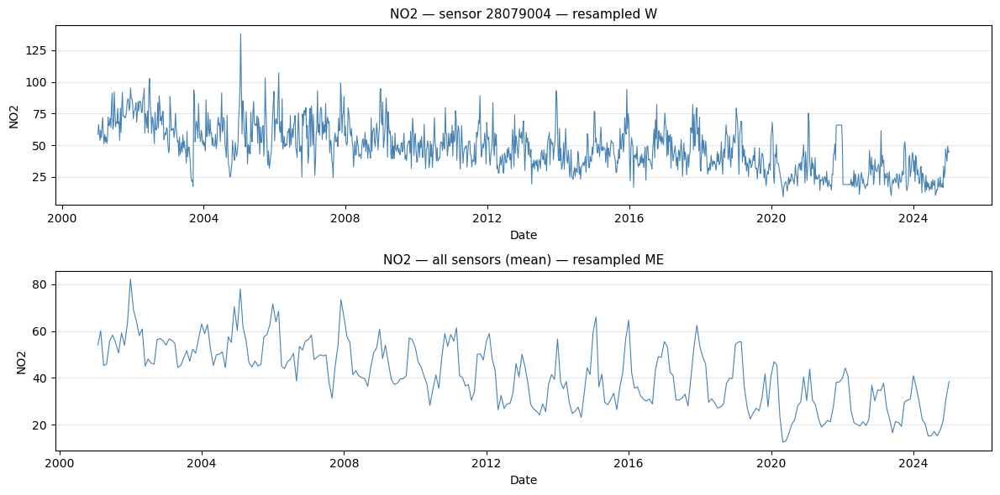

Plotting TEMP for sensor_id=28079004


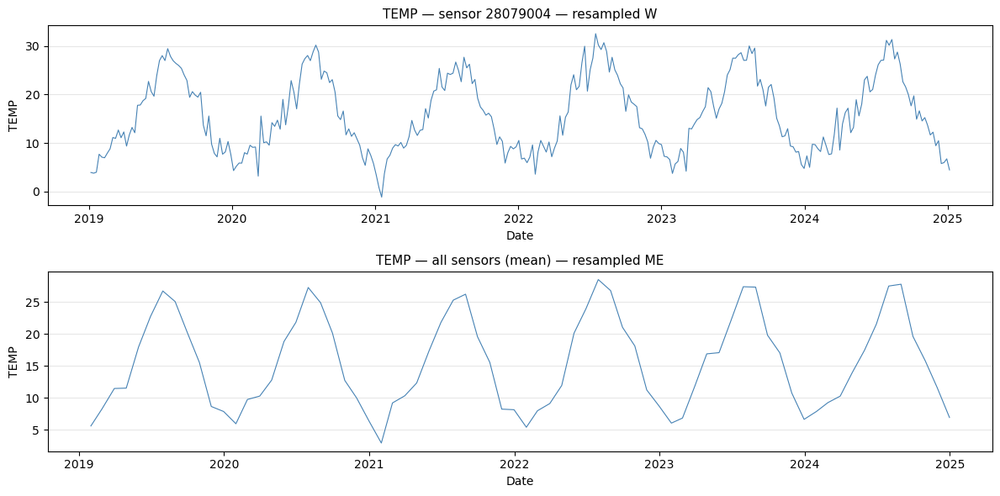

Plotting TI_IDW for sensor_id=28079004


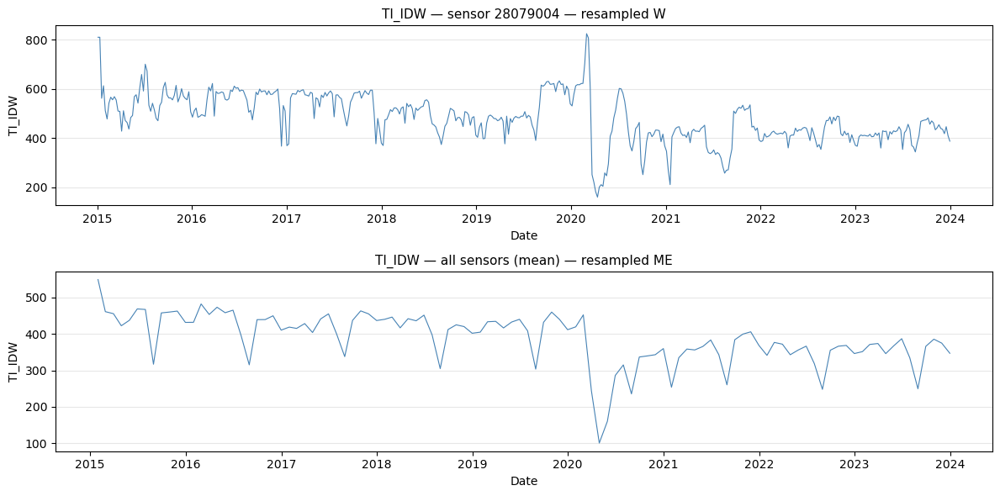

In [10]:
def plot_timeseries(df, variable, sensor_id=None, resample='D', ax=None):
    mask = df['magnitude_name'] == variable

    if sensor_id is not None:
        mask &= df['sensor_id'] == sensor_id

    series = (
        df.loc[mask]
        .set_index('entry_date')['value']
        .resample(resample)
        .mean()
    )

    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 3))

    label = f"sensor {sensor_id}" if sensor_id is not None else "all sensors (mean)"

    ax.plot(series.index, series.values, lw=0.8, color='steelblue')
    ax.set_title(f"{variable} — {label} — resampled {resample}", fontsize=11)
    ax.set_xlabel("Date")
    ax.set_ylabel(variable)
    ax.grid(axis='y', alpha=0.3)

    return ax


def get_most_observed_sensor(df, variable):
    return (
        df[df['magnitude_name'] == variable]
        .groupby('sensor_id', observed=True)['value']
        .count()
        .idxmax()
    )


def plot_variable_example(df, variable, sensor_resample='W', overall_resample='ME'):
    sensor_id = get_most_observed_sensor(df, variable)

    print(f"Plotting {variable} for sensor_id={sensor_id}")

    fig, axes = plt.subplots(2, 1, figsize=(12, 6))

    plot_timeseries(
        df,
        variable,
        sensor_id=sensor_id,
        resample=sensor_resample,
        ax=axes[0]
    )

    plot_timeseries(
        df,
        variable,
        sensor_id=None,
        resample=overall_resample,
        ax=axes[1]
    )

    plt.tight_layout()
    plt.show()


# Pollutant example
plot_variable_example(df, 'NO2', sensor_resample='W', overall_resample='ME')

# Meteorological example
plot_variable_example(df, 'TEMP', sensor_resample='W', overall_resample='ME')

# Traffic example
plot_variable_example(df, 'TI_IDW', sensor_resample='W', overall_resample='ME')

NO2 shows strong fluctuations but a visible long-term decline, suggesting decreasing pollution levels over time. TEMP displays a clear seasonal pattern, with regular yearly peaks and troughs. TI_IDW also shows temporal variation, including a sharp drop around 2020, likely reflecting an exceptional reduction in traffic intensity. **Together, these plots show that the dataset captures different temporal behaviours across categories: pollutant trends, meteorological seasonality, and traffic dynamics.**


## Descriptive statistics


In [11]:
def descriptive_stats(df):
    results = {}
    for cat in df['category'].cat.categories:
        subset = df[df['category'] == cat]
        stats = (
            subset.groupby('magnitude_name', observed=True)['value']
            .describe(percentiles=[.25, .5, .75, .95])
            .round(3)
        )


        results[cat] = stats
        print(stats.to_string())
    return results


stats_by_cat = descriptive_stats(df)

                    count     mean      std    min      25%      50%      75%      95%       max
magnitude_name                                                                                  
DV              1262592.0  132.106   82.993    0.0   56.000  121.190  208.207  263.000   360.000
HR              1262592.0   55.917   22.811 -149.0   37.043   55.000   74.367   93.000   369.000
PRE             1262592.0  936.029   56.599    0.0  939.623  943.269  947.504  954.684  1322.000
PRECIPITACION   1262592.0    0.032    0.382    0.0    0.000    0.000    0.000    0.000    38.000
RS              1262592.0  196.446  281.884   -2.0    1.000    8.426  351.439  829.095  3581.926
TEMP            1262592.0   15.472    8.861 -318.0    9.000   14.388   22.000   31.000   124.000
VV              1262592.0    0.892    4.409    0.0    0.024    0.633    1.156    2.552   989.000
                             count    mean      std  min   25%   50%   75%    95%     max
magnitude_name                       

### Distribution plots


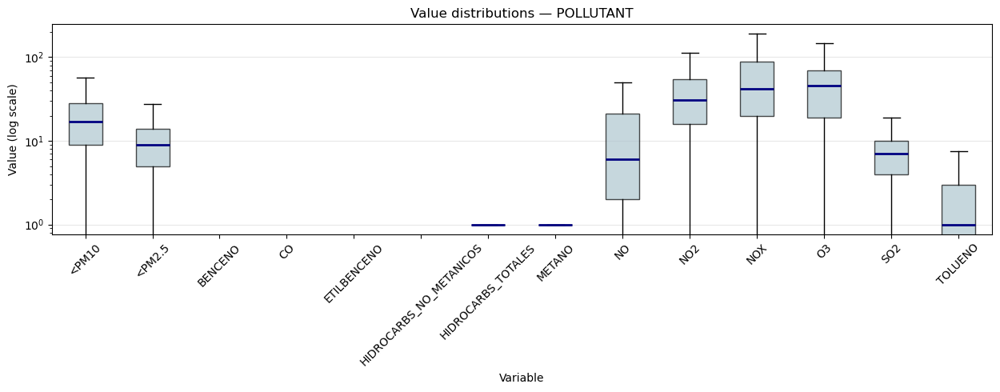

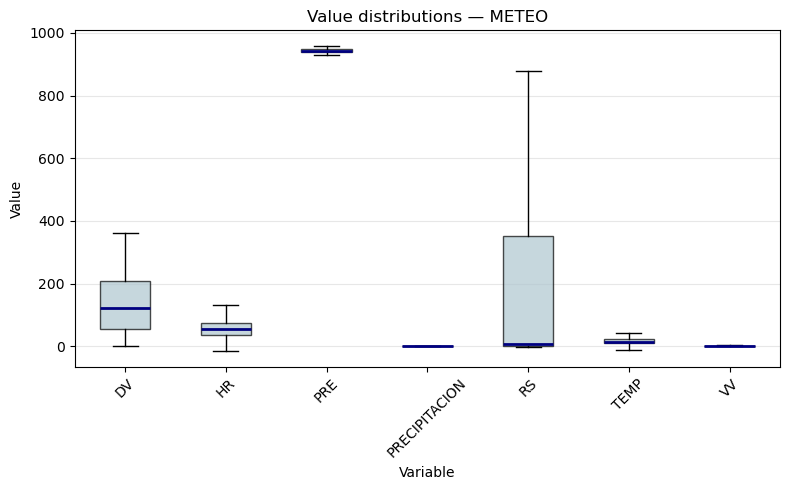

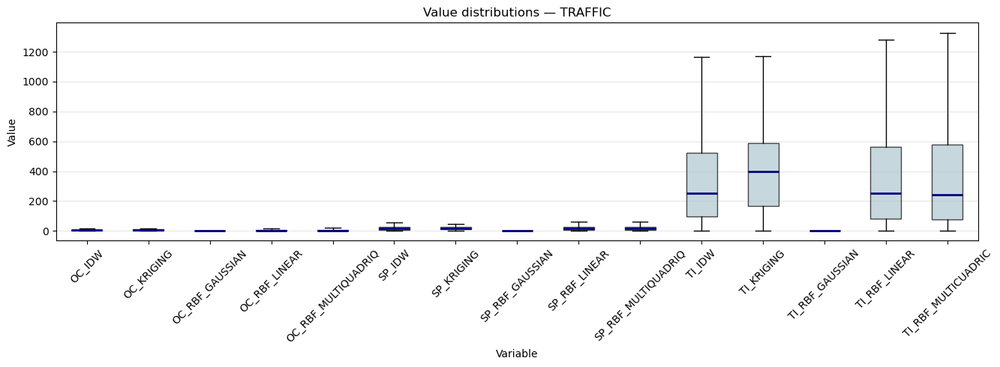

In [12]:
def plot_distributions(
    df, category, log_scale = False):
    subset = df[df['category'] == category].copy()
    variables = sorted(subset['magnitude_name'].unique())

    data_per_var = [
        subset.loc[subset['magnitude_name'] == v, 'value'].dropna().values
        for v in variables
    ]

    fig, ax = plt.subplots(figsize=(max(8, len(variables) * 0.9), 5))
    ax.boxplot(
        data_per_var,
        tick_labels=variables,
        showfliers=False, #hiding extreme outliers for readability
        patch_artist=True,
        boxprops=dict(facecolor='#AEC6CF', alpha=0.7),
        medianprops=dict(color='navy', lw=2),
    )
    if log_scale:
        ax.set_yscale('log')
    ax.set_title(f"Value distributions — {category.upper()}", fontsize=12)
    ax.set_xlabel("Variable")
    ax.set_ylabel("Value (log scale)" if log_scale else "Value")
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_distributions(df, 'pollutant', log_scale=True)
plot_distributions(df, 'meteo')
plot_distributions(df, 'traffic')

- ### Pollutants
Nitrogen-related pollutants (NO, NO2, NOX) and Ozone (O3) have the highest recorded values and the widest distributions. Particulate matter (<PM10, <PM2.5) shows moderate concentration levels, while several hydrocarbon variables and methane show zero variance, remaining completely flat at the baseline.
- ### Meteo
 Atmospheric Pressure (PRE) consistently maintains very high values with almost no variance. Solar Radiation (RS) is highly skewed with extreme upper outliers, while Wind Direction (DV) shows a moderate, normal spread. Most other variables, including Precipitation and Temperature, remain tightly clustered near zero.
- ### Traffic
Sharp contrast between traffic modeling variables. The 'TI' series (such as TI_IDW and TI_KRIGING) displays massive variance with upper values stretching beyond 1200. Conversely, the 'OC' and 'SP' series show extremely low values with almost no variance, sitting tightly against the zero line.


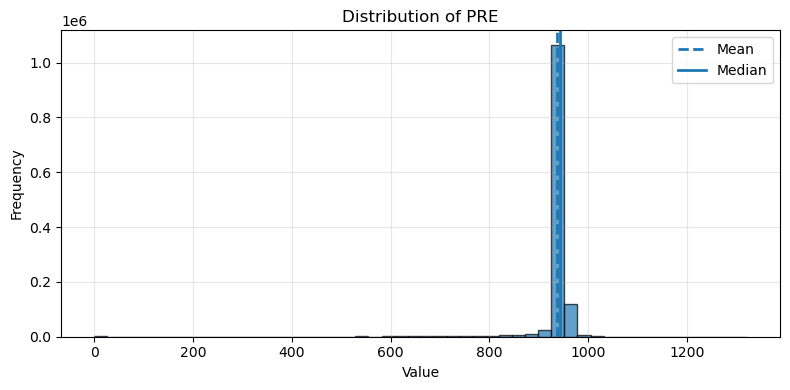

In [13]:
def plot_single_distribution(df, variable, bins=50):
    subset = df[df['magnitude_name'] == variable]['value'].dropna()

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.hist(subset, bins=bins, alpha=0.7, edgecolor='black')

    # mean & median
    ax.axvline(subset.mean(), linestyle='--', linewidth=2, label='Mean')
    ax.axvline(subset.median(), linestyle='-', linewidth=2, label='Median')

    ax.set_title(f'Distribution of {variable}', fontsize=12)
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_single_distribution(df, 'PRE')

### Variable Availability map


In [14]:
def variable_availability(df):
    avail = (
        df.groupby(['magnitude_name', 'category'], observed=True)
        .agg(
            first_year = ('entry_date', lambda s: s.dt.year.min()),
            last_year  = ('entry_date', lambda s: s.dt.year.max()),
            n_rows     = ('value',      'count'),
        )
        .reset_index()
        .sort_values(['category', 'first_year'])
    )
    return avail

avail = variable_availability(df)
print(avail.to_string(index=False))

         magnitude_name  category  first_year  last_year  n_rows
                     DV     meteo        2019       2024 1262592
                     HR     meteo        2019       2024 1262592
                    PRE     meteo        2019       2024 1262592
          PRECIPITACION     meteo        2019       2024 1262592
                     RS     meteo        2019       2024 1262592
                   TEMP     meteo        2019       2024 1262592
                     VV     meteo        2019       2024 1262592
                  <PM10 pollutant        2001       2024 2077584
                BENCENO pollutant        2001       2024  920448
                     CO pollutant        2001       2024 1735680
            ETILBENCENO pollutant        2001       2024  911688
HIDROCARBS_NO_METANICOS pollutant        2001       2020  508440
     HIDROCARBS_TOTALES pollutant        2001       2020  508440
                 METANO pollutant        2001       2020  508440
                     NO p

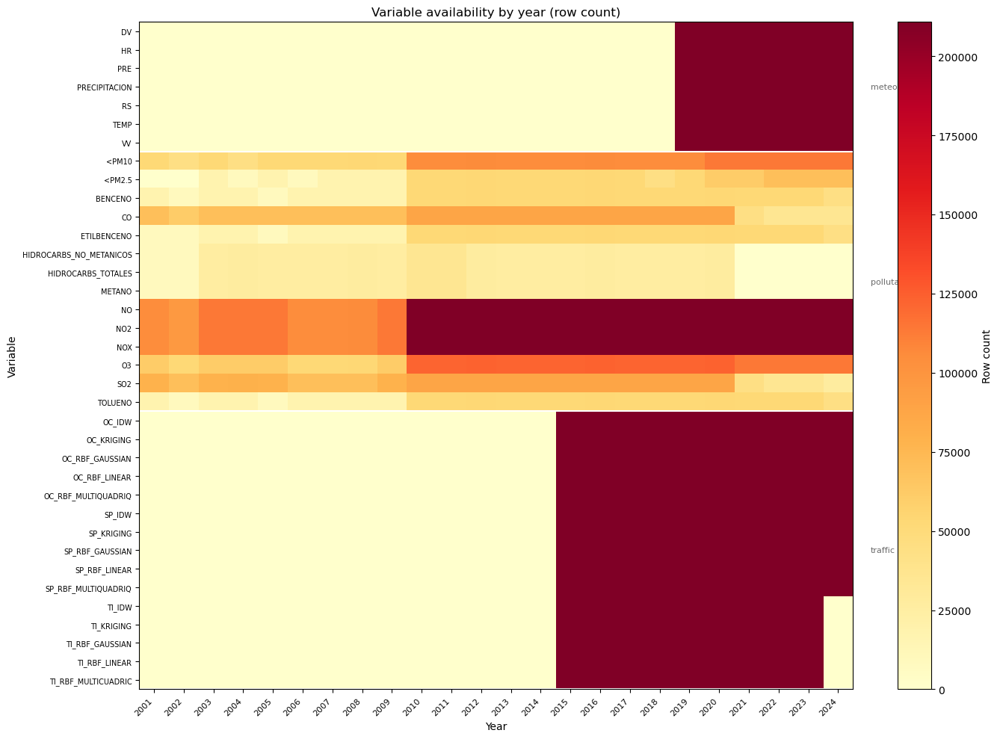

In [15]:
def plot_availability_heatmap(df):
    pivot = (
        df.assign(year=df['entry_date'].dt.year)
        .groupby(['magnitude_name', 'year'], observed=True)['value']
        .count()
        .unstack(fill_value=0)
    )
    # Sort rows by category then name for readability
    order = avail.sort_values(['category', 'magnitude_name'])['magnitude_name']
    pivot = pivot.reindex(order.values)

    fig, ax = plt.subplots(figsize=(14, 10))
    img = ax.imshow(
        pivot.values,
        aspect='auto',
        cmap='YlOrRd',
        interpolation='nearest'
    )
    plt.colorbar(img, ax=ax, label='Row count')
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index, fontsize=7)
    ax.set_title("Variable availability by year (row count)", fontsize=12)
    ax.set_xlabel("Year")
    ax.set_ylabel("Variable")

    # Draw horizontal separator lines between categories
    cat_sizes = avail.groupby('category', observed=True).size()
    boundary = 0
    for cat in ['meteo', 'pollutant', 'traffic']:
        if cat in cat_sizes.index:
            boundary += cat_sizes[cat]
            ax.axhline(boundary - 0.5, color='white', lw=1.5)
            ax.text(
                len(pivot.columns) + 0.1,
                boundary - cat_sizes[cat] / 2 - 0.5,
                cat, va='center', fontsize=8, color='dimgray'
            )
    plt.tight_layout()
    plt.show()


plot_availability_heatmap(df)

Not all variables are consistently recorded across the full 2001–2024 period. As described in the dataset, several variables were introduced later, which is clearly visible. Meteorological variables (e.g., DV, HR, TEMP) are essentially absent before ~2019 and then show very high and stable coverage afterward.

Traffic variables exhibit an even more abrupt pattern, appearing almost entirely from ~2015 onward, with very dense observations across all interpolation methods (IDW, Kriging, RBF). In contrast, core pollutants such as NO, NO2, and NOX are consistently present across most years, while others (e.g., BENCENO, TOLUENO, hydrocarbons) show partial or declining availability, especially in earlier or later periods.

Overall, the dataset expands significantly over time in both variables and observations, implying that in some cases analyses must restrict to consistent time windows to avoid biased results.


### Sensor Location Plot


Sensor locations from the UTM coordinates (`utm_x`, `utm_y`).


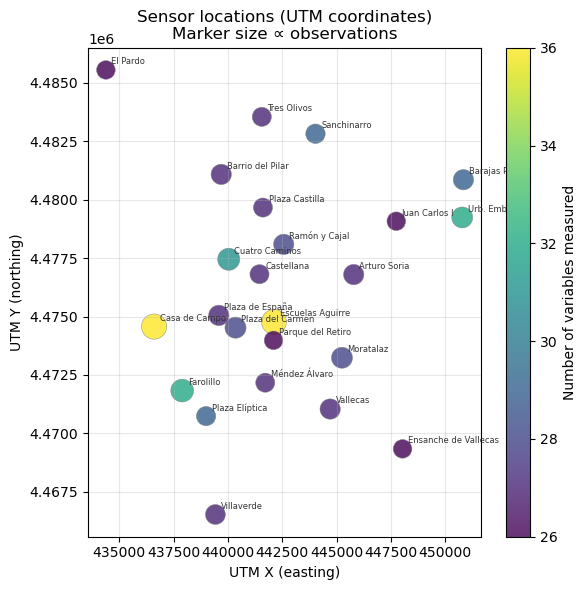

In [16]:
def plot_sensor_map(sensors):
    fig, ax = plt.subplots(figsize=(6, 6))

    scatter = ax.scatter(
        sensors['utm_x'],
        sensors['utm_y'],
        s=sensors['n_observations'] / sensors['n_observations'].max() * 300 + 30,
        c=sensors['n_variables'],
        cmap='viridis',
        alpha=0.8,
        edgecolors='grey',
        linewidths=0.4,
    )
    plt.colorbar(scatter, ax=ax, label='Number of variables measured')

    for _, row in sensors.iterrows():
        ax.annotate(
            row['sensor_name'],
            (row['utm_x'], row['utm_y']),
            textcoords='offset points',
            xytext=(4, 4),
            fontsize=6,
            color='#333333'
        )

    ax.set_title("Sensor locations (UTM coordinates)\nMarker size ∝ observations", fontsize=12)
    ax.set_xlabel("UTM X (easting)")
    ax.set_ylabel("UTM Y (northing)")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_sensor_map(sensors)

# 2. Missingness and data quality

Rows where `is_interpolated=True` represent values that were originally missing
and reconstructed by METRAQ's interpolation pipeline.
Missingness is measured per variable, per sensor and over time.


## Interpolation rates



Overall interpolation rate: 11.23%
7,285,088 interpolated rows out of 64,881,744 total

Top 10 variables (highest interpolation):
magnitude_name  category  n_total  n_interpolated  interp_pct
           PRE     meteo  1262592         1107000       87.68
            RS     meteo  1262592         1106136       87.61
            DV     meteo  1262592         1055952       83.63
            VV     meteo  1262592         1055256       83.58
 PRECIPITACION     meteo  1262592         1001136       79.29
            HR     meteo  1262592          689880       54.64
          TEMP     meteo  1262592          644784       51.07
   ETILBENCENO pollutant   911688           49144        5.39
       TOLUENO pollutant   920448           49366        5.36
       BENCENO pollutant   920448           46831        5.09

Top 5 sensors (highest interpolation):
sensor_id       sensor_name  n_total  n_interpolated  interp_pct
 28079049 Parque del Retiro  2165397          372087       17.18
 28079048        

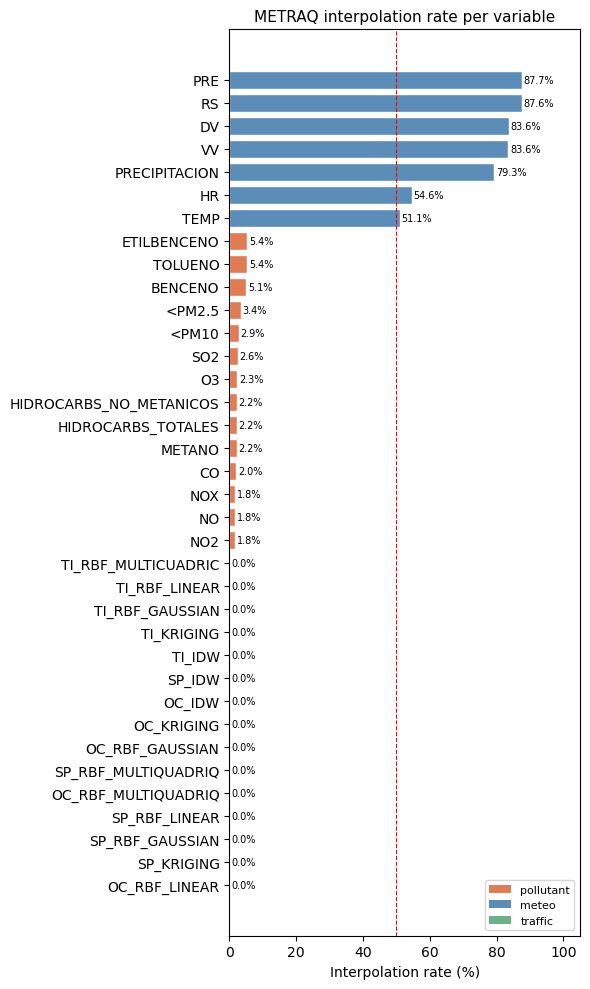

In [17]:
def plot_interpolation_rates(df: pd.DataFrame) -> None:
    rate = (
        df.groupby(['magnitude_name', 'category'], observed=True)['is_interpolated']
        .mean()
        .mul(100)
        .reset_index()
        .sort_values('is_interpolated', ascending=True)
    )

    palette = {
        'pollutant': '#E07B54',
        'meteo': '#5B8DB8',
        'traffic': '#6AB187',
        'unknown': 'grey'
    }

    colors = rate['category'].map(palette)
    fig, ax = plt.subplots(figsize=(6, len(rate) * 0.25 + 1))

    bars = ax.barh(
        rate['magnitude_name'],
        rate['is_interpolated'],
        color=colors,
        edgecolor='white'
    )

    ax.set_xlabel("Interpolation rate (%)")
    ax.set_title("METRAQ interpolation rate per variable", fontsize=11)
    ax.axvline(50, color='red', lw=0.8, linestyle='--', label='50%')
    ax.set_xlim(0, 105)

    # value labels
    for bar, val in zip(bars, rate['is_interpolated']):
        ax.text(
            val + 0.5,
            bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}%",
            va='center',
            fontsize=7
        )

    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=c, label=k)
        for k, c in palette.items() if k != 'unknown'
    ]
    ax.legend(handles=legend_elements, loc='lower right', fontsize=8)

    plt.tight_layout()
    plt.show()

def interpolation_summary(df):
    n_total      = len(df)
    n_interp     = df['is_interpolated'].sum()
    overall_rate = n_interp / n_total * 100

    # Per variable
    per_var = (
        df.groupby(['magnitude_name', 'category'], observed=True)['is_interpolated']
        .agg(n_total='count', n_interpolated='sum')
        .reset_index()
    )
    per_var['interp_pct'] = (
        per_var['n_interpolated'] / per_var['n_total'] * 100
    ).round(2)

    per_var = per_var.sort_values('interp_pct', ascending=False)

    # Per sensor
    per_sensor = (
        df.groupby(['sensor_id', 'sensor_name'], observed=True)['is_interpolated']
        .agg(n_total='count', n_interpolated='sum')
        .reset_index()
    )
    per_sensor['interp_pct'] = (
        per_sensor['n_interpolated'] / per_sensor['n_total'] * 100
    ).round(2)

    per_sensor = per_sensor.sort_values('interp_pct', ascending=False)

    return overall_rate, per_var, per_sensor

# FINAL REPORT FUNCTION (summary + plot together)
def interpolation_report(df):
    overall_rate, per_var, per_sensor = interpolation_summary(df)

    n_total = len(df)
    n_interp = df['is_interpolated'].sum()

    print(f"\nOverall interpolation rate: {overall_rate:.2f}%")
    print(f"{int(n_interp):,} interpolated rows out of {n_total:,} total")

    print("\nTop 10 variables (highest interpolation):")
    print(per_var.head(10).to_string(index=False))

    print("\nTop 5 sensors (highest interpolation):")
    print(per_sensor.head(5).to_string(index=False))

    print("\nVisualization:\n")
    plot_interpolation_rates(df)


interpolation_report(df)

- *Meteo variables* have all >50% of data interpolated
- *Pollutant variables* are all under 5.5% of data interpolated overall
- *Traffic variables* do not exhibit interpolation, at the same time they are not raw sensor measurements but values generated directly by interpolation methods.


### Confirming interpolation rate with full heatmap


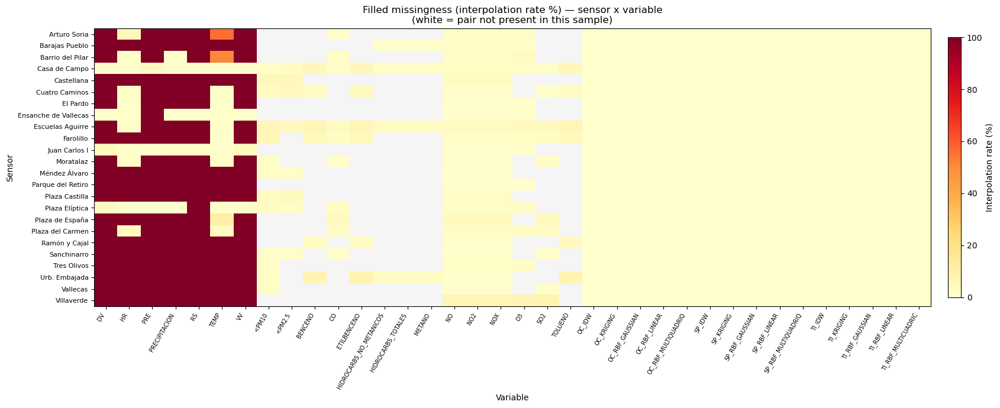

In [18]:
def plot_interpolation_heatmap(df, avail_order = None):
    pivot = (
        df.groupby(['sensor_name', 'magnitude_name'], observed=True)['is_interpolated']
        .mean()
        .mul(100)
        .unstack()        # sensor_name -> rows, magnitude_name -> cols
    )

    # Sort columns: meteo | pollutant | traffic
    if avail_order is not None:
        ordered_cols = (
            avail_order[
                avail_order['magnitude_name'].isin(pivot.columns)
            ]
            .sort_values(['category', 'magnitude_name'])['magnitude_name']
            .tolist()
        )
        pivot = pivot.reindex(columns=ordered_cols)

    # Mask NaN (absent pairs) so they render white
    cmap = plt.cm.YlOrRd.copy()
    cmap.set_bad('whitesmoke')
    masked = np.ma.masked_invalid(pivot.values)

    fig, ax = plt.subplots(figsize=(17, 7))
    im = ax.imshow(masked, cmap=cmap, vmin=0, vmax=100, aspect='auto')
    plt.colorbar(im, ax=ax, label='Interpolation rate (%)', fraction=0.015, pad=0.02)

    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=60, ha='right', fontsize=7)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index, fontsize=8)
    ax.set_title(
        'Filled missingness (interpolation rate %) — sensor x variable\n'
        '(white = pair not present in this sample)',
        fontsize=12,
    )
    ax.set_xlabel('Variable')
    ax.set_ylabel('Sensor')
    plt.tight_layout()
    plt.show()


plot_interpolation_heatmap(df, avail_order=avail)

## Identifying Gaps


### General gaps
Years in which each sensor recorded at least one observation.


In [19]:
def sensor_year_activity_matrix(df, category=None, variable=None):
    subset = df.copy()

    if category is not None:
        subset = subset[subset['category'] == category]

    if variable is not None:
        subset = subset[subset['magnitude_name'] == variable]

    subset['year'] = subset['entry_date'].dt.year

    activity = (
        subset.groupby(['sensor_name', 'year'], observed=True)['value']
        .count()
        .unstack(fill_value=0)
    )

    # Convert counts into binary availability: 1 = at least one observation in that year
    activity_binary = activity.gt(0).astype(int)

    # Order sensors by first active year
    first_year = activity_binary.replace(0, np.nan).apply(lambda row: row.first_valid_index(), axis=1)
    activity_binary = activity_binary.loc[first_year.sort_values().index]

    return activity_binary


def plot_sensor_year_activity(activity_matrix, title='Sensor activity by year'):
    mat = activity_matrix.copy()

    cmap = matplotlib.colors.ListedColormap(['#EFEFEF', '#2E86AB'])

    fig, ax = plt.subplots(figsize=(10, max(6, len(mat) * 0.35)))

    im = ax.imshow(mat.values, cmap=cmap, vmin=0, vmax=1, aspect='auto')

    ax.set_xticks(range(len(mat.columns)))
    ax.set_xticklabels(mat.columns, rotation=45, ha='right', fontsize=8)

    ax.set_yticks(range(len(mat.index)))
    ax.set_yticklabels(mat.index, fontsize=8)

    ax.set_xlabel('Year')
    ax.set_ylabel('Sensor')
    ax.set_title(title, fontsize=12)

    cbar = plt.colorbar(im, ax=ax, ticks=[0.25, 0.75], fraction=0.02, pad=0.02)
    cbar.ax.set_yticklabels(['No data', 'Has data'], fontsize=8)

    ax.grid(False)
    plt.tight_layout()
    plt.show()

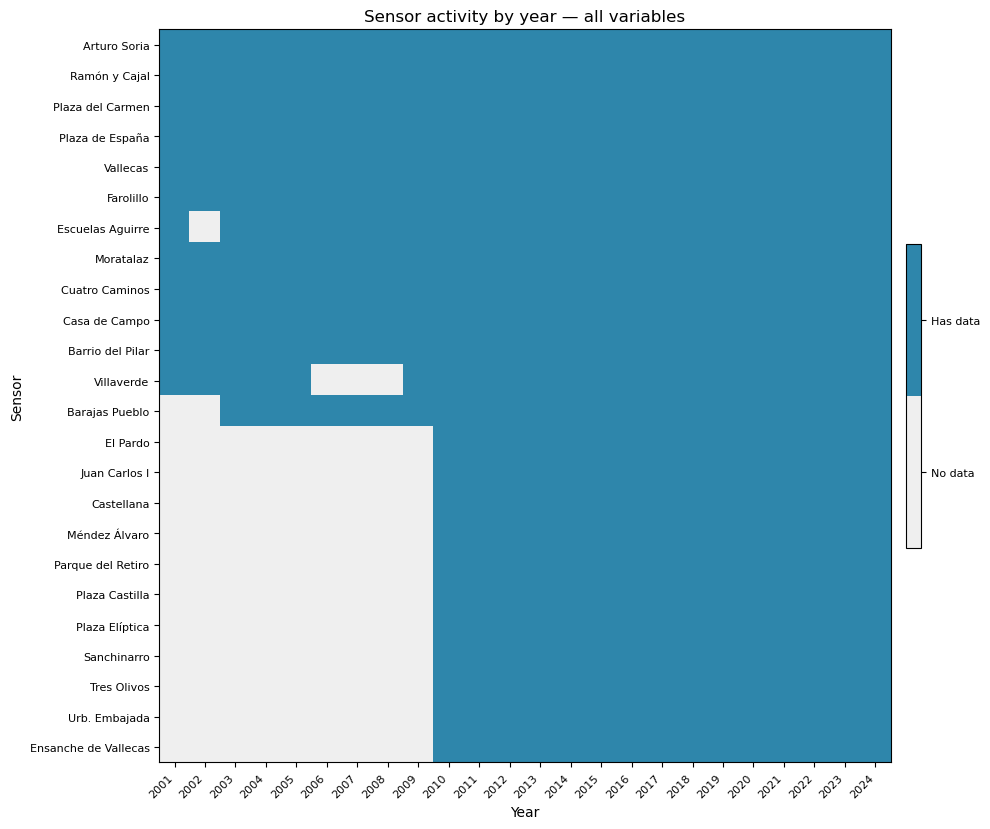

In [20]:
activity_matrix = sensor_year_activity_matrix(df)
plot_sensor_year_activity(activity_matrix, title='Sensor activity by year — all variables')

The sensor-year activity map shows that the monitoring network expanded over time. Most sensors were active from 2001, while 11 sensors only start showing data by the end of 2009, indicating later activation or integration into the dataset. One sensor begins recording from around mid-2002. The isolated white gaps for otherwise active sensors suggest temporary interruptions, likely due to sensor malfunction, maintenance, or shutdown periods rather than permanent absence.


### Temporal Gaps


In [21]:
def _compute_gaps_for_group(timestamps):
    n_observed = len(timestamps)
    if n_observed < 2:
        return {
            'n_observed'           : n_observed,
            'n_expected'           : n_observed,
            'n_absent'             : 0,
            'absent_pct'           : 0.0,
            'max_consecutive_gap_h': 0,
        }

    sorted_ts  = timestamps.sort_values().reset_index(drop=True)
    span_hours = (sorted_ts.iloc[-1] - sorted_ts.iloc[0]).total_seconds() / 3600
    n_expected = int(round(span_hours)) + 1      # +1 includes both endpoints
    n_absent   = max(0, n_expected - n_observed)
    absent_pct = round(n_absent / n_expected * 100, 2) if n_expected > 0 else 0.0

    # Diffs in hours between consecutive observations
    diffs_h = sorted_ts.diff().dropna().dt.total_seconds().div(3600)

    # A diff > 1 h means (diff - 1) absent hourly slots in that gap
    large_diffs = diffs_h[diffs_h > 1.5]    # > 1.5 catches diffs >= 2 with tolerance
    max_consecutive_gap_h = (
        int(large_diffs.max() - 1) if len(large_diffs) > 0 else 0
    )

    return {
        'n_observed'           : n_observed,
        'n_expected'           : n_expected,
        'n_absent'             : n_absent,
        'absent_pct'           : absent_pct,
        'max_consecutive_gap_h': max_consecutive_gap_h,
    }


def structural_gap_summary(df, variables = None, sensor_ids = None):
    subset = df.copy()
    if variables  is not None:
        subset = subset[subset['magnitude_name'].isin(variables)]
    if sensor_ids is not None:
        subset = subset[subset['sensor_id'].isin(sensor_ids)]

    records = []
    grouped = subset.groupby(
        ['sensor_id', 'sensor_name', 'magnitude_name'], observed=True
    )
    for (sid, sname, var), grp in grouped:
        stats = _compute_gaps_for_group(grp['entry_date'])
        records.append({
            'sensor_id'  : sid,
            'sensor_name': str(sname),
            'variable'   : str(var),
            **stats,
        })

    return (
        pd.DataFrame(records)
        .sort_values('absent_pct', ascending=False)
        .reset_index(drop=True)
    )

### Top 20 pairs (sensor, variable) with structural missingness
The 20 sensor-variable pairs with the largest share of absent data.


In [22]:
gap_df = structural_gap_summary(df, POLLUTANTS)

n_pairs      = len(gap_df)
n_with_gaps  = (gap_df['n_absent'] > 0).sum()
total_absent = gap_df['n_absent'].sum()

print(f'(sensor, variable) pairs analysed : {n_pairs}')
print(f'Pairs with at least one absent row : {n_with_gaps}  ({n_with_gaps/n_pairs*100:.1f}%)')
print(f'Total absent hourly slots          : {total_absent:,}')
print()
print('Top 20 pairs by structural missingness:')
print(gap_df.head(20).to_string(index=False))

(sensor, variable) pairs analysed : 157
Pairs with at least one absent row : 24  (15.3%)
Total absent hourly slots          : 333,120

Top 20 pairs by structural missingness:
sensor_id      sensor_name                variable  n_observed  n_expected  n_absent  absent_pct  max_consecutive_gap_h
 28079017       Villaverde                     SO2      149016      175320     26304       15.00                  26304
 28079017       Villaverde                      O3      184080      210384     26304       12.50                  26304
 28079017       Villaverde                     NOX      184080      210384     26304       12.50                  26304
 28079017       Villaverde                     NO2      184080      210384     26304       12.50                  26304
 28079017       Villaverde                      NO      184080      210384     26304       12.50                  26304
 28079008 Escuelas Aguirre HIDROCARBS_NO_METANICOS      140256      157800     17544       11.12         

### Visualization of the top 20 pairs with structural missingness


/var/folders/8m/5dscttz171x3mmrgc0dxt9rm0000gn/T/ipykernel_71959/1408493190.py:47: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)


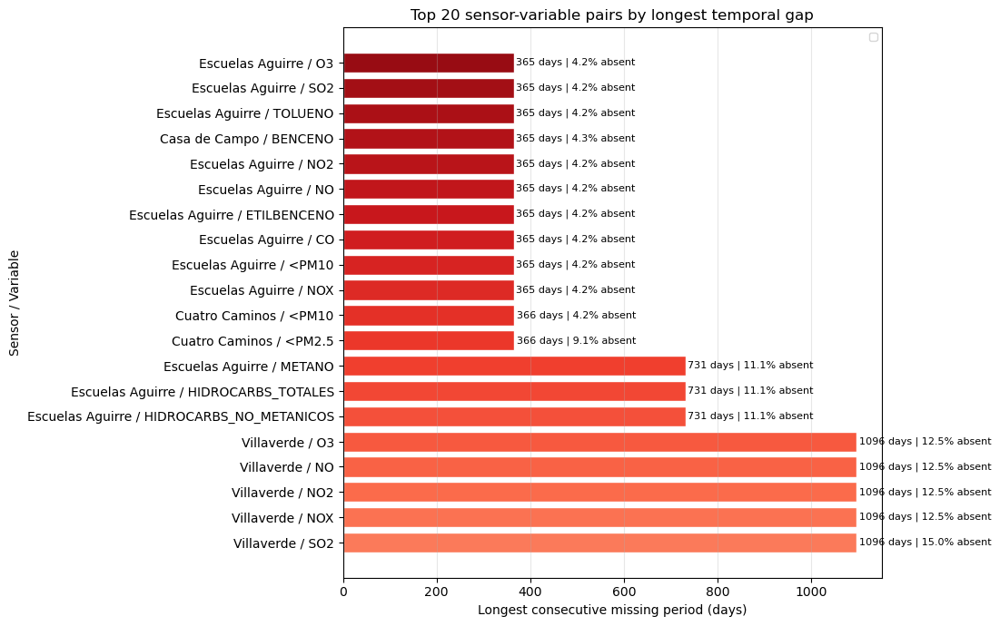

In [23]:
def plot_temporal_gaps(gap_df, top_n=20):
    plot_df = gap_df[gap_df['n_absent'] > 0].copy()

    if plot_df.empty:
        print('No temporal gaps found.')
        return

    plot_df['max_gap_days'] = plot_df['max_consecutive_gap_h'] / 24

    top = (
        plot_df
        .sort_values('max_consecutive_gap_h', ascending=False)
        .head(top_n)
        .copy()
    )

    top['label'] = top['sensor_name'] + ' / ' + top['variable']


    fig, ax = plt.subplots(figsize=(11, 7))

    colors = plt.cm.Reds(np.linspace(0.45, 0.9, len(top)))

    ax.barh(
        top['label'],
        top['max_gap_days'],
        color=colors,
        edgecolor='white'
    )

    for i, row in enumerate(top.itertuples()):
        ax.text(
            row.max_gap_days + 5,
            i,
            f'{row.max_gap_days:.0f} days | {row.absent_pct:.1f}% absent',
            va='center',
            fontsize=8
        )

    ax.set_title(
        f'Top {top_n} sensor-variable pairs by longest temporal gap',
        fontsize=12
    )
    ax.set_xlabel('Longest consecutive missing period (days)')
    ax.set_ylabel('Sensor / Variable')
    ax.grid(axis='x', alpha=0.3)
    ax.legend(fontsize=8)

    plt.tight_layout()
    plt.show()


plot_temporal_gaps(gap_df)

### General sensor-variable coverage summary


In [24]:
def sensor_variable_matrix(df):
    return (
        df.groupby(['sensor_name', 'magnitude_name'], observed=True)['value']
        .count()
        .unstack(fill_value=0)
        .gt(0)
        .astype(int)
    )


coverage_matrix = sensor_variable_matrix(df)

n_sensors = coverage_matrix.shape[0]
n_variables = coverage_matrix.shape[1]
total_pairs = n_sensors * n_variables

pairs_with_data = int(coverage_matrix.values.sum())
pairs_without_data = total_pairs - pairs_with_data

coverage_pct = pairs_with_data / total_pairs * 100
missing_pair_pct = pairs_without_data / total_pairs * 100

print(f'Coverage matrix              : {n_sensors} sensors x {n_variables} variables')
print(f'Total sensor-variable pairs  : {total_pairs:,}')
print(f'Pairs with data              : {pairs_with_data:,} ({coverage_pct:.1f}%)')
print(f'Pairs without data           : {pairs_without_data:,} ({missing_pair_pct:.1f}%)')


# Distribution of temporal gaps from gap_df

gap_summary = gap_df.copy()
gap_summary['max_gap_days'] = gap_summary['max_consecutive_gap_h'] / 24

pairs_with_temporal_gaps = (gap_summary['n_absent'] > 0).sum()
total_absent_hours = gap_summary['n_absent'].sum()

print()
print('Temporal gap summary:')
print(f'(sensor, variable) pairs analysed : {len(gap_summary):,}')
print(f'Pairs with temporal gaps          : {pairs_with_temporal_gaps:,} '
      f'({pairs_with_temporal_gaps / len(gap_summary) * 100:.1f}%)')
print(f'Total absent hourly slots         : {total_absent_hours:,}')

print()
print('Distribution of temporal gaps:')
gap_distribution = pd.DataFrame({
    'absent_pct': gap_summary['absent_pct'].quantile([0, .25, .5, .75, .90, .95, 1]),
    'n_absent_hours': gap_summary['n_absent'].quantile([0, .25, .5, .75, .90, .95, 1]),
    'max_gap_days': gap_summary['max_gap_days'].quantile([0, .25, .5, .75, .90, .95, 1]),
}).round(2)

print(gap_distribution.to_string())

Coverage matrix              : 24 sensors x 36 variables
Total sensor-variable pairs  : 864
Pairs with data              : 685 (79.3%)
Pairs without data           : 179 (20.7%)

Temporal gap summary:
(sensor, variable) pairs analysed : 157
Pairs with temporal gaps          : 24 (15.3%)
Total absent hourly slots         : 333,120

Distribution of temporal gaps:
      absent_pct  n_absent_hours  max_gap_days
0.00        0.00             0.0           0.0
0.25        0.00             0.0           0.0
0.50        0.00             0.0           0.0
0.75        0.00             0.0           0.0
0.90        4.16          8760.0         365.0
0.95        9.50         17544.0         439.0
1.00       15.00         26304.0        1096.0


The results show that missingness is structured but **not dominant**. At the sensor-variable level, the dataset is fairly complete: 79.3% of all possible sensor-variable pairs have at least some data, while 20.7% are completely absent.

For temporal gaps, only **24 out of 157** analysed pollutant sensor-variable pairs have missing hourly slots, meaning most pairs are continuous over their active period. However, the upper percentiles show that when gaps occur, they can be long: the 90th percentile already corresponds to one year, while the **maximum gap reaches about 3 years**.


#### Sensor x Variable Coverage matrix
Availability of each variable at each sensor: blue means the sensor recorded at least one observation.


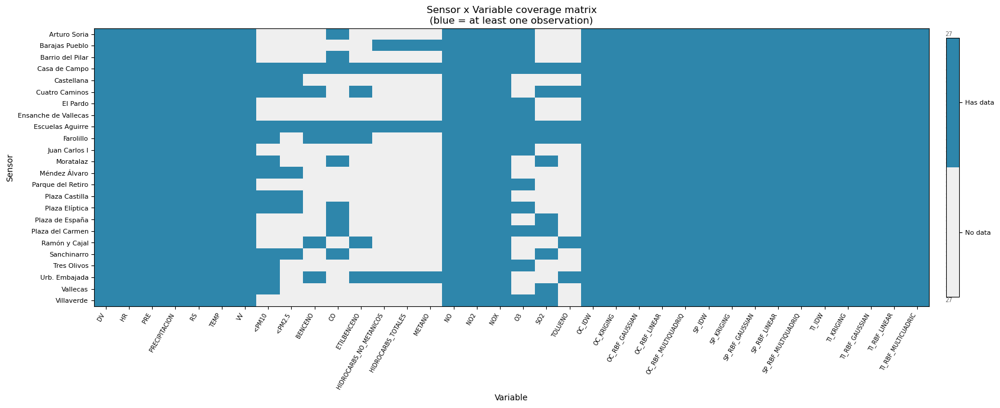

In [25]:
def plot_coverage_matrix(matrix, avail_order = None):
    mat = matrix.copy()

    if avail_order is not None:
        ordered_cols = (
            avail_order[avail_order['magnitude_name'].isin(mat.columns)]
            .sort_values(['category', 'magnitude_name'])['magnitude_name']
            .tolist()
        )
        mat = mat.reindex(columns=ordered_cols)

    cmap = matplotlib.colors.ListedColormap(['#EFEFEF', '#2E86AB'])

    fig, ax = plt.subplots(figsize=(17, 7))
    im = ax.imshow(mat.values, cmap=cmap, vmin=0, vmax=1, aspect='auto')

    cbar = plt.colorbar(im, ax=ax, ticks=[0.25, 0.75], fraction=0.015, pad=0.02)
    cbar.ax.set_yticklabels(['No data', 'Has data'], fontsize=8)

    ax.set_xticks(range(len(mat.columns)))
    ax.set_xticklabels(mat.columns, rotation=60, ha='right', fontsize=7)
    ax.set_yticks(range(len(mat.index)))
    ax.set_yticklabels(mat.index, fontsize=8)
    ax.set_title(
        'Sensor x Variable coverage matrix\n(blue = at least one observation)',
        fontsize=12,
    )
    ax.set_xlabel('Variable')
    ax.set_ylabel('Sensor')

    # Annotate each row with total variable count
    row_counts = mat.sum(axis=1)
    for i, cnt in enumerate(row_counts):
        ax.text(
            len(mat.columns) + 0.2, i,
            f'{int(cnt)}',
            va='center', fontsize=7, color='dimgray',
        )

    plt.tight_layout()
    plt.show()


plot_coverage_matrix(coverage_matrix, avail_order=avail)

Each sensor consistently records a core group of pollutant variables such as NO, NO2, NOX and O3, which appear as continuous coverage across rows. Meteorological variables, including DV, HR, TEMP, PRE, RS and PRECIPITATION, are also widely available across most sensors. In contrast, other pollutant variables like BENCENO, TOLUENO, ETILBENCENO and hydrocarbon-related measures (HIDROCARBS_NO_METANICOS, HIDROCARBS_TOTALES, METANO) show partial coverage, with several sensors not collecting them. Traffic-related variables (OC_*, SP_*, TI_* across IDW, KRIGING and RBF methods) are almost uniformly present across all sensors, reflecting their derived nature.


## Detection of Invalid or inconsistent values


In order to define inconsistent values regardless of the `is_interpolated=True` flag, here the physical plausibility bounds (min, max) are defined. `None` means that side is unconstrained.


*Validity bounds* are defined by combining EU regulatory thresholds, physically plausible environmental limits, and empirical statistics from Section 1 (e.g., percentiles and extrema), ensuring removal of implausible values while preserving realistic variability across variables.


In [26]:
VALIDITY_BOUNDS: dict[str, tuple] = {

    # Meteorological
    'TEMP': (-20.0, 50.0),
    'HR': (0.0, 100.0), #--> physical limits. Data actually goes -149 to 369.
    'PRE': (880.0, 1000.0), # --> Mean=936, p99=965. Legitimate storm lows reach ~895 hPa; strong anticyclones ~975 hPa at 650m altitude.
    'VV': (0.0, 50.0), # p99=3.7, max=989 (clearly impossible).
    'DV': (0.0, 360.0), # wind diection, 0-360° physical limits. Data actually goes -10 to 370.
    'RS': (0.0, 1200.0), # --> Solar radiation,at Earth's surface ≈ 1000–1100 W/m², which is why the upper bound of 1200 W/m² is appropriate
    'PRECIPITACION': (0.0, 100.0),

    # Pollutants
    'SO2': (0.0, 50.0),
    'CO': (0.0, 10.0), #--> Max=16, p99=1. EU limit is 10 mg/m³.
    'NO': (0.0, 800.0), #-->  p99=257, max=1502. Values 300–1000 µg/m³ are plausible at heavy-traffic junctions.
    'NO2': (0.0, 400.0), # --> 200 = EU hourly limit, not physically impossible. EU alert threshold is 400. Max=586.
    'NOX': (0.0, 1000.0), # --> NOX spikes to 500–1000 near congested roads are real.
    '<PM10': (0.0, 400.0), #--> Saharan dust intrusions in Madrid routinely push hourly PM10 to 200–400 µg/m³.
    '<PM2.5': (0.0, 80.0), #--> p99=42, max=215.
    'O3': (0.0, 240.0), # --> EU alert threshold is 240 µg/m³. Max=235 is a genuine summer photochemical event, not a sensor error.
    'TOLUENO': (0.0, 50.0),
    'BENCENO': (0.0, 10.0),
    'ETILBENCENO': (0.0, 20.0),
    'HIDROCARBS_TOTALES': (0.0, 5.0),
    'METANO': (0.0, 5.0),
    'HIDROCARBS_NO_METANICOS': (0.0, 5.0),

}
print(f'Validity bounds defined for {len(VALIDITY_BOUNDS)} variables.')

Validity bounds defined for 21 variables.


Based on the validity bounds, inconsistent values are identified and separated between interpolated observations, which may reflect imputation artifacts, and non-interpolated observations, which indicate implausible original measurements according to the physical logic of each variable


In [27]:
def detect_invalid_values(df, bounds):
    flagged = []

    for var, (lo, hi) in bounds.items():
        mask_var = df['magnitude_name'] == var
        if not mask_var.any():
            continue

        sub = df[mask_var]

        if lo is not None:
            below = sub[sub['value'] < lo].copy()
            if len(below):
                below['violation'] = f'below_min ({lo})'
                flagged.append(below)

        if hi is not None:
            above = sub[sub['value'] > hi].copy()
            if len(above):
                above['violation'] = f'above_max ({hi})'
                flagged.append(above)

    traffic_mask = df['category'] == 'traffic'
    traffic_neg = df[traffic_mask & (df['value'] < 0)].copy()

    if len(traffic_neg):
        traffic_neg['violation'] = 'below_min (0)'
        flagged.append(traffic_neg)

    if not flagged:
        print('No invalid values detected.')
        return pd.DataFrame()

    result = pd.concat(flagged, ignore_index=True).drop_duplicates()

    print(f'Total invalid rows  : {len(result):,}')
    print(f'  of which real     : {(~result["is_interpolated"]).sum():,}  (is_interpolated=False)')
    print(f'  of which filled   : {result["is_interpolated"].sum():,}  (is_interpolated=True)')

    total_counts = (
        df.groupby('magnitude_name', observed=True)['value']
        .count()
        .rename('total_count')
    )

    invalid_counts = (
        result.groupby(['magnitude_name', 'violation'], observed=True)
        .size()
        .reset_index(name='invalid_count')
    )

    summary = invalid_counts.merge(
        total_counts,
        on='magnitude_name',
        how='left'
    )

    summary['invalid_pct'] = (
        summary['invalid_count'] / summary['total_count'] * 100
    ).round(3)

    summary = summary.sort_values('invalid_count', ascending=False)

    print('\nInvalid rows per variable (with percentages):')
    print(summary.to_string(index=False))

    return result


invalid_df = detect_invalid_values(df, VALIDITY_BOUNDS)

Total invalid rows  : 58,414
  of which real     : 15,272  (is_interpolated=False)
  of which filled   : 43,142  (is_interpolated=True)

Invalid rows per variable (with percentages):
         magnitude_name          violation  invalid_count  total_count  invalid_pct
                    PRE  below_min (880.0)          39690      1262592        3.144
                    SO2   above_max (50.0)           7117      1779480        0.400
                    NOX above_max (1000.0)           4003      4128864        0.097
                    PRE above_max (1000.0)           2791      1262592        0.221
                   TEMP  below_min (-20.0)            882      1262592        0.070
                BENCENO   above_max (10.0)            660       920448        0.072
                     VV   above_max (50.0)            651      1262592        0.052
                     NO  above_max (800.0)            537      4128864        0.013
                     HR    below_min (0.0)            504    

Invalid values per variable, split by interpolated and original observations.


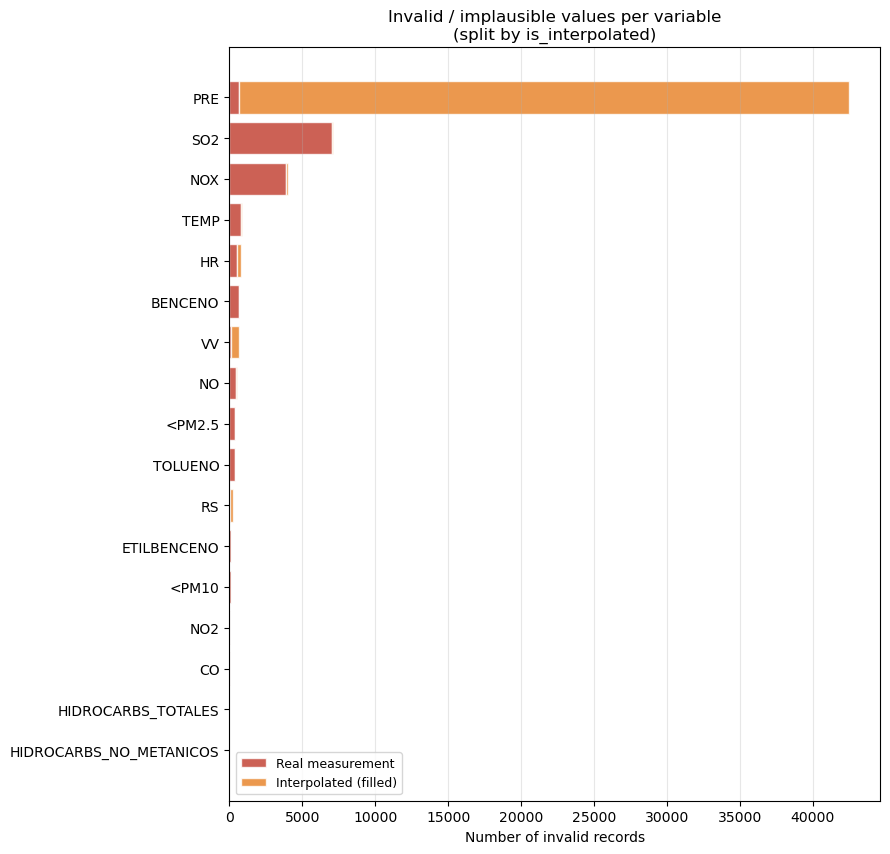

In [28]:
def plot_invalid_values(invalid_df):
    if len(invalid_df) == 0:
        print('No invalid values to plot.')
        return

    # Pivot: rows = variable, columns = is_interpolated
    pivot = (
        invalid_df
        .groupby(['magnitude_name', 'is_interpolated'], observed=True)
        .size()
        .unstack(fill_value=0)
        .rename(columns={False: 'Real measurement', True: 'Interpolated (filled)'})
    )
    # Sort by total count descending
    pivot['_total'] = pivot.sum(axis=1)
    pivot = pivot.sort_values('_total').drop(columns='_total')

    fig, ax = plt.subplots(figsize=(9, max(4, len(pivot) * 0.45 + 1)))

    palette = {'Real measurement': '#C0392B', 'Interpolated (filled)': '#E67E22'}
    bottom  = np.zeros(len(pivot))
    for col in pivot.columns:
        color = palette.get(col, 'steelblue')
        ax.barh(pivot.index, pivot[col], left=bottom, label=col,
                color=color, alpha=0.8, edgecolor='white')
        bottom += pivot[col].values

    ax.set_xlabel('Number of invalid records')
    ax.set_title(
        'Invalid / implausible values per variable\n'
        '(split by is_interpolated)',
        fontsize=12,
    )
    ax.legend(fontsize=9)
    ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_invalid_values(invalid_df)

- Invalid values are concentrated in a few variables (PRE, NOX, NO), with a large share coming from interpolated data. This suggests interpolation amplifies or introduces implausible values, especially for PRE, while other variables show relatively limited inconsistencies.

- The output shown is compatible with the METRAQ interpolation rate per variable graph, which shows that 87.7% of PRE data was interpolated, and it is reasonable how the majority of invalid measurements is resulting as such. Variables with higher interpolation tend to exhibit more invalid values, suggesting that interpolation may propagate or amplify evident existing inconsistencies in the data.


# 3. Imputation
As several datapoints in the full dataset were originally missing, METRAQ imputed these points with its own interpolation solution. In this section other imputation methods are enacted in order to attempt to improve METRAQ's interpolation method.


### Counting missing values


For every value that METRAQ says was interpolated, we are replacing it with NaN to be able to recover the missingness pattern that existed before METRAQ filled it.


In [29]:
def reconstruct_missingness(
    df):
    df_metraq = df.copy()
    df_missing = df.copy()

    interp_mask = df_missing['is_interpolated']
    df_missing.loc[interp_mask, 'value'] = np.nan

    n_nan   = df_missing['value'].isna().sum()
    n_total = len(df_missing)
    print(f'Reconstructed missing values : {n_nan:,}  ({n_nan / n_total * 100:.1f}% of all rows)')
    # Per-variable NaN count
    nan_per_var = (
        df_missing[interp_mask]
        .groupby('magnitude_name', observed=True)['value']
        .size()
        .sort_values(ascending=False)
    )
    print('\nMissing slots per variable:')
    print(nan_per_var.head(21).to_string())

    return df_missing, df_metraq

df_missing, df_metraq = reconstruct_missingness(df)

Reconstructed missing values : 7,285,088  (11.2% of all rows)

Missing slots per variable:
magnitude_name
PRE                        1107000
RS                         1106136
DV                         1055952
VV                         1055256
PRECIPITACION              1001136
HR                          689880
TEMP                        644784
NOX                          72864
NO                           72863
NO2                          72817
<PM10                        59384
O3                           53881
TOLUENO                      49366
ETILBENCENO                  49144
BENCENO                      46831
SO2                          45908
CO                           35567
<PM2.5                       32772
HIDROCARBS_NO_METANICOS      11287
HIDROCARBS_TOTALES           11132
METANO                       11128


## New Imputation methods
Each method is expected to leave some NaNs that cannot be filled: in the original dataset some groups (mainly whole sensors, see the interpolation rate per sensor in Section 2) were entirely missing and therefore entirely interpolated, so there is no real data to impute from.

Remaining NaNs per variable, used later to compare how much each imputation method can fill.


### Attempt imputation method 1 : **Mean Imputation**
For each missing value, fill in is done by using the average value observed for the same:
- sensor
- variable
- hour of the day
- month of the year


In [30]:
def impute_mean(df):
    result = df.copy()

    group_means = (
        result.groupby(
            ['sensor_id', 'magnitude_name',
            result['entry_date'].dt.hour,
            result['entry_date'].dt.month],
            observed=True
        )['value'].transform('mean')
    )

    result['value'] = result['value'].fillna(group_means)
    return result


df_mean = impute_mean(df_missing)

# Verify: NaN count after imputation
n_remaining = df_mean['value'].isna().sum()
print(f'NaN remaining after mean imputation: {n_remaining:,}')
if n_remaining > 0:
    # Groups where ALL values were NaN cannot be filled by mean
    print('(expected for groups where every observation was originally missing)')

NaN remaining after mean imputation: 6,576,000
(expected for groups where every observation was originally missing)


Overall imputed: 709,088


For mean imputation to work fully there have to be enough real observations within the same sensor-variable-hour-month group. If an entire group is originally missing, the method cannot compute a meaningful average.


### Attempt imputation method 2 : **Forward/Backward Imputation**
This method is based on chronological order.
- *ffill(limit=48)* fills a missing value using the last available previous observation, but only for gaps up to 48 consecutive hours.
- *bfill(limit=48)* fills remaining missing values using the next available future observation, again only up to 48 hours.

This method assumes that values remain reasonably stable over short gaps, but avoids filling very long missing periods.


In [31]:
def impute_ffill_bfill(df):
    # Sort by time within groups so ffill is applied in chronological order
    result = df.sort_values(
        ['sensor_id', 'magnitude_name', 'entry_date']
    ).copy()

    # added a 48-hour limit to avoid filling very long gaps (2 days of hourly data)

    result['value'] = (
        result.groupby(['sensor_id', 'magnitude_name'], observed=True)['value']
        .transform(lambda s: s.ffill(limit=48).bfill(limit=48))
    )
    # Restore original row order
    return result.sort_index()


df_ffill = impute_ffill_bfill(df_missing)

n_remaining = df_ffill['value'].isna().sum()
print(f'NaN remaining after ffill/bfill: {n_remaining:,}')
if n_remaining > 0:
    print('(groups where all values were NaN cannot be filled)')

NaN remaining after ffill/bfill: 6,966,016
(groups where all values were NaN cannot be filled)


Overall imputed: 319,072


Very high number of still NaNs:
- Some gaps are longer than 48 hours, so the method intentionally leaves them as NaN.
- Some sensor-variable groups contain only missing values after reconstruction, so there is no previous or future real observation to use.
- Missing values at the beginning or end of a time series are remaining unfilled if no valid observation exists within the allowed direction/limit.


### Attempt imputation method 3 : **Linear Regression Imputation**
In this linear regression model, the method starts from `df_missing`, where originally interpolated METRAQ observations have been converted back into `NaN`.

The code first creates temporal predictors from `entry_date`: `year`, `month`, `hour`, and `dayofweek`. These are combined with spatial predictors, namely `utm_x` and `utm_y`, so that the regression model can estimate missing values using both where the sensor is located and when the observation occurs.

The imputation is performed separately for each variable through the loop `for var in result['magnitude_name'].dropna().unique()`. For each variable, the model separates observed values from missing values: observed rows are used for training, while rows with `NaN` values are kept aside and later predicted.

The code applies a two-level strategy. First, it trains a global fallback model for each variable using all available observations for that variable. Then, where possible, it trains sensor-specific regression models. If a sensor has at least `min_sensor_rows=100` observed values, the sensor-specific model is used; otherwise, the global model is used as a fallback.

Finally, predicted values are clipped using `VALIDITY_BOUNDS` (defined in Section 2), so that the imputed values remain within the physically plausible limits defined earlier in the data quality step. This makes the regression imputation more controlled and reduces the risk of producing unrealistic values.


In [33]:
def impute_linear_regression(df, max_train_rows=200_000, min_sensor_rows=100, random_state=42):

    result = df.copy()
    result['entry_date'] = pd.to_datetime(result['entry_date'])

    result['year']      = result['entry_date'].dt.year
    result['month']     = result['entry_date'].dt.month
    result['hour']      = result['entry_date'].dt.hour
    result['dayofweek'] = result['entry_date'].dt.dayofweek

    # Since we train per sensor, sensor_id is not used as a feature
    feature_cols = ['utm_x', 'utm_y', 'year', 'month', 'hour', 'dayofweek']

    base_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('regressor', LinearRegression())
    ])

    summary_records = []

    for var in result['magnitude_name'].dropna().unique():
        mask_var = result['magnitude_name'] == var

        n_missing_before = (mask_var & result['value'].isna()).sum()
        if n_missing_before == 0:
            continue

        # Global fallback model trained on all observed rows for this variable
        global_train = result.loc[
            mask_var & result['value'].notna(),
            feature_cols + ['value']
        ]

        if len(global_train) == 0:
            print(f'{var}: skipped, no observed values available for training.')
            summary_records.append({
                'variable': var,
                'trained_rows_global': 0,
                'missing_before': n_missing_before,
                'imputed_total': 0,
                'per_sensor_imputed': 0,
                'fallback_imputed': 0,
                'remaining_nan': n_missing_before,
                'sensor_models_used': 0,
                'fallback_sensors_used': 0,
            })
            continue

        if len(global_train) > max_train_rows:
            global_train_sample = global_train.sample(
                n=max_train_rows,
                random_state=random_state
            )
        else:
            global_train_sample = global_train

        global_model = clone(base_pipeline)
        global_model.fit(global_train_sample[feature_cols], global_train_sample['value'])

        imputed_total = 0
        per_sensor_imputed = 0
        fallback_imputed = 0
        sensor_models_used = 0
        fallback_sensors_used = 0

        # Per-sensor models
        for sensor in result.loc[mask_var, 'sensor_id'].unique():
            mask_sensor = mask_var & (result['sensor_id'] == sensor)
            pred_mask = mask_sensor & result['value'].isna()

            n_pred = pred_mask.sum()
            if n_pred == 0:
                continue

            sensor_train = result.loc[
                mask_sensor & result['value'].notna(),
                feature_cols + ['value']
            ]

            if len(sensor_train) >= min_sensor_rows:
                use_model = clone(base_pipeline)
                use_model.fit(sensor_train[feature_cols], sensor_train['value'])
                sensor_models_used += 1
                per_sensor_imputed += n_pred
            else:
                use_model = global_model
                fallback_sensors_used += 1
                fallback_imputed += n_pred

            result.loc[pred_mask, 'value'] = use_model.predict(
                result.loc[pred_mask, feature_cols]
            )

            imputed_total += n_pred

        n_remaining = (mask_var & result['value'].isna()).sum()

        print(
            f'{var}: global trained on {len(global_train_sample):,} rows | '
            f'imputed {imputed_total:,} missing values | '
            f'{n_remaining:,} NaN remaining '
            f'({sensor_models_used} sensor models, {fallback_sensors_used} fallback sensors)'
        )

        summary_records.append({
            'variable': var,
            'trained_rows_global': len(global_train_sample),
            'missing_before': n_missing_before,
            'imputed_total': imputed_total,
            'per_sensor_imputed': per_sensor_imputed,
            'fallback_imputed': fallback_imputed,
            'remaining_nan': n_remaining,
            'sensor_models_used': sensor_models_used,
            'fallback_sensors_used': fallback_sensors_used,
        })

    # Clip values to validity bounds
    for var, (lo, hi) in VALIDITY_BOUNDS.items():
        mask = result['magnitude_name'] == var

        if lo is not None:
            result.loc[mask, 'value'] = result.loc[mask, 'value'].clip(lower=lo)

        if hi is not None:
            result.loc[mask, 'value'] = result.loc[mask, 'value'].clip(upper=hi)

    # Remove temporary columns
    result = result.drop(columns=['year', 'month', 'hour', 'dayofweek'])

    summary = pd.DataFrame(summary_records)

    print()
    print(f'Total NaN remaining after per-sensor linear regression: {result["value"].isna().sum():,}')

    return result, summary


df_regression, regression_summary = impute_linear_regression(df_missing)

regression_summary

SO2: global trained on 200,000 rows | imputed 45,908 missing values | 0 NaN remaining (10 sensor models, 0 fallback sensors)
CO: global trained on 200,000 rows | imputed 35,567 missing values | 0 NaN remaining (10 sensor models, 0 fallback sensors)
NO: global trained on 200,000 rows | imputed 72,863 missing values | 0 NaN remaining (24 sensor models, 0 fallback sensors)
NO2: global trained on 200,000 rows | imputed 72,817 missing values | 0 NaN remaining (24 sensor models, 0 fallback sensors)
NOX: global trained on 200,000 rows | imputed 72,864 missing values | 0 NaN remaining (24 sensor models, 0 fallback sensors)
<PM10: global trained on 200,000 rows | imputed 59,384 missing values | 0 NaN remaining (13 sensor models, 0 fallback sensors)
O3: global trained on 200,000 rows | imputed 53,881 missing values | 0 NaN remaining (14 sensor models, 0 fallback sensors)
TOLUENO: global trained on 200,000 rows | imputed 49,366 missing values | 0 NaN remaining (6 sensor models, 0 fallback sensors

,variable,trained_rows_global,missing_before,imputed_total,per_sensor_imputed,fallback_imputed,remaining_nan,sensor_models_used,fallback_sensors_used
0,SO2,200000,45908,45908,45908,0,0,10,0
1,CO,200000,35567,35567,35567,0,0,10,0
2,NO,200000,72863,72863,72863,0,0,24,0
3,NO2,200000,72817,72817,72817,0,0,24,0
4,NOX,200000,72864,72864,72864,0,0,24,0
5,<PM10,200000,59384,59384,59384,0,0,13,0
6,O3,200000,53881,53881,53881,0,0,14,0
7,TOLUENO,200000,49366,49366,49366,0,0,6,0
8,BENCENO,200000,46831,46831,46831,0,0,6,0
9,ETILBENCENO,200000,49144,49144,49144,0,0,6,0


For most pollutant variables, the imputation was performed entirely through sensor-specific models, meaning each sensor had enough real observations to train its own regression. In contrast, meteorological variables such as PRE, RS, VV, DV, HR, and PRECIPITACION relied heavily on the global fallback model, indicating that many sensors did not have enough non-missing observations to support local training. This confirms that regression imputation was able to complete the dataset, but also shows that the reliability of the method varies by variable category: pollutants are more locally supported, while meteorological variables depend more on general patterns learned across sensors.


In [34]:
imputed_mask = df_missing['value'].isna()

imputed_per_sensor_var = (
    df_regression
    .loc[imputed_mask]
    .groupby(['sensor_name', 'magnitude_name'], observed=True)['value']
    .count()
    .unstack(fill_value=0)
)

print('\nImputed values per sensor-variable pair:')
print(imputed_per_sensor_var.to_string())


Imputed values per sensor-variable pair:
magnitude_name        <PM10  <PM2.5  BENCENO    CO     DV  ETILBENCENO  HIDROCARBS_NO_METANICOS  HIDROCARBS_TOTALES     HR  METANO     NO    NO2    NOX     O3    PRE  PRECIPITACION     RS    SO2   TEMP  TOLUENO     VV
sensor_name                                                                                                                                                                                                              
Arturo Soria              0       0        0   790  52608            0                        0                   0   2424       0   3345   3344   3347   3749  52608          52608  52608      0  29472        0  52608
Barajas Pueblo            0       0        0     0  52608            0                      618                 596  52608     595    997    996    997   1021  52608          52608  52608      0  52608        0  52608
Barrio del Pilar          0       0        0  4097  52608            0                

- The regression filled the exact positions reconstructed as missing. ( Also look at graphs Section 2)
- The filled values are plausible compared with observed distributions, validity bounds, and time-series behaviour from previous tasks.
- where it appears zero is because there is no correlation between interpolation and sensor for that variable


#### Comparison with METRAQ statistics
Checking that the regression produces genuinely different values from METRAQ.


In [35]:
comparison = pd.DataFrame({
    'sensor_name': df_regression.loc[imputed_mask, 'sensor_name'],
    'magnitude_name': df_regression.loc[imputed_mask, 'magnitude_name'],
    'entry_date': df_regression.loc[imputed_mask, 'entry_date'],
    'metraq_value': df_metraq.loc[imputed_mask, 'value'],
    'regression_value': df_regression.loc[imputed_mask, 'value'],
})

comparison['difference'] = comparison['regression_value'] - comparison['metraq_value']
comparison['abs_difference'] = comparison['difference'].abs()

# Check exact / near equality
comparison['same_as_metraq'] = np.isclose(
    comparison['regression_value'],
    comparison['metraq_value'],
    rtol=1e-5,
    atol=1e-8
)

summary_vs_metraq = (
    comparison
    .groupby('magnitude_name', observed=True)
    .agg(
        n_imputed=('regression_value', 'count'),
        mean_metraq=('metraq_value', 'mean'),
        mean_regression=('regression_value', 'mean'),
        mean_abs_difference=('abs_difference', 'mean'),
        median_abs_difference=('abs_difference', 'median'),
        max_abs_difference=('abs_difference', 'max'),
        same_as_metraq_pct=('same_as_metraq', lambda x: x.mean() * 100),
    )
    .round(3)
    .sort_values('n_imputed', ascending=False)
)

print(summary_vs_metraq.to_string())

                         n_imputed  mean_metraq  mean_regression  mean_abs_difference  median_abs_difference  max_abs_difference  same_as_metraq_pct
magnitude_name                                                                                                                                      
PRE                        1107000      935.188          940.629               15.028                  5.441             950.173               0.098
RS                         1106136      196.284          195.148              222.773                159.419            3419.849               0.000
DV                         1055952      132.480          129.339               67.096                 65.765             252.476               0.001
VV                         1055256        0.889            1.047                0.855                  0.706             287.782               0.001
PRECIPITACION              1001136        0.033            0.028                0.060                  0.0

The imputation worked successfully in the technical sense, because it produced values for all reconstructed missing observations and these values are generally not identical to METRAQ’s interpolation.

However, this table does not prove that the regression values are more accurate, but it proves that the new method generated an alternative imputation.

As same_as_metraq_pct is close to 0% for most variables, variables are generally different. This confirms that the model is not simply reproducing METRAQ values. For several variables, such as PRE, TEMP, NO2, PM10 and PM2.5, the mean values from regression remain close to the METRAQ means, suggesting broadly plausible behaviour. However, some variables show large differences, especially RS, DV, NOX and NO. This is expected because these variables are more volatile, non-linear, or affected by strong peaks.


## Comparing methods
Comparison run on selected original interpolated values for one selected variable.

Parameters:
- MAE and RMSE measure distance from METRAQ interpolation, not true error, because the true values of originally missing observations are unknown.

#### Evaluation parameters: MAE and RMSE

Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) measure the distance between the values produced by each imputation method and the original METRAQ interpolated values.

MAE is computed as:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n} | \hat{y}_i - y_i |
$$

where $\hat{y}_i$  is the value imputed by our method and $y_i$  is the corresponding METRAQ interpolated value. MAE measures the average absolute difference between the two methods, so it is easy to interpret in the same unit as the variable.

RMSE is computed as:

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i - y_i)^2}
$$

RMSE also measures the distance from METRAQ interpolation, but it gives more weight to large deviations because the errors are squared before averaging. This makes RMSE useful for detecting methods that occasionally produce values very far from the METRAQ reference.

These metrics are relevant because the true values of the originally missing observations are unknown. Therefore, MAE and RMSE do not measure the true prediction error, **but they allow to quantify how close or different each attempted imputation method is compared to the interpolation already provided in the METRAQ dataset**.


### Function for comparing methods


In [41]:
def compare_methods(df_metraq, imputed_results, variable):
    mask = (                                            #originally missing values
        (df_metraq['magnitude_name'] == variable) &
        (df_metraq['is_interpolated'])
    )

    n_slots = int(mask.sum())
    metraq_vals = df_metraq.loc[mask, 'value'].astype(float)

    records = []

    for method_name, imp_df in imputed_results.items():
        imp_vals = imp_df.loc[mask, 'value'].astype(float)

        valid = imp_vals.notna() & metraq_vals.notna()
        n_filled = int(valid.sum())

        if n_filled == 0:
            mae = np.nan
            rmse = np.nan
        else:
            diff = imp_vals[valid] - metraq_vals[valid]
            mae = np.mean(np.abs(diff))
            rmse = np.sqrt(np.mean(diff ** 2))

        records.append({
            'method': method_name,
            'n_original_missing_slots': n_slots,
            'n_filled': n_filled,
            'coverage_%': round(n_filled / n_slots * 100, 2) if n_slots > 0 else 0.0,
            'MAE_vs_METRAQ': round(mae, 4),
            'RMSE_vs_METRAQ': round(rmse, 4),
        })

    return pd.DataFrame(records)

Example 1: for variable NO2, there were no missing positions belonging to a group where all values were NaN, so mean method covers fully


In [42]:
imputed_results = {
    'Grouped mean': df_mean,
    'Forward/backward 48h': df_ffill,
    'Linear regression': df_regression,
}

FOCUS_VAR_1 = 'NO2'

metrics = compare_methods(df_metraq, imputed_results, FOCUS_VAR_1)

print(f'Comparison for variable: {FOCUS_VAR_1}')
print(metrics.to_string(index=False))

Comparison for variable: NO2
              method  n_original_missing_slots  n_filled  coverage_%  MAE_vs_METRAQ  RMSE_vs_METRAQ
        Grouped mean                     72817     72817      100.00        20.6105         26.3997
Forward/backward 48h                     72817     32828       45.08         8.0688         13.3262
   Linear regression                     72817     72817      100.00        17.4083         21.8200


Example 2: For a variable where more than 90 % of points were missing : PRE


In [43]:
imputed_results = {
    'Grouped mean': df_mean,
    'Forward/backward 48h': df_ffill,
    'Linear regression': df_regression,
}

FOCUS_VAR_2 = 'PRE'

metrics = compare_methods(df_metraq, imputed_results, FOCUS_VAR_2)

print(f'Comparison for variable: {FOCUS_VAR_2}')
print(metrics.to_string(index=False))

Comparison for variable: PRE
              method  n_original_missing_slots  n_filled  coverage_%  MAE_vs_METRAQ  RMSE_vs_METRAQ
        Grouped mean                   1107000      2232        0.20        21.0034         81.7649
Forward/backward 48h                   1107000       504        0.05       921.4765        929.9105
   Linear regression                   1107000   1107000      100.00        15.0284         57.7536


### Visualizing comparisons


In [44]:
def plot_metrics_bar(metrics_df, variable):
    valid = metrics_df.dropna(subset=['MAE_vs_METRAQ', 'RMSE_vs_METRAQ'])
    methods = valid['method'].tolist()
    x = np.arange(len(methods))
    w = 0.35

    fig, ax = plt.subplots(figsize=(8, 4))

    bars_mae = ax.bar(
        x - w / 2,
        valid['MAE_vs_METRAQ'],
        w,
        label='MAE',
        color='#3498DB',
        alpha=0.85
    )

    bars_rmse = ax.bar(
        x + w / 2,
        valid['RMSE_vs_METRAQ'],
        w,
        label='RMSE',
        color='#E74C3C',
        alpha=0.85
    )

    ax.set_xticks(x)
    ax.set_xticklabels(methods, rotation=0, ha='center')

    ax.set_ylabel('Error vs METRAQ fill values')
    ax.set_title(
        f'{variable} — MAE & RMSE per imputation method\n'
        '(lower = closer to METRAQ interpolation)',
        fontsize=11,
    )

    ax.legend()

    max_val = max(
        valid['MAE_vs_METRAQ'].max(),
        valid['RMSE_vs_METRAQ'].max()
    )

    for bar in list(bars_mae) + list(bars_rmse):
        h = bar.get_height()
        if not np.isnan(h):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                h + 0.01 * max_val,
                f'{h:.3f}',
                ha='center',
                va='bottom',
                fontsize=8,
            )

    plt.tight_layout()
    plt.show()

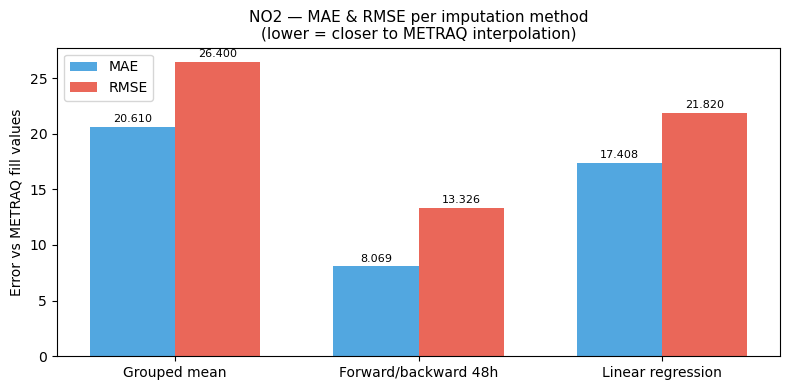

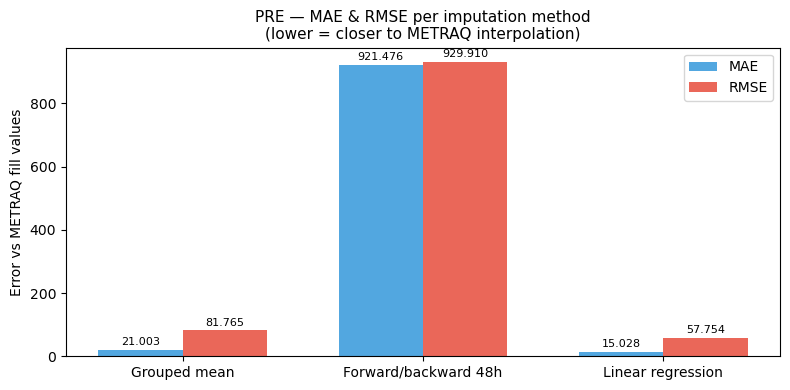

In [45]:
imputed_results = {
    'Grouped mean': df_mean,
    'Forward/backward 48h': df_ffill,
    'Linear regression': df_regression,
}

for FOCUS_VAR in ['NO2', 'PRE']:
    metrics = compare_methods(df_metraq, imputed_results, FOCUS_VAR)


    plot_metrics_bar(metrics, FOCUS_VAR)

## **Conclusions** on Attempts of Improvement of Imputation
A method is preferable if it satisfies these 3 conditions:
1. It has *high coverage* (no more than 30% of missing values)
2. It performs well in the *artificial missingness test.*
3. Its distribution remains close to the observed real data and does not create implausible values.

*Artificial missingness test*: taking values that are actually observed and real, temporarily hiding them by replacing them with NaN, then running the imputation methods to reconstruct them.


### Variable selection for distribution comparison

Six variables are selected to represent structurally different regimes of missingness
and behaviour, so that conclusions generalise beyond a single case.

- **NO2** — the primary pollutant of interest throughout this analysis and a key
  EU air-quality indicator. All three methods achieve 100 % coverage on NO2, so the
  comparison isolates *quality* of fill rather than coverage. Any distribution shift
  relative to real observations is attributable purely to the imputation logic, not
  to missing data.

- **NO** — similar missingness volume to NO2 but forward/backward fill only covers
  ~45 % of slots (gaps exceed the 48-hour limit). This introduces a coverage
  difference alongside the quality comparison, showing how an incomplete fill
  distorts the empirical distribution.

- **O3** — ozone has a distinct diurnal cycle driven by photochemical reactions:
  it peaks in the afternoon and is depleted overnight, the inverse of NO and NO2.
  Including O3 tests whether each method preserves a non-trivial temporal structure
  that is different from the nitrogen oxides.

- **NOX** — in the numerical comparison (MAE vs METRAQ) forward/backward fill
  produced an error more than twice that of mean imputation. Examining the
  distribution explains *why*: very long gaps cause stale-value propagation that
  pushes the distribution far from the observed range.

- **TEMP** — an intermediate meteorological case. Missingness is high (~645k slots)
  but not as extreme as pressure. Regression fills completely; the other two methods
  fill only partially. Temperature also has a strong seasonal structure, so it tests
  whether the regression model captures slow trends that mean and fill ignore.

- **PRE** — atmospheric pressure represents the hardest case in the dataset: over
  90 % of values were originally missing. Mean imputation covers only 0.2 % of
  slots; forward/backward fill covers 0.05 %. Only linear regression achieves full
  coverage. This variable demonstrates the regime where simpler methods are not
  viable and the distribution comparison has only one real participant.


### Showing Coverage Distributions and Distance from METRAQ's values


The KS distance measures the maximum difference between the cumulative distribution of real observed values and the cumulative distribution of imputed values. It is used here to evaluate whether an imputation method preserves the empirical distribution of the original data. A lower KS distance indicates that the imputed values are distributionally closer to the real observations.

The closer the values, the more the imputed values look like the original ones.


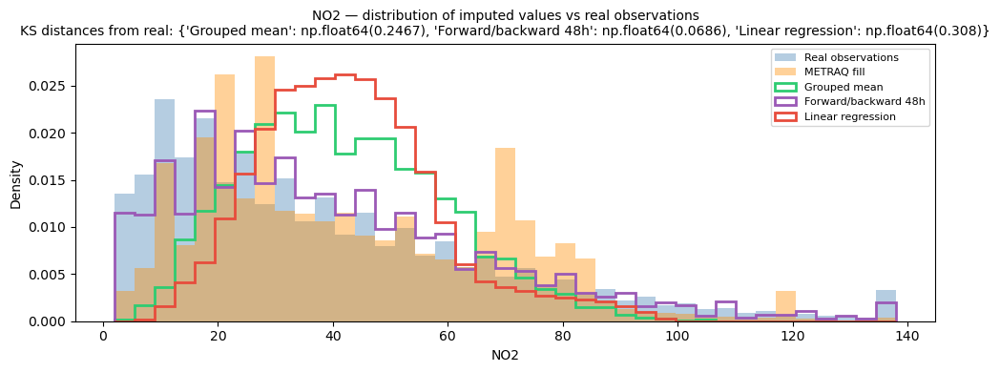

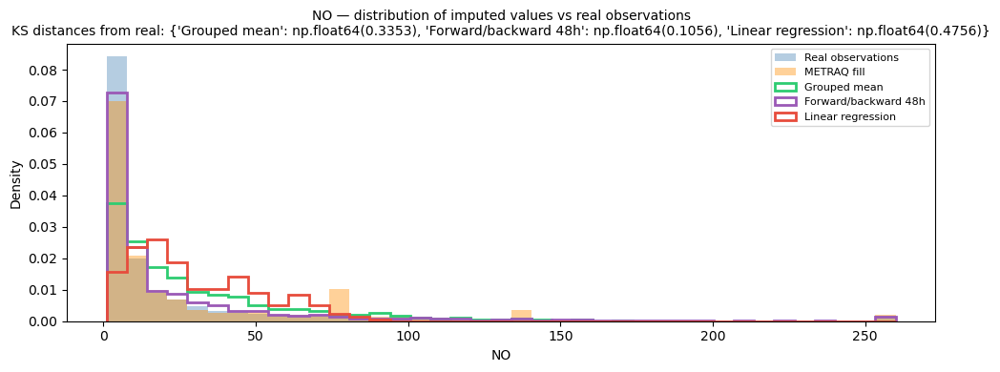

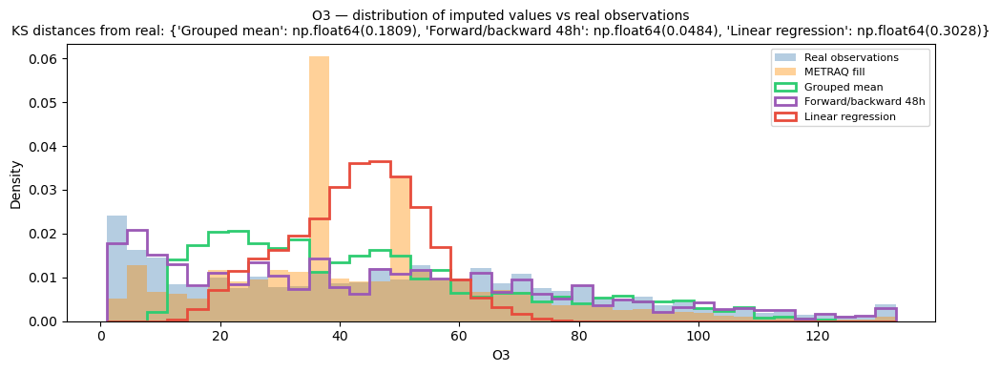

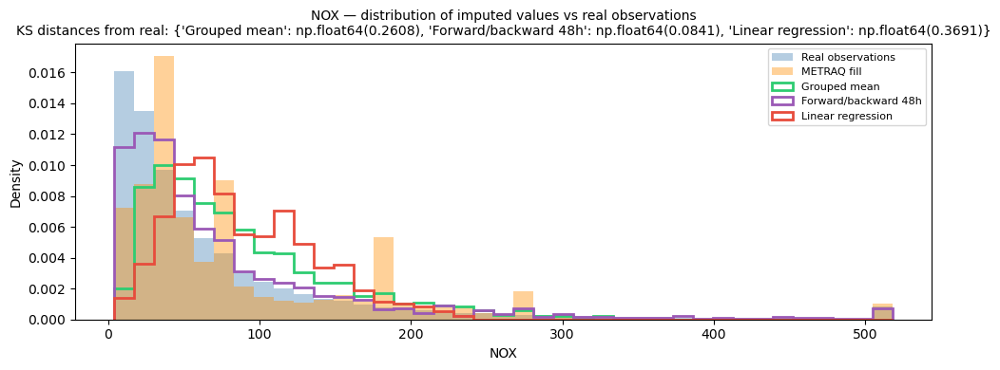

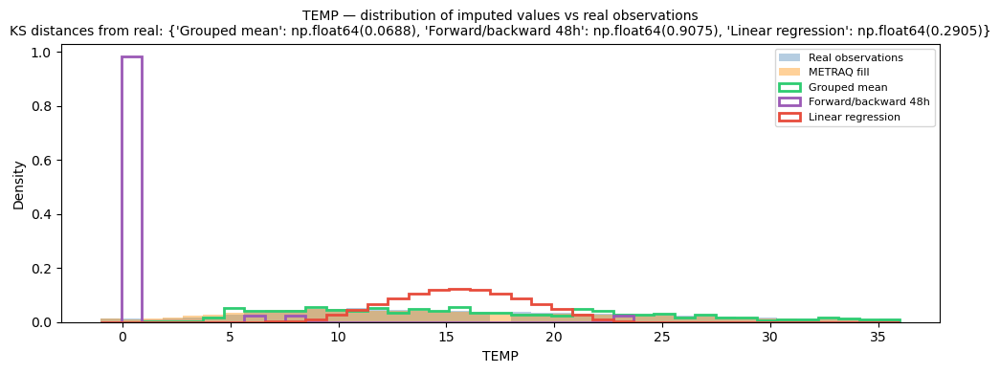

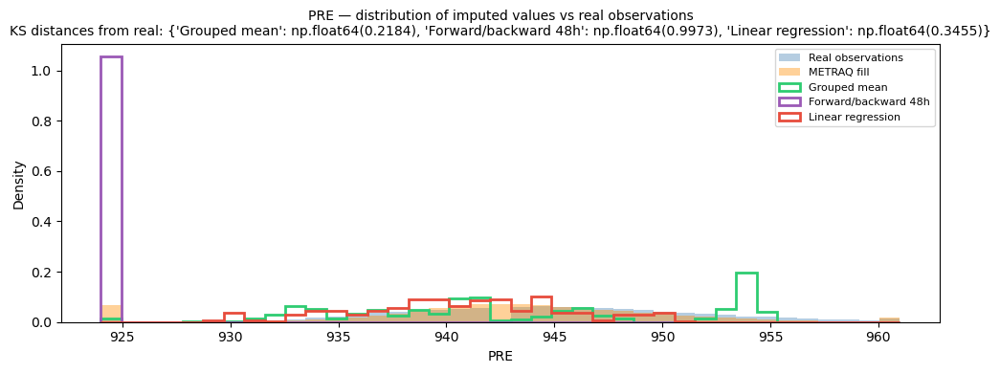

In [46]:
def plot_distribution_comparison(df_metraq, imputed_results, variable):

    real_mask   = (df_metraq['magnitude_name'] == variable) & ~df_metraq['is_interpolated']
    interp_mask = (df_metraq['magnitude_name'] == variable) &  df_metraq['is_interpolated']

    real_vals   = df_metraq.loc[real_mask,   'value'].dropna().astype(float)
    metraq_fill = df_metraq.loc[interp_mask, 'value'].dropna().astype(float)

    lo, hi = real_vals.quantile(0.01), real_vals.quantile(0.99)
    bins = np.linspace(lo, hi, 40)

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(real_vals.clip(lo, hi), bins=bins, density=True, alpha=0.4, color='steelblue', label='Real observations')
    ax.hist(metraq_fill.clip(lo, hi), bins=bins, density=True, alpha=0.4, color='darkorange', label='METRAQ fill')

    colors = ['#2ECC71', '#9B59B6', '#E74C3C']
    ks_results = {}
    for i, (name, imp_df) in enumerate(imputed_results.items()):
        vals = imp_df.loc[interp_mask, 'value'].dropna().astype(float)
        if len(vals) == 0:
            continue
        ax.hist(vals.clip(lo, hi), bins=bins, density=True, histtype='step',
                lw=2, color=colors[i], label=name)
        stat, _ = ks_2samp(real_vals, vals)
        ks_results[name] = round(stat, 4)

    ax.set_title(f'{variable} — distribution of imputed values vs real observations\n'
                 f'KS distances from real: {ks_results}', fontsize=10)
    ax.set_xlabel(variable); ax.set_ylabel('Density'); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

COMPARISON_VARS = ['NO2', 'NO', 'O3', 'NOX', 'TEMP', 'PRE']
for v in COMPARISON_VARS:
    plot_distribution_comparison(df_metraq, imputed_results, v)

## Distributional Comparison of Imputation Methods

To evaluate the imputation methods, the distributions of the imputed values are compared with the distribution of real observations. The Kolmogorov–Smirnov distance is used as a distributional metric: lower values indicate that the imputed distribution is closer to the real observed distribution.

The comparison includes three imputation methods: grouped mean, forward/backward fill within 48 hours, and linear regression. METRAQ fill is also plotted as the benchmark interpolation provided by the dataset.

---

### NO2

For NO2, the forward/backward 48-hour method performs best, with the lowest KS distance.

| Method | KS distance |
|---|---:|
| Grouped mean | 0.2467 |
| Forward/backward 48h | 0.0686 |
| Linear regression | 0.3080 |

This is a strong result because all methods achieve complete coverage for NO2, so the comparison mainly reflects imputation quality rather than differences in filled values. NO2 is a traffic-related pollutant with strong short-term temporal dependence, meaning that nearby hourly observations are highly informative. For this reason, forward/backward fill preserves the real distribution better than the other methods.

Grouped mean smooths the distribution and reduces variability, while linear regression shifts the distribution toward medium-high values and fails to capture local pollution peaks.

**Conclusion:** for NO2, forward/backward 48h is the most appropriate method because it best preserves the temporal structure of the pollutant.

---

### NO

For NO, forward/backward 48-hour fill also gives the closest distribution to real observations.

| Method | KS distance |
|---|---:|
| Grouped mean | 0.3353 |
| Forward/backward 48h | 0.1056 |
| Linear regression | 0.4756 |

NO is a highly volatile pollutant, strongly linked to direct local emissions such as traffic. Its distribution is very skewed, with many low values and occasional high peaks. The forward/backward method works best because it uses nearby real observations, which better preserve this short-term variability.

However, this method has a coverage limitation for NO, since it fills only the gaps that are short enough to fall within the 48-hour window. Grouped mean smooths the distribution too much, while linear regression performs worst because NO is too local and irregular to be captured well by a simple model.

**Conclusion:** for NO, forward/backward 48h is best in terms of distributional quality, but it is incomplete when gaps are longer than 48 hours.

---

### O3

For O3, forward/backward 48-hour fill is again the best-performing method.

| Method | KS distance |
|---|---:|
| Grouped mean | 0.1809 |
| Forward/backward 48h | 0.0484 |
| Linear regression | 0.3028 |

O3 is different from NO and NO2 because it is a secondary pollutant with a strong photochemical and daily cycle. It usually increases during daylight and decreases overnight. The good performance of forward/backward fill shows that nearby observations are still very informative, even for a pollutant with a different temporal pattern.

Grouped mean captures part of the general range but ignores the daily cycle. Linear regression is less accurate because it concentrates values around a central range and does not reproduce the full observed variability.

**Conclusion:** for O3, forward/backward 48h is best because it preserves the local temporal continuity of the ozone cycle.

---

### NOX

For NOX, forward/backward 48-hour fill has the lowest KS distance.

| Method | KS distance |
|---|---:|
| Grouped mean | 0.2608 |
| Forward/backward 48h | 0.0841 |
| Linear regression | 0.3691 |

NOX combines nitrogen oxides and behaves similarly to NO and NO2, being strongly influenced by traffic emissions and short-term atmospheric conditions. The forward/backward method therefore performs best because it uses local temporal information, which is more realistic than a static average.

Grouped mean produces a smoother distribution and does not reproduce the observed skewness as well. Linear regression performs worst because it shifts the distribution away from the real observations.

This case also shows the difference between pointwise and distributional evaluation. A method may not match METRAQ exactly at each timestamp, but it can still produce a distribution that is closer to real observed data.

**Conclusion:** for NOX, forward/backward 48h is the best method from a distributional perspective.

---

### TEMP

For TEMP, the pattern changes: grouped mean is the best-performing method.

| Method | KS distance |
|---|---:|
| Grouped mean | 0.0688 |
| Forward/backward 48h | 0.9075 |
| Linear regression | 0.2905 |

Temperature is a meteorological variable with smoother behaviour than pollutants. It has seasonal and daily patterns, but it is less affected by sudden local peaks. In this case, grouped mean provides a stable approximation and remains closest to the real distribution.

Forward/backward fill performs very poorly, creating an artificial spike around zero. This suggests that the method is not suitable for TEMP in the current setting, possibly because of long gaps, partial coverage, or the way remaining missing values are handled. Linear regression performs better than forward/backward fill, but still does not match the real distribution as closely as grouped mean.

**Conclusion:** for TEMP, grouped mean is the most distributionally stable method, while forward/backward fill is not appropriate.

---

### PRE

For PRE, the interpretation depends on both distributional similarity and coverage.

| Method | KS distance |
|---|---:|
| Grouped mean | 0.2184 |
| Forward/backward 48h | 0.9973 |
| Linear regression | 0.3455 |

Atmospheric pressure is the hardest variable because more than 90% of its values were originally missing. Grouped mean has the lowest KS distance, but this result is limited because it fills only a very small fraction of the missing values. Therefore, it cannot be considered practically sufficient.

Forward/backward fill is clearly not viable: the KS distance is almost 1, and the plot shows an artificial concentration around a narrow pressure value. This happens because the gaps are too long for a short-window temporal method.

Linear regression has a higher KS distance than grouped mean, but it is the only method that achieves full coverage. For this reason, regression is the most practically usable method for PRE, even though its distributional fit is not perfect.

**Conclusion:** for PRE, linear regression is the most viable method because coverage is essential under extreme missingness.

---

## Overall Interpretation

The results show that the best imputation method depends on the type of variable and on the missingness regime.

For **pollutant** variables such as NO2, NO, O3, and NOX, forward/backward 48-hour fill consistently produces the closest distribution to real observations. This indicates that pollutant time series have strong short-term temporal dependence, so nearby real observations are highly informative.

For **meteorological** variables, the pattern is different. TEMP is better approximated by grouped mean, suggesting that smoother seasonal variables can benefit from stable group-level values. PRE represents an extreme missingness case: grouped mean may appear closer distributionally on the small subset it fills, but linear regression is the only practically usable method because it achieves full coverage.

Overall, no single imputation method dominates across all variables. Forward/backward fill is preferred for temporally dense pollutants, grouped mean is more stable for smoother meteorological variables, and linear regression becomes useful when coverage is the main priority.


# 4. Temporal patterns
Identifying patterns and pollution cycles.


### Creating time features and choosing time granularity

To study pollution across multiple time scales, `entry_date` is decomposed into several granularity columns. This is justified by the different cycles that urban air quality data exhibit simultaneously:

- **Intra-day** (`hour`): captures the diurnal cycle driven by traffic rush hours and solar radiation.
- **Intra-week** (`day_of_week`): allows comparison of weekday vs. weekend behaviour.
- **Seasonal** (`month`): reflects meteorological drivers such as temperature inversions, wind patterns, precipitation.
- **Long-term** (`year`, `year_month`): tracks multi-year regulatory and infrastructure changes.


In [47]:
def add_time_columns(df):
    df = df.copy()
    dt = df['entry_date'].dt
    df['year']        = dt.year.astype('int16')
    df['month']       = dt.month.astype('int8')
    df['day_of_week'] = dt.dayofweek.astype('int8')
    df['hour']        = dt.hour.astype('int8')
    df['date']        = dt.date
    df['year_month']  = dt.to_period('M')
    return df

df_time  = add_time_columns(df)
df_focus = df_time[df_time['magnitude_name'].isin(POLLUTANTS)].copy()

`df_focus` restricts to the pollutant variables listed in `POLLUTANTS`. Meteorological variables (TEMP, PRE, etc.) are excluded here because their temporal cycles are driven by different mechanisms and would require separate treatment; this task focuses specifically on pollution patterns.


In [48]:
def daily_medians(df, variables):
    subset = df[df['magnitude_name'].isin(variables)]
    agg = (
        subset
        .groupby(['sensor_id', 'magnitude_name', 'date'], observed=True)['value']
        .median()
        .reset_index()
        .rename(columns={'value': 'daily_median'})
    )
    agg['date'] = pd.to_datetime(agg['date'])
    return agg

def monthly_city_mean(daily):
    daily = daily.copy()
    daily['year_month'] = daily['date'].dt.to_period('M')
    monthly = (
        daily
        .groupby(['year_month', 'magnitude_name'], observed=True)['daily_median']
        .agg(monthly_mean='mean', monthly_std='std')
        .reset_index()
    )
    monthly['year']  = monthly['year_month'].dt.year.astype('int16')
    monthly['month'] = monthly['year_month'].dt.month.astype('int8')
    return monthly

daily   = daily_medians(df_focus, POLLUTANTS)
monthly = monthly_city_mean(daily)
print('Daily medians shape :', daily.shape)
print('Monthly means shape :', monthly.shape)

Daily medians shape : (1063993, 4)
Monthly means shape : (3864, 6)


Daily medians are computed per sensor before aggregating to the city level. Using the **median** rather than the mean limits the influence of sensor-level outliers on the city-wide picture. The monthly standard deviation is retained alongside the mean to capture spatial-temporal variability within each calendar month.


### Long-run Monthly Trends (2001–2024)

To detect long-term changes in pollution levels, monthly city-wide averages are plotted for the entire 23-year period. A shaded ±1 σ band around the monthly mean captures within-month variability and reveals whether periods of high concentration become rarer over time.


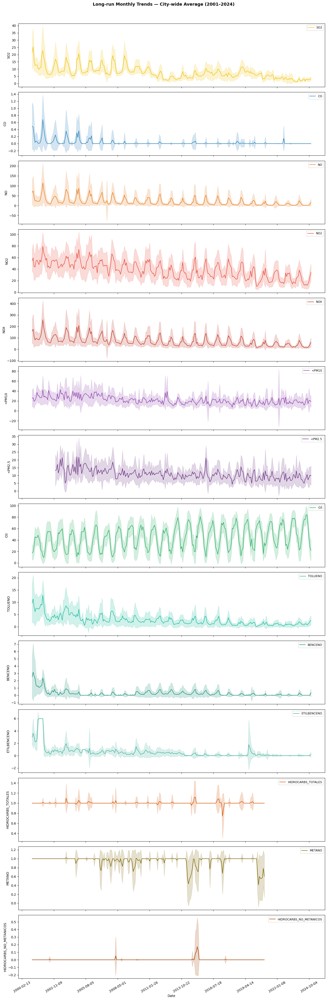

In [49]:
COLORS = {
    'NO2'                    : '#e74c3c',
    'NO'                     : '#e67e22',
    'NOX'                    : '#c0392b',
    'SO2'                    : '#f1c40f',
    'CO'                     : '#2980b9',
    'O3'                     : '#27ae60',
    '<PM10'                  : '#8e44ad',
    '<PM2.5'                 : '#6c3483',
    'TOLUENO'                : '#1abc9c',
    'BENCENO'                : '#148f77',
    'ETILBENCENO'            : '#45b39d',
    'HIDROCARBS_TOTALES'     : '#d35400',
    'METANO'                 : '#7d6608',
    'HIDROCARBS_NO_METANICOS': '#a04000',
}

def plot_long_run_trends(monthly, variables, colors):
    n = len(variables)
    fig, axes = plt.subplots(n, 1, figsize=(14, 3 * n), sharex=True)
    fig.suptitle('Long-run Monthly Trends — City-wide Average (2001–2024)',
                 fontsize=13, fontweight='bold', y=1.01)
    for ax, var in zip(axes, variables):
        sub = monthly[monthly['magnitude_name'] == var].sort_values('year_month')
        t   = sub['year_month'].dt.to_timestamp()
        mu  = sub['monthly_mean']
        sd  = sub['monthly_std'].fillna(0)
        col = colors.get(var, '#555')
        ax.fill_between(t, mu - sd, mu + sd, alpha=0.2, color=col)
        ax.plot(t, mu, color=col, linewidth=1.4, label=var)
        ax.set_ylabel(var, fontsize=10)
        ax.legend(loc='upper right', fontsize=9)
        ax.xaxis.set_major_locator(mticker.MaxNLocator(12))
        ax.tick_params(axis='x', rotation=30)
    axes[-1].set_xlabel('Date', fontsize=10)
    plt.tight_layout()
    plt.show()

plot_long_run_trends(monthly, POLLUTANTS, COLORS)

The long-run trends confirm a clear downward trajectory for the main traffic-related pollutants. **NO2, NO, NOX, and CO** all decline substantially from 2001 to 2024. This aligns with successive EU air quality directives and the expansion of Madrid's Low Emission Zone (LEZ) from 2018 onward, which restricted older, high-emission vehicles from the city centre.

**SO2** shows the steepest early decline, reflecting mandatory reductions in sulphur content in fuels during the early 2000s. **Benzene and toluene** follow a similar pattern tied to petrol composition regulation. **Particulate matter (PM10, PM2.5)** shows moderate decline with noticeable interannual variability, partly driven by episodic Saharan dust intrusions.

**O3** is the notable exception: it shows no downward trend and even a modest increase over recent years. This is consistent with the *ozone paradox* — as NOx emissions fall, the titration of ozone by NO is reduced, allowing background O3 to accumulate at higher levels.


### Year-over-Year Annual Means

Aggregating to annual resolution removes the seasonal component and makes it easier to read the direction and pace of longer term change for each pollutant.


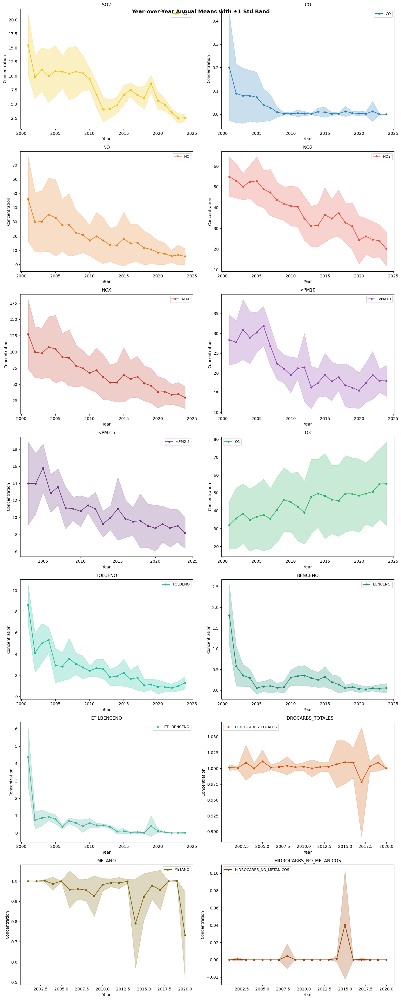

In [50]:
def annual_means(monthly):
    return (
        monthly
        .groupby(['year', 'magnitude_name'], observed=True)['monthly_mean']
        .agg(annual_mean='mean', annual_std='std')
        .reset_index()
    )

def plot_annual_trends(annual, variables, colors):
    fig, axes = plt.subplots(7, 2, figsize=(14, 35), sharey=False)
    axes = axes.flatten()
    fig.suptitle('Year-over-Year Annual Means with ±1 Std Band',
                 fontsize=13, fontweight='bold')
    for ax, var in zip(axes, variables):
        sub = annual[annual['magnitude_name'] == var].sort_values('year')
        col = colors.get(var, '#555')
        ax.fill_between(sub['year'],
                        sub['annual_mean'] - sub['annual_std'],
                        sub['annual_mean'] + sub['annual_std'],
                        alpha=0.25, color=col)
        ax.plot(sub['year'], sub['annual_mean'],
                marker='o', markersize=4, linewidth=1.5,
                color=col, label=var)
        ax.set_title(var, fontsize=11)
        ax.set_xlabel('Year')
        ax.set_ylabel('Concentration')
        ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

annual = annual_means(monthly)
plot_annual_trends(annual, POLLUTANTS, COLORS)

The annual means confirm the monthly-level findings with less noise. For **NO2**, the decline accelerates visibly after 2018, consistent with the Madrid LEZ. **SO2** annual means reach near-zero by 2010 and remain flat, indicating that the initial fuel-quality regulatory effect was quickly saturated. **O3** shows a persistent upward creep in annual means after 2010, reinforcing the photochemical interpretation.

The variability bands are widest for **NO and NOX**, reflecting sensitivity to individual high-emission episodes and to meteorological conditions that differ year-to-year.


### Seasonal Cycle

Seasonal boxplots show the distribution of monthly city-wide averages grouped by calendar month, isolating the repeating annual cycle from the long-term trend.


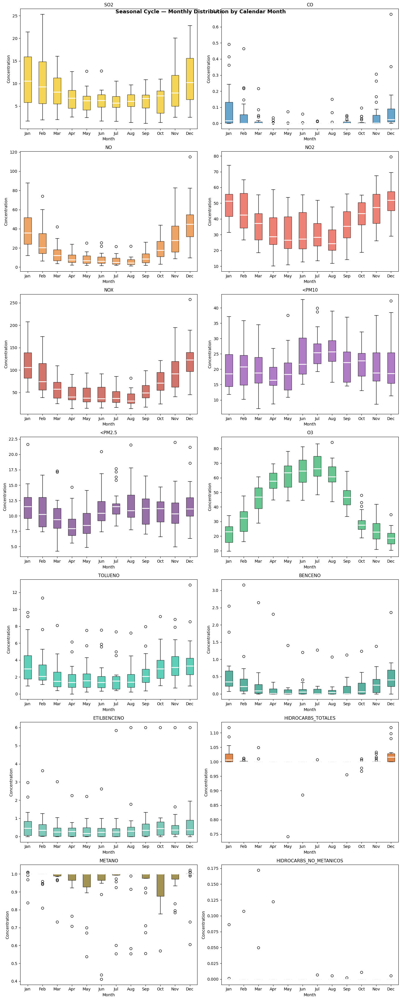

In [51]:
MONTH_LABELS = ['Jan','Feb','Mar','Apr','May','Jun',
                'Jul','Aug','Sep','Oct','Nov','Dec']

def plot_seasonal_boxplots(monthly, variables, colors, month_labels):
    fig, axes = plt.subplots(7, 2, figsize=(14, 35), sharey=False)
    axes = axes.flatten()
    fig.suptitle('Seasonal Cycle — Monthly Distribution by Calendar Month',
                 fontsize=13, fontweight='bold')
    for ax, var in zip(axes, variables):
        sub  = monthly[monthly['magnitude_name'] == var]
        data = [sub.loc[sub['month'] == m, 'monthly_mean'].dropna().values
                for m in range(1, 13)]
        col  = colors.get(var, '#555')
        bp = ax.boxplot(data, patch_artist=True, notch=False,
                        medianprops=dict(color='white', linewidth=2))
        for patch in bp['boxes']:
            patch.set_facecolor(col)
            patch.set_alpha(0.7)
        ax.set_xticks(range(1, 13))
        ax.set_xticklabels(month_labels)
        ax.set_title(var, fontsize=11)
        ax.set_xlabel('Month')
        ax.set_ylabel('Concentration')
    plt.tight_layout()
    plt.show()

plot_seasonal_boxplots(monthly, POLLUTANTS, COLORS, MONTH_LABELS)

The seasonal patterns divide sharply into two opposing regimes:

**Winter-peaking pollutants (NO, NO2, NOX, SO2, CO, PM10, PM2.5):** concentrations are highest in December–February and lowest in June–August. Cold temperatures strengthen thermal inversions that trap pollutants near the surface, and reduced photochemical degradation allows accumulation of directly emitted species.

**Summer-peaking pollutant (O3):** ozone peaks in June/August, driven by intense solar radiation and photochemical production from NOx and VOC precursors. Its seasonal cycle is nearly the mirror image of NO2.

The spread within each month is largest for **NO and NOX**, reflecting their sensitivity to local traffic episodes, and narrowest for **O3**, whose slow photochemical cycle is more meteorologically stable.


### Diurnal Cycle

The typical within-day profile of each pollutant.


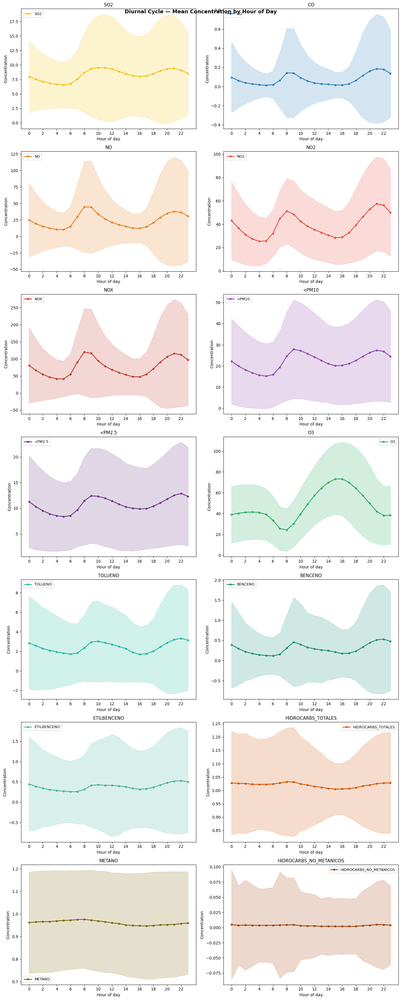

In [52]:
def hourly_profiles(df, variables):
    subset = df[df['magnitude_name'].isin(variables)]
    return (
        subset
        .groupby(['magnitude_name', 'hour'], observed=True)['value']
        .agg(hour_mean='mean', hour_std='std')
        .reset_index()
    )

def plot_diurnal_profiles(hourly, variables, colors):
    fig, axes = plt.subplots(7, 2, figsize=(14, 35), sharey=False)
    axes = axes.flatten()
    fig.suptitle('Diurnal Cycle — Mean Concentration by Hour of Day',
                 fontsize=13, fontweight='bold')
    for ax, var in zip(axes, variables):
        sub = hourly[hourly['magnitude_name'] == var].sort_values('hour')
        col = colors.get(var, '#555')
        mu  = sub['hour_mean']
        sd  = sub['hour_std'].fillna(0)
        ax.fill_between(sub['hour'], mu - sd, mu + sd, alpha=0.2, color=col)
        ax.plot(sub['hour'], mu, color=col, linewidth=2, marker='o',
                markersize=4, label=var)
        ax.set_title(var, fontsize=11)
        ax.set_xlabel('Hour of day')
        ax.set_ylabel('Concentration')
        ax.set_xticks(range(0, 24, 2))
        ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

hourly = hourly_profiles(df_focus, POLLUTANTS)
plot_diurnal_profiles(hourly, POLLUTANTS, COLORS)

The diurnal profiles reveal signatures that directly reflect the physical and chemical processes governing each pollutant:

**NO and NO2** both show a double-peak structure: a sharp morning rush peak (07:00–09:00) and a broader evening peak (19:00–21:00), aligning with Madrid's commuting patterns. NO2 is slightly delayed relative to NO because freshly emitted NO is oxidised to NO2 in the minutes following emission.

**O3** shows the inverse pattern: it is lowest in the early morning (depleted overnight by reaction with NO) and peaks in the afternoon (14:00–16:00) when solar radiation drives maximum photochemical production. This is the clearest marker distinguishing a primary from a secondary pollutant.

**CO** mirrors the traffic signature closely, confirming its origin as a direct combustion product. The morning peak is sharper than the evening one, suggesting that morning boundary-layer inversions concentrate emissions more effectively.

**SO2** shows a weaker diurnal cycle, consistent with mixed residential and industrial sources less tied to the daily commuting schedule.


### Day-of-Week Effect

Testing if pollution levels follow human activity schedules. Weekday bars (Mon–Fri) are shown in the pollutant colour while weekend bars (Sat–Sun) in grey.


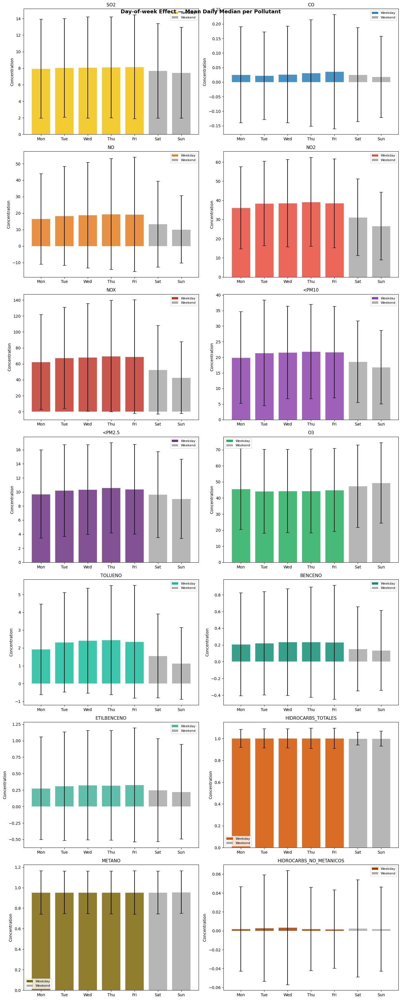

In [53]:
DOW_LABELS = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']

def dow_profiles(daily, variables):
    daily = daily.copy()
    daily['day_of_week'] = daily['date'].dt.dayofweek
    subset = daily[daily['magnitude_name'].isin(variables)]
    return (
        subset
        .groupby(['magnitude_name', 'day_of_week'], observed=True)['daily_median']
        .agg(dow_mean='mean', dow_std='std')
        .reset_index()
    )

def plot_dow_profiles(dow, variables, colors, dow_labels):
    fig, axes = plt.subplots(7, 2, figsize=(14, 35), sharey=False)
    axes = axes.flatten()
    fig.suptitle('Day-of-week Effect — Mean Daily Median per Pollutant',
                 fontsize=13, fontweight='bold')
    for ax, var in zip(axes, variables):
        sub = dow[dow['magnitude_name'] == var].sort_values('day_of_week')
        col = colors.get(var, '#555')
        bar_colors = [col if d < 5 else '#aaaaaa' for d in sub['day_of_week']]
        ax.bar(sub['day_of_week'], sub['dow_mean'],
               yerr=sub['dow_std'], capsize=4,
               color=bar_colors, alpha=0.85, edgecolor='white')
        ax.set_xticks(range(7))
        ax.set_xticklabels(dow_labels)
        ax.set_title(var, fontsize=11)
        ax.set_ylabel('Concentration')
        ax.legend(handles=[
            mpatches.Patch(facecolor=col,        label='Weekday'),
            mpatches.Patch(facecolor='#aaaaaa',  label='Weekend'),
        ], fontsize=8)
    plt.tight_layout()
    plt.show()

dow = dow_profiles(daily, POLLUTANTS)
plot_dow_profiles(dow, POLLUTANTS, COLORS, DOW_LABELS)

The day-of-week profiles provide strong evidence that vehicular traffic drives the combustion-related pollutants:

**NO, NO2, NOX, CO** are all significantly elevated on weekdays compared to weekends. The drop on Saturdays and Sundays (15–25% below midweek peaks) is consistent across all years and sensor locations, confirming that emission intensity is proportional to traffic volume.

**O3** shows the opposite response: weekend concentrations are slightly but consistently higher than weekday values. This is the **weekend O3 paradox**: lower NOx on weekends reduces the chemical destruction of O3 by NO (via NO + O3 → NO2 + O2), allowing ozone to accumulate despite lower precursor availability.

**SO2** shows no strong weekday/weekend contrast therefore it is consistent with emission sources that operate on schedules unrelated to commuting.


### Month × Hour Interaction (Heatmaps)

The month-hour heatmap combines seasonal and diurnal information into a single 12×24 grid, revealing how the daily cycle shifts across the year. To focus on structurally distinct behaviours, only five representative pollutants are shown: **NO2** (primary traffic tracer), **NO** (direct combustion emission), **O3** (secondary photochemical), **SO2** (non-traffic source), and **CO** (combustion tracer).


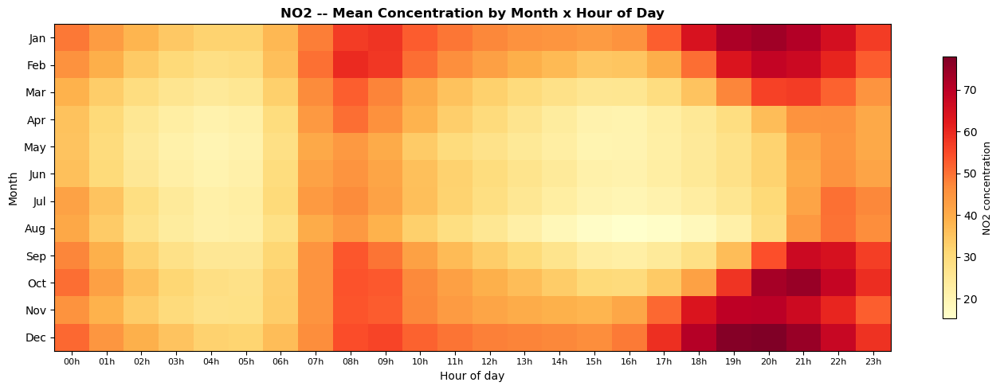

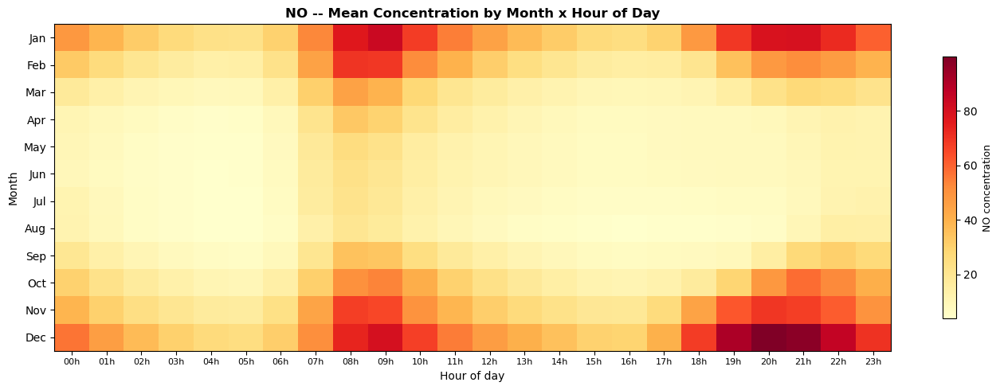

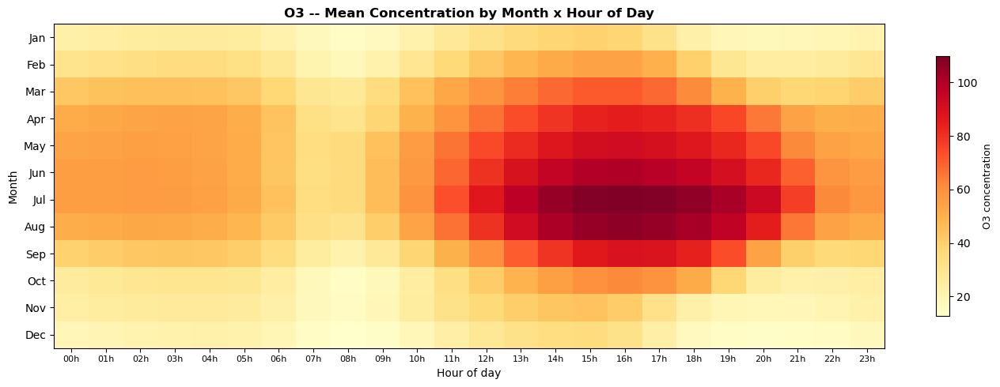

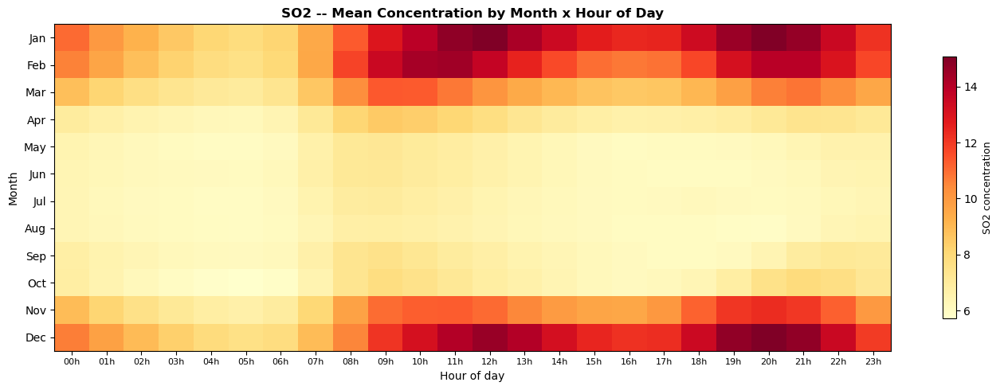

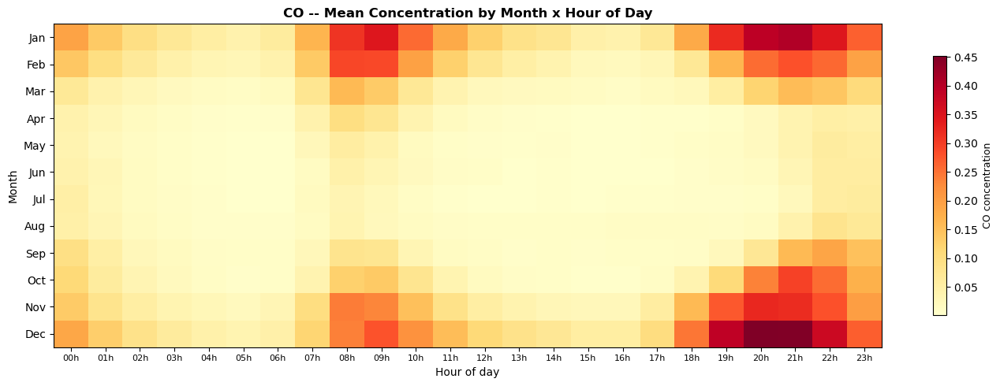

In [54]:
HEATMAP_VARS = ['NO2', 'NO', 'O3', 'SO2', 'CO']

def month_hour_matrix(df, variable):
    subset = df[df['magnitude_name'] == variable]
    return (
        subset
        .groupby(['month', 'hour'], observed=True)['value']
        .mean()
        .unstack(level='hour')
    )

def plot_month_hour_heatmap(matrix, variable, month_labels):
    fig, ax = plt.subplots(figsize=(14, 5))
    im = ax.imshow(matrix.values, aspect='auto', cmap='YlOrRd', origin='upper')
    ax.set_xticks(range(24))
    ax.set_xticklabels([f'{h:02d}h' for h in range(24)], fontsize=8)
    ax.set_yticks(range(12))
    ax.set_yticklabels(month_labels)
    ax.set_xlabel('Hour of day', fontsize=10)
    ax.set_ylabel('Month', fontsize=10)
    ax.set_title(f'{variable} -- Mean Concentration by Month x Hour of Day',
                 fontsize=12, fontweight='bold')
    cbar = fig.colorbar(im, ax=ax, shrink=0.8)
    cbar.set_label(f'{variable} concentration', fontsize=9)
    plt.tight_layout()
    plt.show()

for var in HEATMAP_VARS:
    mat = month_hour_matrix(df_focus, var)
    if not mat.empty:
        plot_month_hour_heatmap(mat, var, MONTH_LABELS)

The heatmaps show how diurnal and seasonal cycles combine and reinforce each other:

**NO2** has its highest concentrations in winter mornings (07:00–09:00, December–February), forming a prominent hot-spot in the upper-left of the grid. Values drop sharply toward summer afternoons, where photolytic decomposition and stronger mixing limit accumulation.

**NO** mirrors NO2 but with steeper contrast: extremely high winter morning values and near-zero summer afternoon values, reflecting the dual effect of direct NOx chemistry and photochemical loss.

**O3** presents the complementary pattern: maximum values appear in summer afternoons (12:00–18:00, June–August) while winter mornings are consistently cold. The anti-correlation with NO in the month-hour space is a direct visual confirmation of the O3–NOx equilibrium.

**SO2** has a diffuse pattern with only a mild winter morning concentration, confirming the absence of a sharp commuting-related driver.

**CO** closely tracks NO2 but with a slightly broader hot-spot region, consistent with CO's longer atmospheric lifetime relative to NO.


## Summary




| Scale | Key finding |
|---|---|
| Long-term | NO2, CO, SO2 declined significantly (2001–2024); O3 increased due to reduced NOx scavenging |
| Seasonal | Combustion pollutants peak in winter (inversions); O3 peaks in summer (photochemistry) |
| Diurnal | Traffic pollutants show double rush-hour peaks; O3 peaks in the afternoon as a secondary product |
| Weekly | Strong weekday/weekend contrast for traffic species; O3 weekend paradox confirmed |


# 5. Spatial sensor network

Goal: Build a network based on sensor locations.


### Introduction and Pipeline

This section models sensors in a graph, where each of the 24 sensors constitutes a node and physical proximity between stations determines whether an edge is drawn between them. We assume that sensors that are geographically close tend to be exposed to the same pollution sources and atmospheric conditions, so understanding the spatial structure of the network is a prerequisite for interpreting some of the patterns in the data.

The analysis proceeds through several steps. First, the unique (x, y) coordinates of every sensor are extracted from the dataset using the UTM projection system, and a symmetric pairwise distance matrix is computed over all 276 possible sensor pairs. A connectivity sweep then varies the maximum allowable distance from zero to the network diameter, tracking how many edges appear and how many connected components remain as the threshold increases. This reveals the critical distance (approximately 7 km) at which the network first becomes fully connected, corresponding to the maximum edge weight in the minimum spanning tree.

With this threshold as a reference, a k-nearest-neighbour (kNN) graph is constructed using k = 3, meaning each sensor is connected to its three closest geographic neighbours regardless of absolute distance. This method guarantees every node has at least three connections while remaining sparse enough to be analytically tractable. On the resulting graph, standard network metrics are computed: node degree (number of connections), betweenness centrality (how often a node lies on the shortest path between other nodes), closeness centrality (average inverse distance to all other nodes), and the local clustering coefficient (the fraction of a node's neighbours that are also neighbours of each other). Finally, community detection is performed using the greedy modularity maximisation algorithm, which partitions the network into groups of sensors that are more densely connected internally than externally.


In [55]:
def extract_sensors(df):
    sensors = (
        df[['sensor_id', 'sensor_name', 'utm_x', 'utm_y']]
        .drop_duplicates('sensor_id')
        .sort_values('sensor_id')
        .reset_index(drop=True)
    )
    return sensors


def pairwise_distance_matrix(sensors):
    coords = sensors[['utm_x', 'utm_y']].values.astype(float)
    n      = len(coords)
    dist   = np.zeros((n, n))
    for i in range(n):
        diff       = coords - coords[i]          # (N, 2)
        dist[i, :] = np.sqrt((diff ** 2).sum(axis=1))
    return dist


def distance_summary(dist: np.ndarray) -> None:
    n      = dist.shape[0]
    upper  = dist[np.triu_indices(n, k=1)]
    print(f"Sensors          : {n}")
    print(f"Possible edges   : {len(upper):,}  (n*(n-1)/2)")
    print(f"Min distance     : {upper.min():.0f} m")
    print(f"Max distance     : {upper.max():.0f} m")
    print(f"Mean distance    : {upper.mean():.0f} m")
    print(f"Median distance  : {np.median(upper):.0f} m")
    print(f"p25 / p75        : {np.percentile(upper,25):.0f} m / "
          f"{np.percentile(upper,75):.0f} m")

sensors = extract_sensors(df)
dist    = pairwise_distance_matrix(sensors)

print(f"Sensor table shape : {sensors.shape}\n")
distance_summary(dist)
sensors.head(5)

Sensor table shape : (24, 4)

Sensors          : 24
Possible edges   : 276  (n*(n-1)/2)
Min distance     : 789 m
Max distance     : 21192 m
Mean distance    : 7969 m
Median distance  : 7517 m
p25 / p75        : 4709 m / 10452 m


,sensor_id,sensor_name,utm_x,utm_y
0,28079004,Plaza de España,439579.3291,4475049.263
1,28079008,Escuelas Aguirre,442117.2366,4474770.696
2,28079011,Ramón y Cajal,442564.0457,4478088.595
3,28079016,Arturo Soria,445786.1729,4476796.019
4,28079017,Villaverde,439420.7015,4466532.455


#### Threshold Graph Construction

A threshold graph connects two sensor nodes with an edge if and only if their Euclidean distance (in metres, UTM projection) is at most a given threshold $d^*$. Each edge carries a `distance` attribute and a `weight` of $1/d$, so that heavier weights encode proximity rather than separation.

Three helpers build on this representation:

- `build_threshold_graph` constructs the graph for a single threshold value.
 
- `connectivity_curve` sweeps a range of thresholds and records, for each one, the number of edges, the edge density as a percentage of the complete graph $K_n$, and the number of connected components.

- `mst_critical_threshold` finds the smallest threshold at which the graph first becomes fully connected, by computing the minimum spanning tree (MST) of the complete graph and returning its longest edge (the bottleneck distance).


MST critical threshold  : 6937 m  (6.9 km)
At 5 km threshold       : 26.4% edges, 2 components
At 10 km threshold      : 71.0% edges, 1 components
At 15 km threshold      : 93.8% edges, 1 components

Conclusion: naive distance threshold quickly collapses to K₂₄.
k-NN is a more principled approach for this dataset.


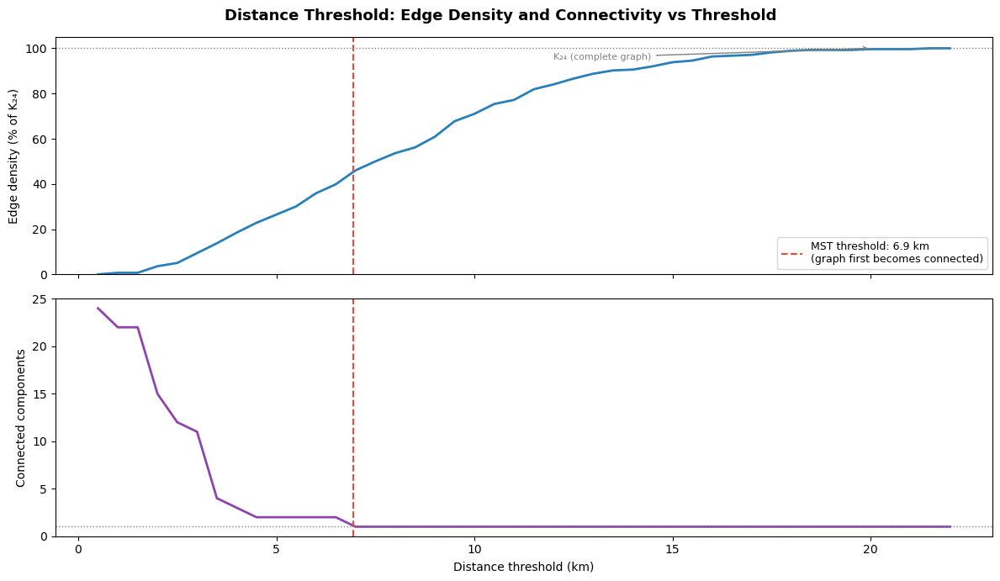

In [56]:
def build_threshold_graph(sensors, dist, threshold):
    G = nx.Graph()
    for i, row in sensors.iterrows():
        G.add_node(
            row['sensor_id'],
            name=str(row['sensor_name']),
            x=float(row['utm_x']),
            y=float(row['utm_y']),
        )
    n = len(sensors)
    ids = sensors['sensor_id'].values
    for i in range(n):
        for j in range(i + 1, n):
            d = dist[i, j]
            if d <= threshold:
                G.add_edge(ids[i], ids[j],
                           distance=d,
                           weight=1.0 / d)
    return G


def connectivity_curve(sensors, dist, thresholds):
    n_max   = len(sensors) * (len(sensors) - 1) // 2
    records = []
    for t in thresholds:
        G = build_threshold_graph(sensors, dist, t)
        records.append({
            'threshold'   : t,
            'n_edges'     : G.number_of_edges(),
            'edge_pct'    : G.number_of_edges() / n_max * 100,
            'n_components': nx.number_connected_components(G),
        })
    return pd.DataFrame(records)

def mst_critical_threshold(sensors, dist):
    G_full = build_threshold_graph(sensors, dist, threshold=dist.max() + 1)
    mst    = nx.minimum_spanning_tree(G_full, weight='distance')
    return max(d['distance'] for _, _, d in mst.edges(data=True))


def plot_connectivity_curve(curve, mst_thresh):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    fig.suptitle('Distance Threshold: Edge Density and Connectivity vs Threshold',
                 fontsize=13, fontweight='bold')

    # Edge density
    ax1.plot(curve['threshold'] / 1000, curve['edge_pct'],
             color='#2980b9', linewidth=2)
    ax1.axvline(mst_thresh / 1000, color='#e74c3c', linestyle='--', linewidth=1.5,
                label=f'MST threshold: {mst_thresh/1000:.1f} km\n(graph first becomes connected)')
    ax1.axhline(100, color='grey', linestyle=':', linewidth=1)
    ax1.set_ylabel('Edge density (% of K₂₄)')
    ax1.set_ylim(0, 105)
    ax1.legend(fontsize=9)
    ax1.annotate('K₂₄ (complete graph)', xy=(20, 100),
                 xytext=(12, 95), fontsize=8, color='grey',
                 arrowprops=dict(arrowstyle='->', color='grey'))

    # Connected components
    ax2.plot(curve['threshold'] / 1000, curve['n_components'],
             color='#8e44ad', linewidth=2)
    ax2.axvline(mst_thresh / 1000, color='#e74c3c', linestyle='--', linewidth=1.5)
    ax2.axhline(1, color='grey', linestyle=':', linewidth=1)
    ax2.set_ylabel('Connected components')
    ax2.set_xlabel('Distance threshold (km)')
    ax2.set_ylim(0, sensors['sensor_id'].nunique() + 1)

    plt.tight_layout()
    plt.show()

THRESH_RANGE  = range(500, 22_001, 500)

curve      = connectivity_curve(sensors, dist, THRESH_RANGE)
mst_thresh = mst_critical_threshold(sensors, dist)

print(f"MST critical threshold  : {mst_thresh:.0f} m  ({mst_thresh/1000:.1f} km)")
print(f"At 5 km threshold       : {curve.loc[curve['threshold']==5000, 'edge_pct'].values[0]:.1f}% edges, "
      f"{curve.loc[curve['threshold']==5000, 'n_components'].values[0]} components")
print(f"At 10 km threshold      : {curve.loc[curve['threshold']==10000, 'edge_pct'].values[0]:.1f}% edges, "
      f"{curve.loc[curve['threshold']==10000, 'n_components'].values[0]} components")
print(f"At 15 km threshold      : {curve.loc[curve['threshold']==15000, 'edge_pct'].values[0]:.1f}% edges, "
      f"{curve.loc[curve['threshold']==15000, 'n_components'].values[0]} components")
print()
print("Conclusion: naive distance threshold quickly collapses to K₂₄.")
print("k-NN is a more principled approach for this dataset.")

plot_connectivity_curve(curve, mst_thresh)

In [57]:
def build_knn_graph(sensors, dist, k):
    G   = nx.Graph()
    ids = sensors['sensor_id'].values

    for i, row in sensors.iterrows():
        G.add_node(
            row['sensor_id'],
            name=str(row['sensor_name']),
            x=float(row['utm_x']),
            y=float(row['utm_y']),
        )

    for i in range(len(sensors)):
        # indices of k nearest (excluding self at distance 0)
        row_dist  = dist[i].copy()
        row_dist[i] = np.inf           # exclude self
        nn_indices = np.argsort(row_dist)[:k]
        for j in nn_indices:
            d = dist[i, j]
            if not G.has_edge(ids[i], ids[j]):
                G.add_edge(ids[i], ids[j],
                           distance=float(d),
                           weight=1.0 / float(d))
    return G


def graph_summary(G, label):
    n_comp = nx.number_connected_components(G)
    # average shortest path only defined for connected graphs
    if n_comp == 1:
        avg_path = nx.average_shortest_path_length(G)
    else:
        # compute over the largest component
        lcc      = max(nx.connected_components(G), key=len)
        avg_path = nx.average_shortest_path_length(G.subgraph(lcc))

    degrees    = [d for _, d in G.degree()]
    metrics    = {
        'nodes'      : G.number_of_nodes(),
        'edges'      : G.number_of_edges(),
        'components' : n_comp,
        'avg_degree' : round(np.mean(degrees), 2),
        'min_degree' : int(np.min(degrees)),
        'max_degree' : int(np.max(degrees)),
        'avg_path'   : round(avg_path, 3),
        'clustering' : round(nx.average_clustering(G), 3),
        'density'    : round(nx.density(G), 3),
    }

    for k, v in metrics.items():
        print(f"  {k:<14s}: {v}")
    return metrics

K_CANONICAL   = 3

G3 = build_knn_graph(sensors, dist, k=K_CANONICAL)
_  = graph_summary(G3, f"k-NN graph  k={K_CANONICAL}")

  nodes         : 24
  edges         : 50
  components    : 1
  avg_degree    : 4.17
  min_degree    : 3
  max_degree    : 7
  avg_path      : 2.826
  clustering    : 0.577
  density       : 0.181


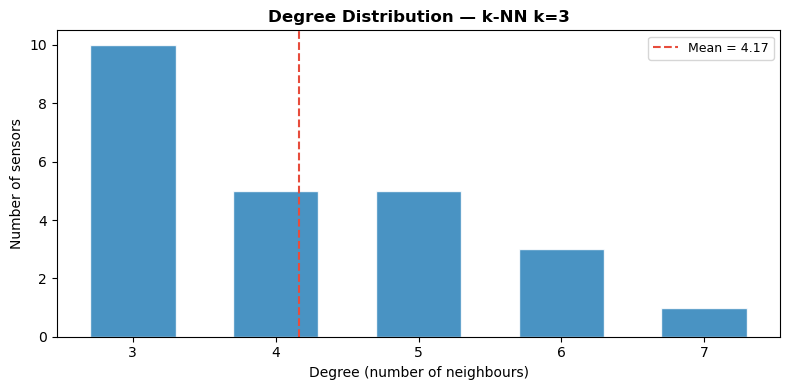

Degree sequence: [3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 5, 5, 5, 5, 5, 6, 6, 6, 7]
Min=3, Max=7, Mean=4.17


In [58]:
def plot_degree_distribution(G, label, color = '#2980b9'):
    degrees = sorted([d for _, d in G.degree()])
    unique, counts = np.unique(degrees, return_counts=True)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(unique, counts, color=color, alpha=0.85, edgecolor='white', width=0.6)
    ax.set_xticks(unique)
    ax.set_xlabel('Degree (number of neighbours)')
    ax.set_ylabel('Number of sensors')
    ax.set_title(f'Degree Distribution — {label}', fontweight='bold')

    # annotate mean
    mean_deg = np.mean(degrees)
    ax.axvline(mean_deg, color='#e74c3c', linestyle='--', linewidth=1.5,
               label=f'Mean = {mean_deg:.2f}')
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

    print("Degree sequence:", degrees)
    print(f"Min={min(degrees)}, Max={max(degrees)}, Mean={mean_deg:.2f}")


plot_degree_distribution(G3, label=f'k-NN k={K_CANONICAL}')

In [59]:
def components_report(G):
    components = sorted(nx.connected_components(G), key=len, reverse=True)
    print(f"Connected components: {len(components)}")
    for idx, comp in enumerate(components):
        names = [G.nodes[n]['name'] for n in sorted(comp)]
        print(f"  Component {idx+1} ({len(comp)} nodes): {names}")


def compare_k_values(sensors, dist, k_values):
    rows = []
    for k in k_values:
        G   = build_knn_graph(sensors, dist, k)
        met = graph_summary(G, f'k-NN k={k}')
        met['k'] = k
        rows.append(met)
    return pd.DataFrame(rows).set_index('k')

K_VALUES = [2, 3, 4, 5]


print(" Component report for k=2")
G2 = build_knn_graph(sensors, dist, k=2)
components_report(G2)

print("\nComponent report for k=3")
components_report(G3)


comparison = compare_k_values(sensors, dist, K_VALUES)
print("\nStructural metrics across k values")
print(comparison.to_string())

 Component report for k=2
Connected components: 1
  Component 1 (24 nodes): ['Plaza de España', 'Escuelas Aguirre', 'Ramón y Cajal', 'Arturo Soria', 'Villaverde', 'Farolillo', 'Casa de Campo', 'Barajas Pueblo', 'Plaza del Carmen', 'Moratalaz', 'Cuatro Caminos', 'Barrio del Pilar', 'Vallecas', 'Méndez Álvaro', 'Castellana', 'Parque del Retiro', 'Plaza Castilla', 'Ensanche de Vallecas', 'Urb. Embajada', 'Plaza Elíptica', 'Sanchinarro', 'El Pardo', 'Juan Carlos I', 'Tres Olivos']

Component report for k=3
Connected components: 1
  Component 1 (24 nodes): ['Plaza de España', 'Escuelas Aguirre', 'Ramón y Cajal', 'Arturo Soria', 'Villaverde', 'Farolillo', 'Casa de Campo', 'Barajas Pueblo', 'Plaza del Carmen', 'Moratalaz', 'Cuatro Caminos', 'Barrio del Pilar', 'Vallecas', 'Méndez Álvaro', 'Castellana', 'Parque del Retiro', 'Plaza Castilla', 'Ensanche de Vallecas', 'Urb. Embajada', 'Plaza Elíptica', 'Sanchinarro', 'El Pardo', 'Juan Carlos I', 'Tres Olivos']
  nodes         : 24
  edges        

sensor_id                 name  betweenness  closeness
 28079016         Arturo Soria       0.3076     0.4107
 28079038       Cuatro Caminos       0.2432     0.4340
 28079004      Plaza de España       0.2230     0.4340
 28079036            Moratalaz       0.2209     0.4182
 28079011        Ramón y Cajal       0.2016     0.4340
 28079050       Plaza Castilla       0.1789     0.3833
 28079008     Escuelas Aguirre       0.1667     0.4510
 28079047        Méndez Álvaro       0.1210     0.3770
 28079035     Plaza del Carmen       0.0844     0.4107
 28079039     Barrio del Pilar       0.0610     0.3382
 28079048           Castellana       0.0551     0.4182
 28079018            Farolillo       0.0504     0.3433
 28079049    Parque del Retiro       0.0316     0.3770
 28079054 Ensanche de Vallecas       0.0132     0.3433
 28079040             Vallecas       0.0132     0.3433
 28079056       Plaza Elíptica       0.0105     0.3239
 28079017           Villaverde       0.0066     0.3194
 28079024 

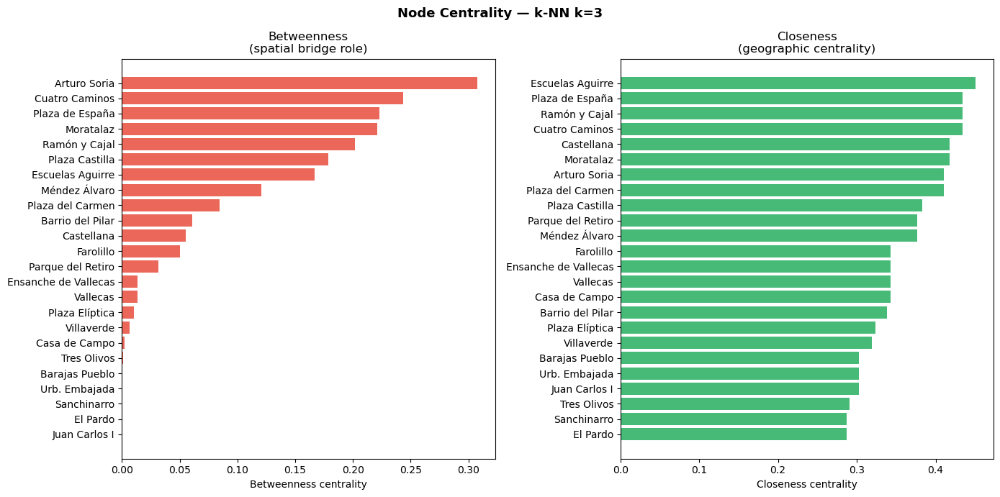

In [60]:
def compute_centralities(G):
    between  = nx.betweenness_centrality(G, normalized=True)
    close    = nx.closeness_centrality(G)
    records  = [
        {
            'sensor_id'  : node,
            'name'       : G.nodes[node]['name'],
            'betweenness': round(between[node], 4),
            'closeness'  : round(close[node],   4),
        }
        for node in G.nodes()
    ]
    return (
        pd.DataFrame(records)
        .sort_values('betweenness', ascending=False)
        .reset_index(drop=True)
    )


def plot_centrality_bars(centrality: pd.DataFrame) -> None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
    fig.suptitle(f'Node Centrality — k-NN k={K_CANONICAL}',
                 fontsize=13, fontweight='bold')

    names = centrality['name'].str.replace('_', ' ')

    ax1.barh(names, centrality['betweenness'], color='#e74c3c', alpha=0.85)
    ax1.set_xlabel('Betweenness centrality')
    ax1.set_title('Betweenness\n(spatial bridge role)')
    ax1.invert_yaxis()

    cent_sorted = centrality.sort_values('closeness', ascending=False)
    ax2.barh(cent_sorted['name'].str.replace('_', ' '),
             cent_sorted['closeness'], color='#27ae60', alpha=0.85)
    ax2.set_xlabel('Closeness centrality')
    ax2.set_title('Closeness\n(geographic centrality)')
    ax2.invert_yaxis()

    plt.tight_layout()
    plt.show()


centrality = compute_centralities(G3)
print(centrality.to_string(index=False))
plot_centrality_bars(centrality)

In [61]:
def detect_communities(G: nx.Graph) -> tuple[list[frozenset], float]:
    communities = list(greedy_modularity_communities(G, weight='weight'))
    Q           = nx.community.modularity(G, communities, weight='weight')
    return communities, Q


def community_report(G: nx.Graph,
                      communities: list[frozenset],
                      Q: float) -> dict:
    print(f"Number of communities : {len(communities)}")
    print(f"Modularity Q          : {Q:.4f}")
    print()
    node_to_comm = {}
    for idx, comm in enumerate(communities):
        names = sorted([G.nodes[n]['name'] for n in comm])
        for n in comm:
            node_to_comm[n] = idx
        print(f"  Community {idx} ({len(comm)} nodes): {names}")
    return node_to_comm


communities, Q = detect_communities(G3)
node_to_comm   = community_report(G3, communities, Q)

Number of communities : 5
Modularity Q          : 0.5110

  Community 0 (8 nodes): ['Barrio del Pilar', 'Castellana', 'Cuatro Caminos', 'El Pardo', 'Plaza Castilla', 'Ramón y Cajal', 'Sanchinarro', 'Tres Olivos']
  Community 1 (6 nodes): ['Casa de Campo', 'Escuelas Aguirre', 'Méndez Álvaro', 'Parque del Retiro', 'Plaza de España', 'Plaza del Carmen']
  Community 2 (4 nodes): ['Arturo Soria', 'Barajas Pueblo', 'Juan Carlos I', 'Urb. Embajada']
  Community 3 (3 nodes): ['Ensanche de Vallecas', 'Moratalaz', 'Vallecas']
  Community 4 (3 nodes): ['Farolillo', 'Plaza Elíptica', 'Villaverde']


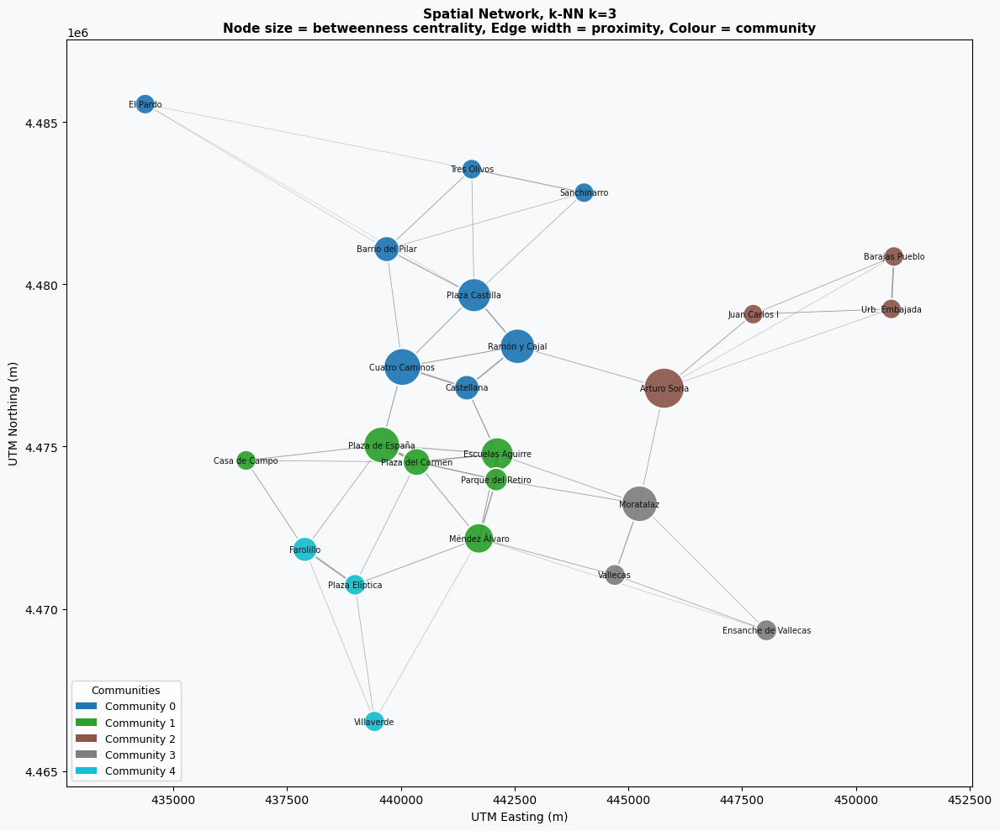

In [62]:
def utm_positions(G):
    return {n: (G.nodes[n]['x'], G.nodes[n]['y']) for n in G.nodes()}


def plot_knn_graph(G, node_to_comm, centrality, k):

    pos         = utm_positions(G)
    n_comm      = len(set(node_to_comm.values()))
    palette     = plt.colormaps.get_cmap('tab10').resampled(n_comm)
    node_colors = [palette(node_to_comm.get(n, 0)) for n in G.nodes()]

    # node size: base + scaled betweenness
    between_map = centrality.set_index('sensor_id')['betweenness'].to_dict()
    node_sizes  = [
        300 + between_map.get(n, 0) * 3000
        for n in G.nodes()
    ]

    # edge width proportional to weight (inverse distance)
    weights    = [G[u][v]['weight'] for u, v in G.edges()]
    max_w      = max(weights)
    edge_widths = [2.5 * w / max_w for w in weights]

    fig, ax = plt.subplots(figsize=(12, 10))
    ax.set_facecolor('#f8f9fa')
    fig.patch.set_facecolor('#f8f9fa')

    nx.draw_networkx_edges(G, pos, ax=ax,
                           width=edge_widths, alpha=0.55,
                           edge_color='#555555')
    nx.draw_networkx_nodes(G, pos, ax=ax,
                           node_color=node_colors,
                           node_size=node_sizes,
                           alpha=0.92, linewidths=1.5,
                           edgecolors='white')
    nx.draw_networkx_labels(G, pos, ax=ax,
                            labels={n: G.nodes[n]['name'] for n in G.nodes()},
                            font_size=7, font_color='#111111')

    # community legend
    handles = [
        mpatches.Patch(facecolor=palette(i), label=f'Community {i}')
        for i in range(n_comm)
    ]
    ax.legend(handles=handles, loc='lower left', fontsize=9,
              title='Communities', title_fontsize=9)

    ax.set_title(f'Spatial Network, k-NN k={k}\n'
                 f'Node size = betweenness centrality, '
                 f'Edge width = proximity, '
                 f'Colour = community',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('UTM Easting (m)')
    ax.set_ylabel('UTM Northing (m)')
    ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
    plt.tight_layout()
    plt.show()


plot_knn_graph(G3, node_to_comm, centrality, k=K_CANONICAL)

In [63]:
def compare_strategies(sensors, dist, k_values, thresholds_km):

    n_max   = len(sensors) * (len(sensors) - 1) // 2
    rows    = []

    for k in k_values:
        G        = build_knn_graph(sensors, dist, k)
        comms, Q = detect_communities(G)
        n_comp   = nx.number_connected_components(G)
        lcc      = G.subgraph(max(nx.connected_components(G), key=len))
        rows.append({
            'strategy'  : f'k-NN k={k}',
            'edges'     : G.number_of_edges(),
            'density_%' : round(G.number_of_edges() / n_max * 100, 1),
            'components': n_comp,
            'avg_degree': round(np.mean([d for _, d in G.degree()]), 2),
            'avg_path'  : round(nx.average_shortest_path_length(lcc), 2),
            'clustering': round(nx.average_clustering(G), 3),
            'communities': len(comms),
            'modularity_Q': round(Q, 3),
        })

    for t_km in thresholds_km:
        t   = t_km * 1000
        G   = build_threshold_graph(sensors, dist, t)
        comms, Q = detect_communities(G)
        n_comp   = nx.number_connected_components(G)
        lcc      = G.subgraph(max(nx.connected_components(G), key=len))
        rows.append({
            'strategy'  : f'Threshold {t_km} km',
            'edges'     : G.number_of_edges(),
            'density_%' : round(G.number_of_edges() / n_max * 100, 1),
            'components': n_comp,
            'avg_degree': round(np.mean([d for _, d in G.degree()]), 2),
            'avg_path'  : round(nx.average_shortest_path_length(lcc), 2),
            'clustering': round(nx.average_clustering(G), 3),
            'communities': len(comms),
            'modularity_Q': round(Q, 3),
        })

    return pd.DataFrame(rows).set_index('strategy')


comparison = compare_strategies(
    sensors, dist,
    k_values=[2, 3, 4, 5],
    thresholds_km=[3.0, 6.0, 10.0, 15.0]
)
print("Strategy Comparison")
print(comparison.to_string())

Strategy Comparison
                   edges  density_%  components  avg_degree  avg_path  clustering  communities  modularity_Q
strategy                                                                                                    
k-NN k=2              32       11.6           1        2.67      4.82       0.368            5         0.593
k-NN k=3              50       18.1           1        4.17      2.83       0.577            5         0.511
k-NN k=4              68       24.6           1        5.67      2.28       0.571            4         0.426
k-NN k=5              84       30.4           1        7.00      2.04       0.627            4         0.357
Threshold 3.0 km      26        9.4          11        2.17      1.69       0.279           12         0.448
Threshold 6.0 km      99       35.9           2        8.25      1.89       0.714            5         0.274
Threshold 10.0 km    196       71.0           1       16.33      1.30       0.856            3         0.174

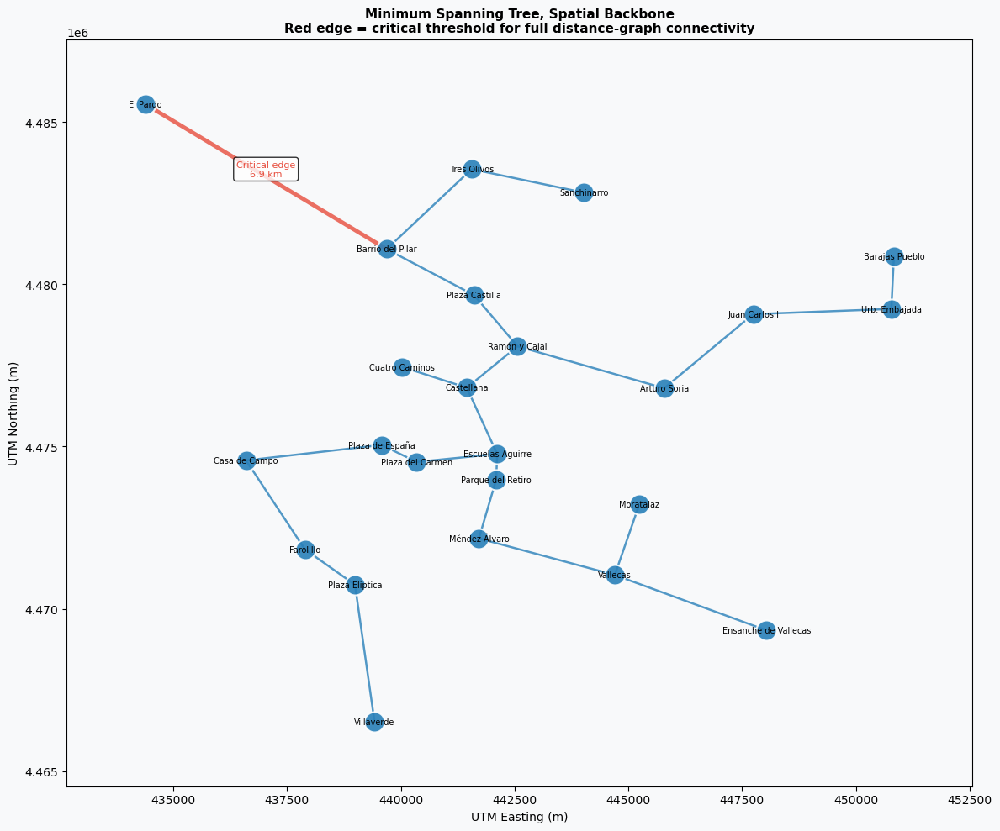

MST edges    : 23  (= n-1 = 23)
Longest edge : Barrio del Pilar ↔ El Pardo  (6.94 km)
Critical threshold for full connectivity: 6937 m


In [64]:
def plot_mst(sensors, dist):
    G_full = build_threshold_graph(sensors, dist, threshold=dist.max() + 1)
    mst    = nx.minimum_spanning_tree(G_full, weight='distance')
    pos    = utm_positions(mst)

    # identify the longest MST edge
    longest = max(mst.edges(data=True), key=lambda e: e[2]['distance'])
    u, v, d = longest

    edge_colors = [
        '#e74c3c' if (a == u and b == v) or (a == v and b == u) else '#2980b9'
        for a, b in mst.edges()
    ]
    edge_widths = [
        3.5 if (a == u and b == v) or (a == v and b == u) else 1.8
        for a, b in mst.edges()
    ]

    fig, ax = plt.subplots(figsize=(12, 10))
    ax.set_facecolor('#f8f9fa')
    fig.patch.set_facecolor('#f8f9fa')

    nx.draw_networkx_edges(mst, pos, ax=ax,
                           edge_color=edge_colors,
                           width=edge_widths, alpha=0.8)
    nx.draw_networkx_nodes(mst, pos, ax=ax,
                           node_color='#2980b9', node_size=300,
                           alpha=0.9, linewidths=1.5, edgecolors='white')
    nx.draw_networkx_labels(mst, pos, ax=ax,
                            labels={n: mst.nodes[n]['name'] for n in mst.nodes()},
                            font_size=7)

    # annotate longest edge
    mx = (pos[u][0] + pos[v][0]) / 2
    my = (pos[u][1] + pos[v][1]) / 2
    ax.annotate(f"Critical edge\n{d['distance']/1000:.1f} km",
                xy=(mx, my), fontsize=8, color='#e74c3c',
                ha='center',
                bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8))

    ax.set_title('Minimum Spanning Tree, Spatial Backbone\n'
                 'Red edge = critical threshold for full distance-graph connectivity',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('UTM Easting (m)')
    ax.set_ylabel('UTM Northing (m)')
    ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
    plt.tight_layout()
    plt.show()

    print(f"MST edges    : {mst.number_of_edges()}  (= n-1 = {len(sensors)-1})")
    print(f"Longest edge : {mst.nodes[u]['name']} ↔ {mst.nodes[v]['name']}  "
          f"({d['distance']/1000:.2f} km)")
    print(f"Critical threshold for full connectivity: {d['distance']:.0f} m")


plot_mst(sensors, dist)

In [65]:
print(f"  Sensors          : {len(sensors)}")
print(f"  Canonical graph  : k-NN k={K_CANONICAL}")
print(f"  Edges            : {G3.number_of_edges()}")
print(f"  Communities (Q)  : {len(communities)} (Q={Q:.3f})")
print(f"  MST critical thr : {mst_thresh/1000:.1f} km")

  Sensors          : 24
  Canonical graph  : k-NN k=3
  Edges            : 50
  Communities (Q)  : 5 (Q=0.511)
  MST critical thr : 6.9 km


### Interpretation of Results

The analysis reveals that the sensor grid is geographically well-structured and exhibits a meaningful community organisation. Full network connectivity is achieved at a pairwise distance of approximately 7 km, a figure that corresponds closely to the inter-district spacing of the city's major urban zones and confirms that the monitoring network was not deployed at random but reflects an intentional spatial logic.

At the chosen k-NN parameterisation (k = 3), the graph has 50 edges, with node degrees ranging from 3 to 7 and an average of 4.17. The local clustering coefficient of 0.58 indicates a high degree of triadic closure: if sensor A is connected to sensor B and B to sensor C, it is likely that A and C are also connected, which is consistent with the layout of the monitoring infrastructure. The greedy modularity algorithm identifies five geographic communities (modularity Q = 0.51), a value considered strong in network science and indicative of genuine structural partitioning rather than noise. These communities broadly align with recognised urban geographies: the city centre, the north-western residential belt, the southern industrial corridor, the eastern districts, and the peripheral suburban ring.

From an interpretive standpoint, the sensors with the highest betweenness centrality are the most informationally critical nodes in the network. Their readings are most representative of city-wide trends rather than local micro-environments, and their removal would fragment the network most severely. The community structure identified here will serve as a principled spatial grouping variable in subsequent analyses, providing a geographically meaningful basis for aggregating and comparing pollution signals across different parts of the city.


# 6. Correlation network

Goal: Capture relationships between sensors based on pollutant time series.


### Introduction and Pipeline

Whereas the previous section connected sensors on the basis of their physical location, this section constructs a network founded on a different notion of proximity: the statistical similarity of sensors' long-run pollution signals. Two stations are considered related not because they are geographically close but because their NO₂ time series co-vary systematically over time. This approach captures the behavioural structure of the monitoring network independently of its spatial layout.

The pipeline begins by aggregating hourly NO2 measurements to monthly medians for each sensor, producing a matrix of 288 monthly observations across 24 sensors (covering January 2001 through December 2024). Only non-interpolated measurements are retained at this stage to ensure that the correlations reflect genuine atmospheric signal rather than artefacts of the dataset's imputation procedure. A symmetric Pearson correlation matrix is then computed over all 552 off-diagonal sensor pairs, using a minimum of 12 overlapping months as the threshold for a valid correlation estimate.

Because the density and connectivity of the resulting network depend critically on the correlation threshold chosen to define an edge, a sensitivity analysis is conducted by sweeping threshold values from r = 0.30 to r = 1.00 and recording, at each value, the number of edges, the number of connected components, and the number of isolated nodes. This curve is used to select a working threshold of r ≥ 0.90, which produces a network that is neither trivially dense (every sensor connected to every other) nor overly sparse (most sensors disconnected). On the resulting graph, the same centrality metrics and community detection algorithm applied in the spatial analysis are computed again, enabling a direct structural comparison between the geographic and behavioural network representations.


In [66]:
def build_sensor_monthly_pivot(df, variable='NO2', min_months=12):
    mask = (df['magnitude_name'] == variable) & (~df['is_interpolated'])
    sub  = df.loc[mask, ['sensor_id', 'entry_date', 'value']].copy()

    if sub.empty:
        raise ValueError(f"No real measurements found for variable '{variable}'.")

    sub['year_month'] = sub['entry_date'].dt.to_period('M')

    monthly = (
        sub.groupby(['year_month', 'sensor_id'], observed=True)['value']
           .median()                         # monthly median per sensor
           .reset_index()
    )

    pivot = (
        monthly
        .pivot(index='year_month', columns='sensor_id', values='value')
        .sort_index()
    )

    # Keep only sensors with enough observations
    pivot = pivot.loc[:, pivot.notna().sum() >= min_months]

    print(f"Variable       : {variable}")
    print(f"Pivot shape    : {pivot.shape}  (months × sensors)")
    print(f"Date range     : {pivot.index.min()} → {pivot.index.max()}")
    print(f"Sensors kept   : {pivot.shape[1]}  (≥ {min_months} non-null months)")
    print(f"Mean fill rate : {pivot.notna().mean().mean():.1%}")
    return pivot


def compute_sensor_correlations(pivot, min_periods=12):
    corr = pivot.corr(method='pearson', min_periods=min_periods)
    return corr


CORR_VAR = 'NO2'
pivot    = build_sensor_monthly_pivot(df, variable=CORR_VAR, min_months=12)
corr     = compute_sensor_correlations(pivot)

n    = len(corr)
mask = ~np.eye(n, dtype=bool)
vals = corr.values[mask]
vals = vals[~np.isnan(vals)]

print(f"\nCorrelation matrix shape  : {corr.shape}")
print(f"Off-diagonal pairs        : {len(vals)}")
print(f"Mean correlation          : {vals.mean():.3f}")
print(f"Median correlation        : {np.median(vals):.3f}")
print(f"Min / Max                 : {vals.min():.3f} / {vals.max():.3f}")
print(f"Pairs with r ≥ 0.70       : {(vals >= 0.70).sum()}  ({(vals >= 0.70).mean():.1%})")
print(f"Pairs with r ≥ 0.90       : {(vals >= 0.90).sum()}  ({(vals >= 0.90).mean():.1%})")

Variable       : NO2
Pivot shape    : (288, 24)  (months × sensors)
Date range     : 2001-01 → 2024-12
Sensors kept   : 24  (≥ 12 non-null months)
Mean fill rate : 81.3%

Correlation matrix shape  : (24, 24)
Off-diagonal pairs        : 552
Mean correlation          : 0.866
Median correlation        : 0.875
Min / Max                 : 0.665 / 0.968
Pairs with r ≥ 0.70       : 544  (98.6%)
Pairs with r ≥ 0.90       : 188  (34.1%)


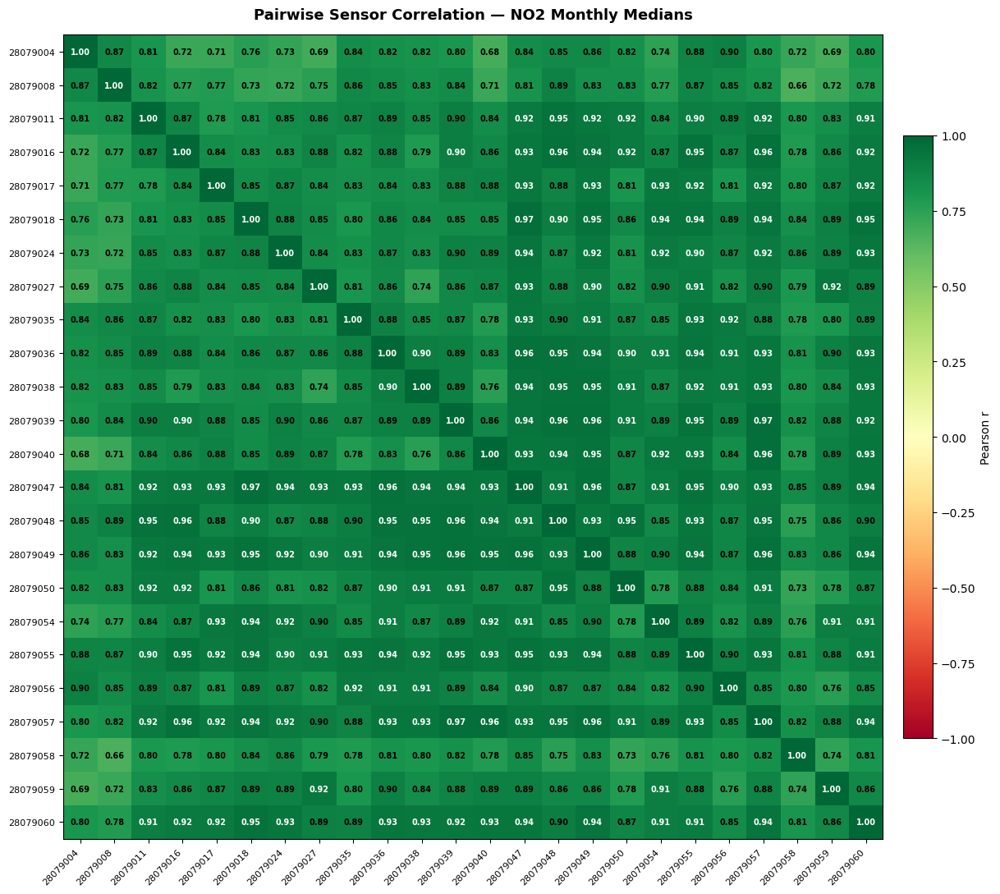

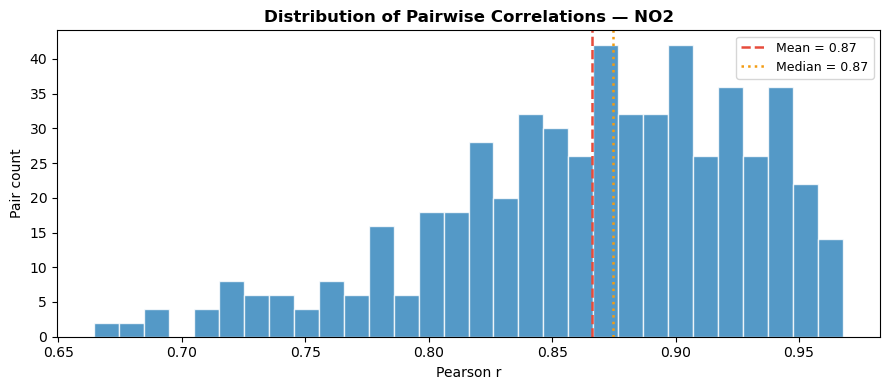

In [67]:
def plot_correlation_heatmap(corr, sensors_df, variable='NO2'):
    id_to_name = sensors_df.set_index('sensor_id')['sensor_name'].to_dict()
    labels     = [id_to_name.get(int(sid), str(sid)) for sid in corr.index]

    fig, ax = plt.subplots(figsize=(13, 11))

    im = ax.imshow(corr.values, cmap='RdYlGn', vmin=-1, vmax=1, aspect='auto')
    cbar = plt.colorbar(im, ax=ax, shrink=0.75, pad=0.02)
    cbar.set_label('Pearson r', fontsize=10)

    n = len(labels)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
    ax.set_yticklabels(labels, fontsize=8)

    # Annotate each cell
    for i in range(n):
        for j in range(n):
            val = corr.values[i, j]
            if not np.isnan(val):
                txt_color = 'white' if abs(val) > 0.9 else 'black'
                ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                        fontsize=7, color=txt_color, fontweight='bold')

    ax.set_title(
        f'Pairwise Sensor Correlation — {variable} Monthly Medians',
        fontsize=13, fontweight='bold', pad=14
    )
    plt.tight_layout()
    plt.show()


def plot_correlation_distribution(corr, variable='NO2'):
    n    = len(corr)
    mask = ~np.eye(n, dtype=bool)
    vals = corr.values[mask]
    vals = vals[~np.isnan(vals)]

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(vals, bins=30, color='#2980b9', alpha=0.80, edgecolor='white')
    ax.axvline(vals.mean(), color='#e74c3c', linestyle='--', linewidth=1.8,
               label=f'Mean = {vals.mean():.2f}')
    ax.axvline(np.median(vals), color='#f39c12', linestyle=':', linewidth=1.8,
               label=f'Median = {np.median(vals):.2f}')
    ax.set_xlabel('Pearson r')
    ax.set_ylabel('Pair count')
    ax.set_title(f'Distribution of Pairwise Correlations — {variable}',
                 fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()


plot_correlation_heatmap(corr, sensors, variable=CORR_VAR)
plot_correlation_distribution(corr, variable=CORR_VAR)

In [68]:
def build_correlation_graph(sensors_df, corr, threshold):
    sensor_lookup = {
        int(sid): row
        for sid, row in sensors_df.set_index('sensor_id').iterrows()
    }
    G = nx.Graph()

    for sid in corr.index:
        key = int(sid)
        if key in sensor_lookup:
            row = sensor_lookup[key]
            G.add_node(key,
                       name=str(row['sensor_name']),
                       x=float(row['utm_x']),
                       y=float(row['utm_y']))

    ids = list(corr.index)
    for i in range(len(ids)):
        for j in range(i + 1, len(ids)):
            r = corr.iloc[i, j]
            u, v = int(ids[i]), int(ids[j])
            if not np.isnan(r) and r >= threshold and G.has_node(u) and G.has_node(v):
                G.add_edge(u, v, correlation=float(r), weight=float(r))
    return G


def correlation_threshold_curve(sensors_df, corr, thresholds):
    n_nodes = len(corr)
    n_max   = n_nodes * (n_nodes - 1) // 2
    records = []
    for t in thresholds:
        G = build_correlation_graph(sensors_df, corr, threshold=t)
        n_comp = nx.number_connected_components(G) if G.number_of_nodes() > 0 else 0
        records.append({
            'threshold'   : round(t, 2),
            'n_edges'     : G.number_of_edges(),
            'edge_pct'    : round(G.number_of_edges() / n_max * 100, 1) if n_max > 0 else 0,
            'n_components': n_comp,
            'isolated'    : sum(1 for n in G.nodes() if G.degree(n) == 0),
        })
    return pd.DataFrame(records)


THRESHOLDS = [round(t, 2) for t in np.arange(0.30, 1.01, 0.05)]

curve_corr = correlation_threshold_curve(sensors, corr, THRESHOLDS)
print("Threshold sweep (Pearson r):")
print(curve_corr.to_string(index=False))

Threshold sweep (Pearson r):
 threshold  n_edges  edge_pct  n_components  isolated
      0.30      276     100.0             1         0
      0.35      276     100.0             1         0
      0.40      276     100.0             1         0
      0.45      276     100.0             1         0
      0.50      276     100.0             1         0
      0.55      276     100.0             1         0
      0.60      276     100.0             1         0
      0.65      276     100.0             1         0
      0.70      272      98.6             1         0
      0.75      260      94.2             1         0
      0.80      238      86.2             1         0
      0.85      176      63.8             1         0
      0.90       94      34.1             4         3
      0.95       14       5.1            14        13
      1.00        0       0.0            24        24


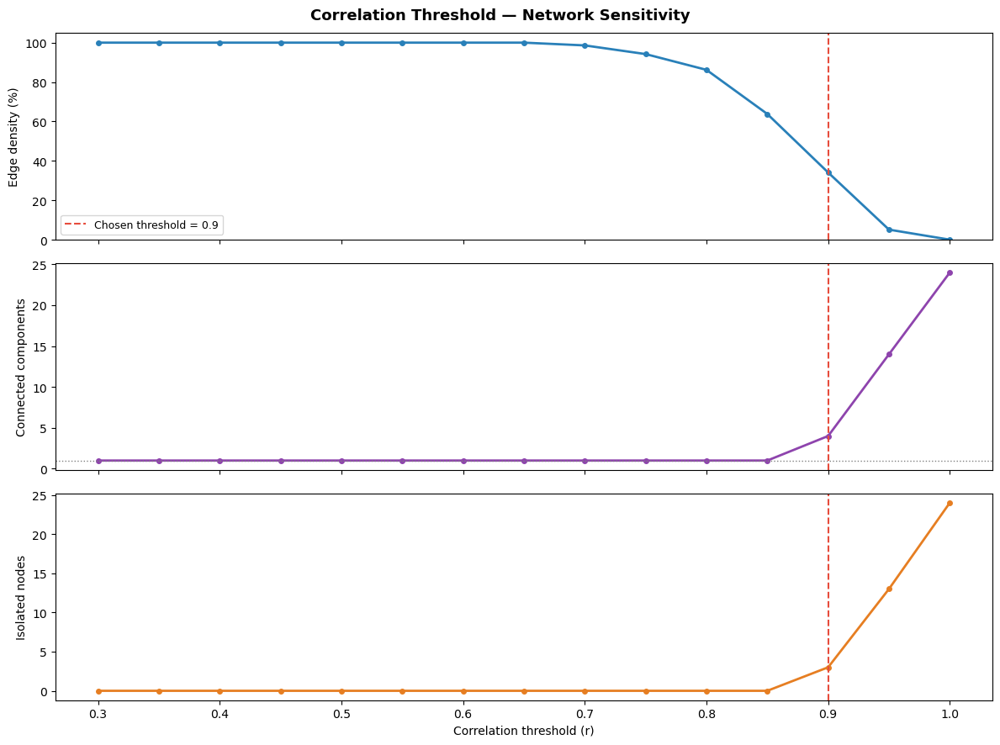


Canonical correlation graph  (r ≥ 0.9):
Nodes: 24
Edges: 94
Connected components: 4
Isolated nodes: 3


In [69]:
def plot_correlation_threshold_curve(curve, chosen_threshold):
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    fig.suptitle('Correlation Threshold — Network Sensitivity',
                 fontsize=13, fontweight='bold')

    x = curve['threshold']

    # Edge density
    axes[0].plot(x, curve['edge_pct'], color='#2980b9', linewidth=2, marker='o', markersize=4)
    axes[0].axvline(chosen_threshold, color='#e74c3c', linestyle='--', linewidth=1.5,
                    label=f'Chosen threshold = {chosen_threshold}')
    axes[0].set_ylabel('Edge density (%)')
    axes[0].set_ylim(0, 105)
    axes[0].legend(fontsize=9)

    # Connected components
    axes[1].plot(x, curve['n_components'], color='#8e44ad', linewidth=2, marker='o', markersize=4)
    axes[1].axvline(chosen_threshold, color='#e74c3c', linestyle='--', linewidth=1.5)
    axes[1].axhline(1, color='grey', linestyle=':', linewidth=1)
    axes[1].set_ylabel('Connected components')

    # Isolated nodes
    axes[2].plot(x, curve['isolated'], color='#e67e22', linewidth=2, marker='o', markersize=4)
    axes[2].axvline(chosen_threshold, color='#e74c3c', linestyle='--', linewidth=1.5)
    axes[2].set_ylabel('Isolated nodes')
    axes[2].set_xlabel('Correlation threshold (r)')

    plt.tight_layout()
    plt.show()


CORR_THRESHOLD = 0.90    # strong positive correlation required
plot_correlation_threshold_curve(curve_corr, CORR_THRESHOLD)

G_corr = build_correlation_graph(sensors, corr, threshold=CORR_THRESHOLD)

print(f"\nCanonical correlation graph  (r ≥ {CORR_THRESHOLD}):")
print(f"Nodes: {G_corr.number_of_nodes()}")
print(f"Edges: {G_corr.number_of_edges()}")
print(f"Connected components: {nx.number_connected_components(G_corr)}")
print(f"Isolated nodes: {sum(1 for n in G_corr.nodes() if G_corr.degree(n)==0)}")

 Correlation graph (r ≥ 0.9)
  nodes         : 24
  edges         : 94
  density       : 0.341
  components    : 4
  avg_degree    : 7.83
  max_degree    : 18
  clustering    : 0.515
  avg_path      : N/A


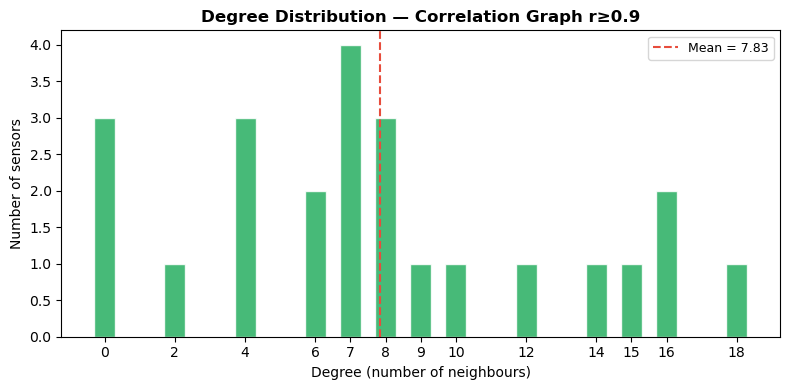

Degree sequence: [0, 0, 0, 2, 4, 4, 4, 6, 6, 7, 7, 7, 7, 8, 8, 8, 9, 10, 12, 14, 15, 16, 16, 18]
Min=0, Max=18, Mean=7.83

Structural metrics across correlation thresholds:
           edges  density_%  components  avg_degree  clustering  communities  modularity_Q
threshold                                                                                 
0.5          276      100.0           1       23.00       0.894            1        -0.000
0.6          276      100.0           1       23.00       0.894            1        -0.000
0.7          272       98.6           1       22.67       0.885            1        -0.000
0.8          238       86.2           1       19.83       0.835            2         0.039
0.9           94       34.1           4        7.83       0.515            6         0.119


In [70]:
def corr_graph_summary(G, label=''):
    if G.number_of_nodes() == 0:
        print(f"[{label}] Empty graph.")
        return {}
    degrees  = [d for _, d in G.degree()]
    n_comp   = nx.number_connected_components(G)
    lcc      = G.subgraph(max(nx.connected_components(G), key=len))
    metrics = {
        'label'      : label,
        'nodes'      : G.number_of_nodes(),
        'edges'      : G.number_of_edges(),
        'density'    : round(nx.density(G), 3),
        'components' : n_comp,
        'avg_degree' : round(np.mean(degrees), 2),
        'max_degree' : int(np.max(degrees)),
        'clustering' : round(nx.average_clustering(G, weight='weight'), 3),
        'avg_path'   : round(nx.average_shortest_path_length(lcc), 3)
                       if n_comp == 1 else 'N/A',
    }
    for k, v in metrics.items():
        if k != 'label':
            print(f"  {k:<14s}: {v}")
    return metrics

print(f" Correlation graph (r ≥ {CORR_THRESHOLD})")
_ = corr_graph_summary(G_corr, label=f'Corr r≥{CORR_THRESHOLD}')

plot_degree_distribution(G_corr, label=f'Correlation Graph r≥{CORR_THRESHOLD}', color='#27ae60')

thresholds_report = [0.50, 0.60, 0.70, 0.80, 0.90]
rows = []
for t in thresholds_report:
    G_t = build_correlation_graph(sensors, corr, threshold=t)
    d   = [deg for _, deg in G_t.degree()]
    n_comp = nx.number_connected_components(G_t) if G_t.number_of_nodes() > 0 else 0
    lcc = G_t.subgraph(max(nx.connected_components(G_t), key=len)) if G_t.number_of_nodes() > 0 else G_t
    comms_t, Q_t = detect_communities(G_t) if G_t.number_of_edges() > 0 else ([], 0)
    rows.append({
        'threshold'    : t,
        'edges'        : G_t.number_of_edges(),
        'density_%'    : round(nx.density(G_t) * 100, 1),
        'components'   : n_comp,
        'avg_degree'   : round(np.mean(d), 2) if d else 0,
        'clustering'   : round(nx.average_clustering(G_t, weight='weight'), 3),
        'communities'  : len(comms_t),
        'modularity_Q' : round(Q_t, 3),
    })

df_thresh = pd.DataFrame(rows).set_index('threshold')
print("\nStructural metrics across correlation thresholds:")
print(df_thresh.to_string())

In [71]:
if G_corr.number_of_edges() == 0:
    print(f"No edges at threshold r ≥ {CORR_THRESHOLD}. "
          "Each sensor forms its own community.")
    comm_corr       = [frozenset({n}) for n in G_corr.nodes()]
    Q_corr          = 0.0
    id_to_comm_corr = {n: i for i, n in enumerate(G_corr.nodes())}
else:
    comm_corr, Q_corr = detect_communities(G_corr)
    id_to_comm_corr = {n: idx for idx, comm in enumerate(comm_corr) for n in comm}
    fallback = len(comm_corr)
    for n in G_corr.nodes():
        if n not in id_to_comm_corr:
            id_to_comm_corr[n] = fallback

print(f"Correlation graph — community structure (r ≥ {CORR_THRESHOLD}):")
print(f"Communities: {len(comm_corr)}")
print(f"Modularity Q: {Q_corr:.4f}")
for idx, comm in enumerate(comm_corr):
    names = sorted([G_corr.nodes[n].get('name', str(n)) for n in comm])
    print(f"Community {idx} ({len(comm)} nodes): {names}")

Correlation graph — community structure (r ≥ 0.9):
Communities: 6
Modularity Q: 0.1192
Community 0 (10 nodes): ['Barajas Pueblo', 'Casa de Campo', 'Ensanche de Vallecas', 'Farolillo', 'Juan Carlos I', 'Parque del Retiro', 'Tres Olivos', 'Urb. Embajada', 'Vallecas', 'Villaverde']
Community 1 (6 nodes): ['Arturo Soria', 'Barrio del Pilar', 'Castellana', 'Plaza Castilla', 'Ramón y Cajal', 'Sanchinarro']
Community 2 (5 nodes): ['Cuatro Caminos', 'Moratalaz', 'Méndez Álvaro', 'Plaza Elíptica', 'Plaza del Carmen']
Community 3 (1 nodes): ['Plaza de España']
Community 4 (1 nodes): ['Escuelas Aguirre']
Community 5 (1 nodes): ['El Pardo']


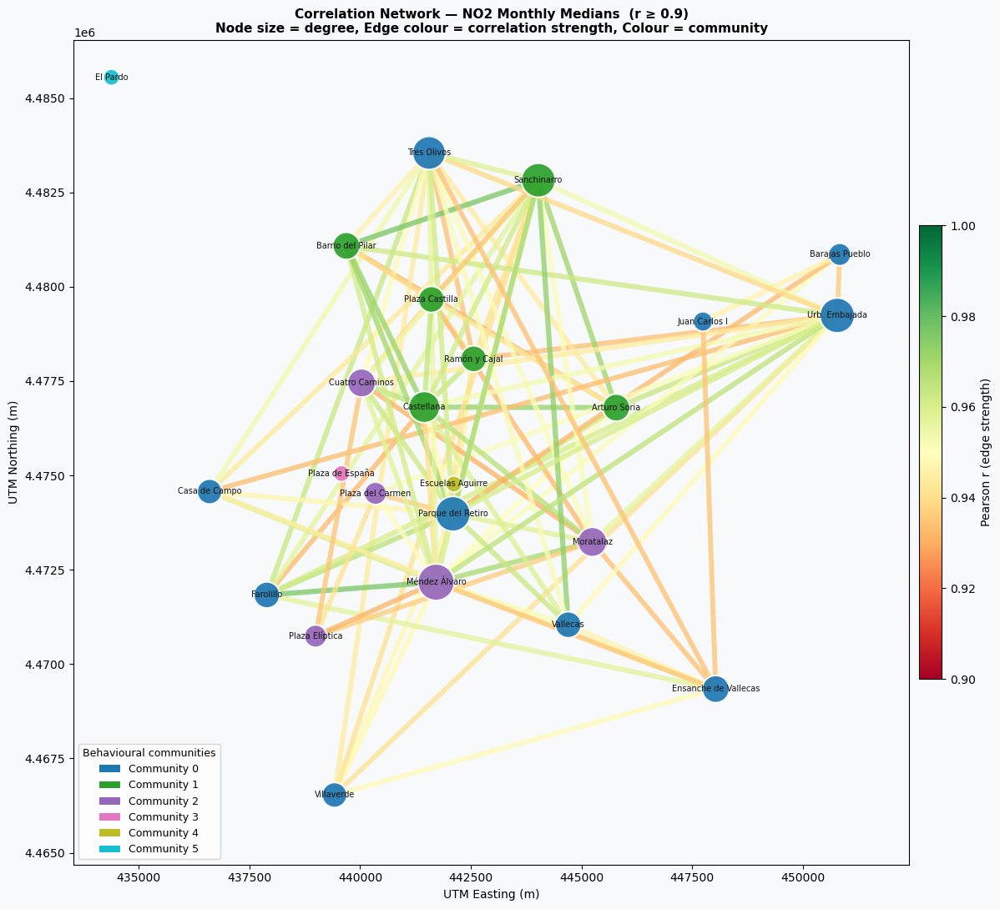

In [72]:
def plot_correlation_graph(G, node_to_comm, corr, threshold, sensors_df):
    if G.number_of_nodes() == 0:
        print("Empty graph — nothing to plot.")
        return

    pos        = utm_positions(G)
    n_comm     = len(set(node_to_comm.values()))
    palette    = plt.colormaps.get_cmap('tab10').resampled(max(n_comm, 1))
    node_colors = [palette(node_to_comm.get(n, 0)) for n in G.nodes()]

    degrees    = dict(G.degree())
    max_deg    = max(degrees.values()) if degrees else 1
    node_sizes = [200 + 800 * degrees[n] / max_deg for n in G.nodes()]

    edge_weights = [G[u][v]['weight'] for u, v in G.edges()]
    max_w        = max(edge_weights) if edge_weights else 1.0
    edge_widths  = [0.5 + 4.0 * w / max_w for w in edge_weights]
    # Colour edges by strength: weak=grey, strong=green
    edge_colors  = [
        plt.cm.RdYlGn(0.3 + 0.7 * (w - threshold) / (1.0 - threshold))
        for w in edge_weights
    ]

    fig, ax = plt.subplots(figsize=(13, 11))
    ax.set_facecolor('#f8f9fa')
    fig.patch.set_facecolor('#f8f9fa')

    nx.draw_networkx_edges(G, pos, ax=ax,
                           width=edge_widths,
                           edge_color=edge_colors,
                           alpha=0.75)
    nx.draw_networkx_nodes(G, pos, ax=ax,
                           node_color=node_colors,
                           node_size=node_sizes,
                           alpha=0.92,
                           linewidths=1.5,
                           edgecolors='white')
    nx.draw_networkx_labels(G, pos, ax=ax,
                            labels={n: G.nodes[n]['name'] for n in G.nodes()},
                            font_size=7, font_color='#111111')

    comm_handles = [
        mpatches.Patch(facecolor=palette(i), label=f'Community {i}')
        for i in range(n_comm)
    ]
    ax.legend(handles=comm_handles, loc='lower left', fontsize=9,
              title='Behavioural communities', title_fontsize=9)


    sm = cm.ScalarMappable(cmap='RdYlGn',
                           norm=mcolors.Normalize(vmin=threshold, vmax=1.0))
    sm.set_array([])
    plt.colorbar(sm, ax=ax, shrink=0.55, pad=0.01, label='Pearson r (edge strength)')

    ax.set_title(
        f'Correlation Network — {CORR_VAR} Monthly Medians  (r ≥ {threshold})\n'
        f'Node size = degree, Edge colour = correlation strength, Colour = community',
        fontsize=11, fontweight='bold'
    )
    ax.set_xlabel('UTM Easting (m)')
    ax.set_ylabel('UTM Northing (m)')
    ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
    plt.tight_layout()
    plt.show()


plot_correlation_graph(G_corr, id_to_comm_corr, corr, CORR_THRESHOLD, sensors)

In [73]:
def compare_spatial_vs_correlation(G_spatial, G_corr,
                                   label_s='Spatial k-NN (k=3)',
                                   label_c='Correlation (r≥0.90)'):
    def row(G, label):
        if G.number_of_nodes() == 0:
            return {'label': label}
        degrees = [d for _, d in G.degree()]
        n_comp  = nx.number_connected_components(G)
        lcc     = G.subgraph(max(nx.connected_components(G), key=len))
        comms_g, Q_g = detect_communities(G) if G.number_of_edges() > 0 else ([], 0)
        return {
            'label'       : label,
            'nodes'       : G.number_of_nodes(),
            'edges'       : G.number_of_edges(),
            'density'     : round(nx.density(G), 3),
            'components'  : n_comp,
            'avg_degree'  : round(np.mean(degrees), 2),
            'max_degree'  : int(np.max(degrees)),
            'clustering'  : round(nx.average_clustering(G, weight=None), 3),
            'avg_path'    : round(nx.average_shortest_path_length(lcc), 3) if n_comp == 1 else 'N/A',
            'communities' : len(comms_g),
            'modularity_Q': round(Q_g, 3),
        }

    df_cmp = pd.DataFrame([row(G_spatial, label_s), row(G_corr, label_c)]).set_index('label')
    print("Structural comparison: Spatial vs Correlation network")
    print(df_cmp.to_string())
    return df_cmp


df_comparison = compare_spatial_vs_correlation(
    G3, G_corr,
    label_s=f'Spatial k-NN (k={K_CANONICAL})',
    label_c=f'Correlation (r≥{CORR_THRESHOLD})'
)

Structural comparison: Spatial vs Correlation network
                     nodes  edges  density  components  avg_degree  max_degree  clustering avg_path  communities  modularity_Q
label                                                                                                                         
Spatial k-NN (k=3)      24     50    0.181           1        4.17           7       0.577    2.826            5         0.511
Correlation (r≥0.9)     24     94    0.341           4        7.83          18       0.535      N/A            6         0.119


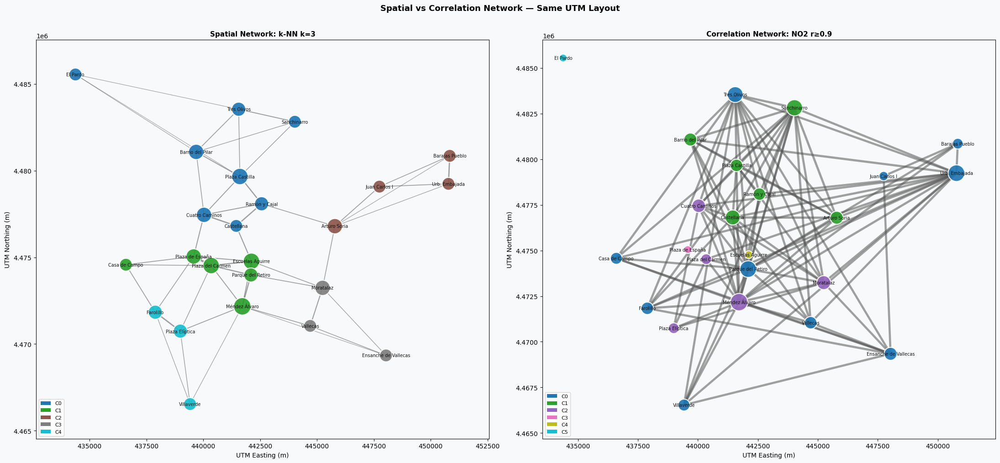

In [74]:
def plot_side_by_side(G_spatial, comm_spatial, G_corr, comm_corr_map, sensors_df):
    fig, axes = plt.subplots(1, 2, figsize=(22, 10))
    fig.patch.set_facecolor('#f8f9fa')

    def draw_graph(ax, G, comm_map, title, edge_key, cmap_name='tab10'):
        if G.number_of_nodes() == 0:
            ax.set_title(title)
            ax.text(0.5, 0.5, 'No nodes', transform=ax.transAxes, ha='center')
            return

        pos     = utm_positions(G)
        n_comm  = len(set(comm_map.values()))
        palette = plt.colormaps.get_cmap(cmap_name).resampled(max(n_comm, 1))

        node_colors = [palette(comm_map.get(n, 0)) for n in G.nodes()]
        degrees     = dict(G.degree())
        max_deg     = max(degrees.values()) if degrees else 1
        node_sizes  = [150 + 600 * degrees[n] / max_deg for n in G.nodes()]

        edge_attrs = [G[u][v].get(edge_key, 1.0) for u, v in G.edges()]
        max_attr   = max(edge_attrs) if edge_attrs else 1.0
        edge_widths = [0.5 + 3.0 * a / max_attr for a in edge_attrs]

        ax.set_facecolor('#f8f9fa')
        nx.draw_networkx_edges(G, pos, ax=ax, width=edge_widths,
                               alpha=0.55, edge_color='#555555')
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors,
                               node_size=node_sizes, alpha=0.92,
                               linewidths=1.5, edgecolors='white')
        nx.draw_networkx_labels(G, pos, ax=ax,
                                labels={n: G.nodes[n]['name'] for n in G.nodes()},
                                font_size=7, font_color='#111111')
        handles = [
            mpatches.Patch(facecolor=palette(i), label=f'C{i}')
            for i in range(n_comm)
        ]
        ax.legend(handles=handles, loc='lower left', fontsize=8)
        ax.set_title(title, fontsize=11, fontweight='bold')
        ax.set_xlabel('UTM Easting (m)')
        ax.set_ylabel('UTM Northing (m)')
        ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)

    draw_graph(axes[0], G3, node_to_comm,
               f'Spatial Network: k-NN k={K_CANONICAL}',
               edge_key='weight')
    draw_graph(axes[1], G_corr, id_to_comm_corr,
               f'Correlation Network: {CORR_VAR} r≥{CORR_THRESHOLD}',
               edge_key='correlation')

    plt.suptitle('Spatial vs Correlation Network — Same UTM Layout',
                 fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()


plot_side_by_side(G3, node_to_comm, G_corr, id_to_comm_corr, sensors)

### Interpretation of Results

The most striking finding from the correlation analysis is the exceptional degree of synchrony among NO2 sensors. The median pairwise correlation across all 552 sensor pairs is 0.875, with 98.6 % of pairs exceeding r = 0.70. This degree of co-movement is higher than one might expect in a geographically extended urban area and reflects the dominant role of city-wide atmospheric dynamics in determining the overall level of NO2 at any given point in the city.

At the selected threshold of r ≥ 0.90, the network comprises 94 edges across 24 nodes, with node degrees ranging from 0 to 18 and an average of 7.83. Three sensors become isolated at this threshold, indicating that their NO2 signals diverge meaningfully from the city-wide pattern, a likely signature of atypical micro-environments such as proximity to a major highway interchange, an industrial facility, or a large green space. The greedy modularity algorithm identifies six behavioural communities at this threshold, with a modularity of Q = 0.12, considerably lower than the Q = 0.51 obtained in the spatial network. This lower value reflects the fact that behavioural boundaries in the city are more diffuse than geographic ones: pollution dynamics driven by meteorology and traffic do not respect administrative district borders as much as the sensor grid does.

A direct comparison between the two network representations reveals an important asymmetry. Several sensor pairs that are geographically distant but share similar exposure profiles come together in the correlation network while stay disconnected in the spatial graph. Conversely, some geographically adjacent sensors fall into different behavioural communities because one is sheltered in a park while the other faces a major road. This divergence between spatial and behavioural proximity is itself a substantive finding: it implies that the city's pollution landscape cannot be fully understood from geography alone, and that functional clustering based on time-series similarity provides complementary and non-redundant information about the structure of urban air quality.


# 7. Parallel computation of correlations


### Introduction and Pipeline

Computing hourly cross-correlations between all pollutant and meteorological variables, for each of the 24 sensors and across 24 years of data, produces a computational workload that is non-trivial in scale: 576 individual correlation matrices, each covering up to 28 variables, must be estimated from time series of up to 8,760 hourly observations per year. This section addresses it through parallel computing, distributing the annual computation tasks across multiple CPU cores using Python's `multiprocessing` module, and then analyses the resulting matrices to characterise the most consistent inter-variable relationships in the dataset.

The pipeline is structured in three phases. In the first phase, the full dataset is partitioned into 24 annual Parquet files, one per calendar year, occupying a total of 332.3 MB on disk, with individual files ranging from 1.6 MB (early years with sparse sensor coverage) to 35.8 MB (recent years with full network deployment). In the second phase, a worker function (`process_year`) is defined that, given a year identifier, loads the corresponding Parquet slice, groups the data by sensor, constructs a pivot table of hourly observations across all available variables for that sensor–year pair, and computes the Pearson correlation matrix with a minimum of 24 overlapping hourly observations required per variable pair. Each resulting matrix is saved as a compressed NumPy archive (`.npz`, float32 precision) to disk. This function is first executed sequentially, iterating over all 24 years in a single process, and then executed in parallel using a `multiprocessing.Pool` of 8 workers. 
In the third phase, all saved matrices are reloaded and merged into a long-format table of (year, sensor, variable_a, variable_b, r) records, which is analysed to identify the strongest and most temporally stable inter-variable relationships across the full observation period.


In [75]:
# Output directories
TASK8_ROOT = Path('./task8')
DATA_DIR = TASK8_ROOT / 'data'
SEQ_OUT_DIR = TASK8_ROOT / 'seq_results'
PAR_OUT_DIR = TASK8_ROOT / 'par_results'

for d in [DATA_DIR, SEQ_OUT_DIR, PAR_OUT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Save year-partitioned parquet
def save_year_partitions(df, data_dir):
    keep_cols = ['sensor_id', 'magnitude_name', 'entry_date', 'value']
    years     = sorted(df['entry_date'].dt.year.unique())

    saved, skipped = 0, 0
    for year in years:
        path = data_dir / f'year_{year}.parquet'
        if path.exists():
            skipped += 1
            continue
        sub = df.loc[df['entry_date'].dt.year == year, keep_cols]
        sub.to_parquet(path, index=False)
        saved += 1

    files  = sorted(data_dir.glob('year_*.parquet'))
    total  = sum(f.stat().st_size for f in files) / 1e6
    sizes  = {int(f.stem.split('_')[1]): f.stat().st_size / 1e6 for f in files}
    print(f'Partition files: {len(files)}  ({saved} new, {skipped} cached)')
    print(f'Total size: {total:.1f} MB')
    print(f'Per-year range: {min(sizes.values()):.1f} – {max(sizes.values()):.1f} MB')
    return sorted(sizes.keys())

print('Saving year partitions…')
t0    = time.perf_counter()
YEARS = save_year_partitions(df, DATA_DIR)
print(f'Done in {time.perf_counter() - t0:.1f} s')
n_sensors = df['sensor_id'].nunique()
print(f'Years: {YEARS[0]} – {YEARS[-1]}  ({len(YEARS)} total)')
print(f'Sensors: {n_sensors}')
print(f'(year, sensor) pairs: {len(YEARS) * n_sensors}')

Saving year partitions…
Partition files: 24  (24 new, 0 cached)
Total size: 332.3 MB
Per-year range: 1.6 – 35.8 MB
Done in 45.0 s
Years: 2001 – 2024  (24 total)
Sensors: 24
(year, sensor) pairs: 576


**NOTE:**

On macOS, multiprocessing uses the "spawn" start method: each worker starts a fresh Python interpreter and imports __main__ to find the target function.
Inside Jupyter, __main__ is a built-in with no source file, so any function defined in a cell is invisible to spawned workers. 
This has been resolved by writing the worker to a .py module on disk and importing it.


In [76]:
WORKER_MODULE = TASK8_ROOT / 'task8_worker.py'

worker_code = """
import numpy as np
import pandas as pd
from pathlib import Path


def process_year(args):
    \"\"\"
    One task = one calendar year.
    Receives a single tuple (year, data_dir, out_dir, min_vars, min_hours)
    so it can be dispatched with pool.map() — the pattern taught in the lecture.

    Loads the year Parquet slice, iterates over every sensor, builds a
    (timestamp x variable) hourly pivot, and computes the Pearson correlation
    matrix.  Each matrix is saved as a compressed .npz file.

    Returns
    -------
    list[dict]  One record per sensor with status and basic statistics.
    \"\"\"
    year, data_dir, out_dir, min_vars, min_hours = args

    year_file = Path(data_dir) / f'year_{year}.parquet'
    df_year   = pd.read_parquet(year_file)
    df_year['entry_date'] = pd.to_datetime(df_year['entry_date'])

    results = []

    for sensor_id, grp in df_year.groupby('sensor_id', sort=False):
        pivot = (
            grp.pivot_table(
                index='entry_date',
                columns='magnitude_name',
                values='value',
                aggfunc='mean',
            )
            .dropna(how='all', axis=1)
        )

        if pivot.shape[1] < min_vars or len(pivot) < min_hours:
            results.append({
                'year': year, 'sensor_id': int(sensor_id),
                'status': 'skipped',
                'n_vars': int(pivot.shape[1]), 'n_hours': int(len(pivot)),
            })
            continue

        corr_df   = pivot.corr(method='pearson', min_periods=24)
        variables = list(corr_df.columns)

        out_path = Path(out_dir) / f'corr_{year}_{sensor_id}.npz'
        np.savez_compressed(
            str(out_path),
            corr      = corr_df.values.astype(np.float32),
            variables = np.array(variables, dtype=object),
        )

        results.append({
            'year': year, 'sensor_id': int(sensor_id),
            'status': 'ok',
            'n_vars': len(variables), 'n_hours': int(len(pivot)),
        })

    return results
"""

WORKER_MODULE.write_text(worker_code)
print(f'Worker module written to {WORKER_MODULE}')

import importlib, sys
sys.path.insert(0, str(TASK8_ROOT))
import task8_worker
importlib.reload(task8_worker)
from task8_worker import process_year

MIN_VARS  = 3
MIN_HOURS = 100

TASK_ARGS_SEQ = [
    (y, str(DATA_DIR), str(SEQ_OUT_DIR), MIN_VARS, MIN_HOURS) for y in YEARS
]
TASK_ARGS_PAR = [
    (y, str(DATA_DIR), str(PAR_OUT_DIR), MIN_VARS, MIN_HOURS) for y in YEARS
]

print(f'Tasks defined: {len(TASK_ARGS_SEQ)} (one per year)')
print(f'CPU count: {os.cpu_count()}')

Worker module written to task8/task8_worker.py
Tasks defined: 24 (one per year)
CPU count: 8


In [77]:
print('Running sequentially…')
t_seq_start = time.perf_counter()
results_seq = []

for args in TASK_ARGS_SEQ:
    year_results = process_year(args)
    results_seq.extend(year_results)
    ok  = sum(1 for r in year_results if r['status'] == 'ok')
    tot = len(year_results)
    print(f'  Year {args[0]}: {ok}/{tot} matrices saved')

T_SEQ = time.perf_counter() - t_seq_start

df_seq = pd.DataFrame(results_seq)
ok_seq = (df_seq['status'] == 'ok').sum()
print(f'\nSequential done in {T_SEQ:.2f} s')
print(f'Matrices saved: {ok_seq} / {len(df_seq)}')

Running sequentially…
  Year 2001: 12/12 matrices saved
  Year 2002: 11/11 matrices saved
  Year 2003: 13/13 matrices saved
  Year 2004: 13/13 matrices saved
  Year 2005: 13/13 matrices saved
  Year 2006: 12/12 matrices saved
  Year 2007: 12/12 matrices saved
  Year 2008: 12/12 matrices saved
  Year 2009: 13/13 matrices saved
  Year 2010: 24/24 matrices saved
  Year 2011: 24/24 matrices saved
  Year 2012: 24/24 matrices saved
  Year 2013: 24/24 matrices saved
  Year 2014: 24/24 matrices saved
  Year 2015: 24/24 matrices saved
  Year 2016: 24/24 matrices saved
  Year 2017: 24/24 matrices saved
  Year 2018: 24/24 matrices saved
  Year 2019: 24/24 matrices saved
  Year 2020: 24/24 matrices saved
  Year 2021: 24/24 matrices saved
  Year 2022: 24/24 matrices saved
  Year 2023: 24/24 matrices saved
  Year 2024: 24/24 matrices saved

Sequential done in 16.37 s
Matrices saved: 471 / 471


In [78]:
from task8_worker import process_year

N_WORKERS = os.cpu_count()
print(f'Running in parallel with {N_WORKERS} workers (multiprocessing.Pool)…')

t_par_start = time.perf_counter()

pool = multiprocessing.Pool(processes=N_WORKERS)
all_year_results = pool.map(process_year, TASK_ARGS_PAR)
pool.close()
pool.join()

T_PAR = time.perf_counter() - t_par_start


results_par = []
for args, year_results in zip(TASK_ARGS_PAR, all_year_results):
    results_par.extend(year_results)
    ok  = sum(1 for r in year_results if r['status'] == 'ok')
    tot = len(year_results)
    print(f'  Year {args[0]}: {ok}/{tot} matrices saved')

df_par = pd.DataFrame(results_par)
ok_par = (df_par['status'] == 'ok').sum()
print(f'\nParallel done in {T_PAR:.2f} s  ({N_WORKERS} workers)')
print(f'Matrices saved  : {ok_par} / {len(df_par)}')

Running in parallel with 8 workers (multiprocessing.Pool)…
  Year 2001: 12/12 matrices saved
  Year 2002: 11/11 matrices saved
  Year 2003: 13/13 matrices saved
  Year 2004: 13/13 matrices saved
  Year 2005: 13/13 matrices saved
  Year 2006: 12/12 matrices saved
  Year 2007: 12/12 matrices saved
  Year 2008: 12/12 matrices saved
  Year 2009: 13/13 matrices saved
  Year 2010: 24/24 matrices saved
  Year 2011: 24/24 matrices saved
  Year 2012: 24/24 matrices saved
  Year 2013: 24/24 matrices saved
  Year 2014: 24/24 matrices saved
  Year 2015: 24/24 matrices saved
  Year 2016: 24/24 matrices saved
  Year 2017: 24/24 matrices saved
  Year 2018: 24/24 matrices saved
  Year 2019: 24/24 matrices saved
  Year 2020: 24/24 matrices saved
  Year 2021: 24/24 matrices saved
  Year 2022: 24/24 matrices saved
  Year 2023: 24/24 matrices saved
  Year 2024: 24/24 matrices saved

Parallel done in 8.18 s  (8 workers)
Matrices saved  : 471 / 471


                               Sequential  Parallel
Wall-clock time (s)               16.37    8.18
Workers                               1       8
Speedup                               —    2.00×
Parallel efficiency                   —   25.0%


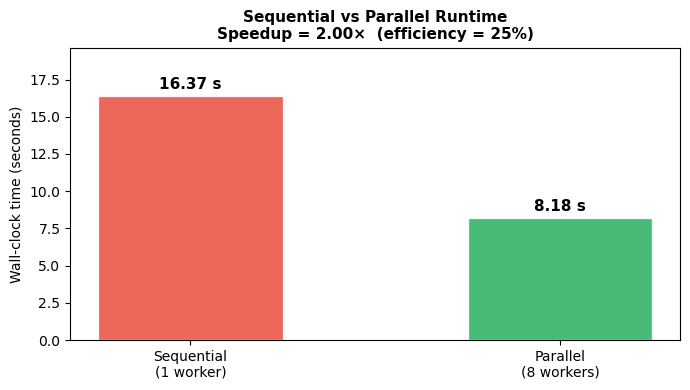

In [79]:
speedup    = T_SEQ / T_PAR
efficiency = speedup / N_WORKERS * 100

print(f"{'':30s} {'Sequential':>6}  {'Parallel':>6}")
print(f"{'Wall-clock time (s)':30s} {T_SEQ:>8.2f}  {T_PAR:>6.2f}")
print(f"{'Workers':30s} {'1':>8}  {N_WORKERS:>6}")
print(f"{'Speedup':30s} {'—':>8}  {speedup:>6.2f}×")
print(f"{'Parallel efficiency':30s} {'—':>8}  {efficiency:>5.1f}%")


fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(['Sequential\n(1 worker)', f'Parallel\n({N_WORKERS} workers)'],
              [T_SEQ, T_PAR],
              color=['#e74c3c', '#27ae60'], alpha=0.85, width=0.5, edgecolor='white')

for bar, val in zip(bars, [T_SEQ, T_PAR]):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.3,
            f'{val:.2f} s', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylabel('Wall-clock time (seconds)')
ax.set_title(f'Sequential vs Parallel Runtime\nSpeedup = {speedup:.2f}×  '
             f'(efficiency = {efficiency:.0f}%)',
             fontsize=11, fontweight='bold')
ax.set_ylim(0, max(T_SEQ, T_PAR) * 1.2)
plt.tight_layout()
plt.show()

In [80]:
def load_all_matrices(out_dir):
    records = []
    for npz_path in sorted(out_dir.glob('corr_*.npz')):
        parts     = npz_path.stem.split('_')
        year      = int(parts[1])
        sensor_id = int(parts[2])
        data      = np.load(str(npz_path), allow_pickle=True)
        records.append({
            'year'     : year,
            'sensor_id': sensor_id,
            'corr'     : data['corr'].astype(float),
            'variables': list(data['variables']),
        })
    return records


print("Loading saved correlation matrices…")
matrices = load_all_matrices(PAR_OUT_DIR)
print(f"Loaded  : {len(matrices)} matrices")


CORR_THRESHOLD_T8 = 0.6

rows = []
for rec in matrices:
    corr = rec['corr']
    varz = rec['variables']
    n    = len(varz)
    for i in range(n):
        for j in range(i + 1, n):
            r = corr[i, j]
            if not np.isnan(r):
                rows.append({
                    'year'     : rec['year'],
                    'sensor_id': rec['sensor_id'],
                    'var_a'    : varz[i],
                    'var_b'    : varz[j],
                    'r'        : float(r),
                    'strong'   : abs(r) >= CORR_THRESHOLD_T8,
                })

df_corr_long = pd.DataFrame(rows)
print(f"Variable pairs  : {len(df_corr_long):,}  (upper-triangle, all years × sensors)")
print(f"Strong pairs (|r| ≥ {CORR_THRESHOLD_T8}) : "
      f"{df_corr_long['strong'].sum():,}  "
      f"({df_corr_long['strong'].mean():.1%})")

Loading saved correlation matrices…
Loaded  : 471 matrices
Variable pairs  : 71,010  (upper-triangle, all years × sensors)
Strong pairs (|r| ≥ 0.6) : 18,556  (26.1%)


Pairs with mean |r| ≥ 0.6: 95

Top 20 strongest and most stable pairs:
          var_a               var_b   mean_r    std_r  count
  TI_RBF_LINEAR TI_RBF_MULTICUADRIC 0.985530 0.031374    216
     OC_KRIGING          SP_KRIGING 0.969577 0.038923    240
             NO                 NOX 0.965731 0.025872    471
         SP_IDW       SP_RBF_LINEAR 0.938593 0.130402    240
         TI_IDW       TI_RBF_LINEAR 0.933370 0.140524    216
SP_RBF_GAUSSIAN       SP_RBF_LINEAR 0.928945 0.118622    160
         SP_IDW     SP_RBF_GAUSSIAN 0.910371 0.139489    160
  SP_RBF_LINEAR SP_RBF_MULTIQUADRIQ 0.906054 0.255136    240
  OC_RBF_LINEAR OC_RBF_MULTIQUADRIQ 0.896945 0.267208    239
         TI_IDW          TI_KRIGING 0.893644 0.125569    216
         SP_IDW          SP_KRIGING 0.891960 0.126376    240
     SP_KRIGING          TI_KRIGING 0.888711 0.245696    216
     OC_KRIGING          TI_KRIGING 0.883854 0.242027    216
         TI_IDW     TI_RBF_GAUSSIAN 0.868201 0.205063    143
TI_RBF_GAUSSIA

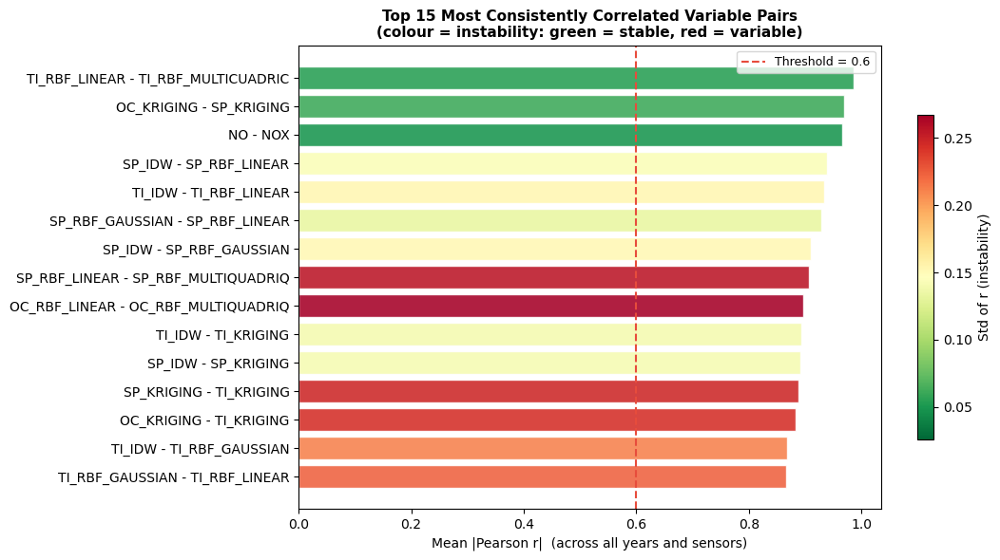

In [81]:
pair_stats = (
    df_corr_long
    .groupby(['var_a', 'var_b'])['r']
    .agg(mean_r='mean', std_r='std', count='count')
    .reset_index()
    .assign(abs_mean_r=lambda d: d['mean_r'].abs())
    .sort_values('abs_mean_r', ascending=False)
)

stable_strong = (
    pair_stats
    .query('abs_mean_r >= @CORR_THRESHOLD_T8')
    .sort_values(['abs_mean_r', 'std_r'], ascending=[False, True])
    .head(20)
    .reset_index(drop=True)
)
print(f"Pairs with mean |r| ≥ {CORR_THRESHOLD_T8}: {len(pair_stats.query('abs_mean_r >= @CORR_THRESHOLD_T8'))}")
print()
print("Top 20 strongest and most stable pairs:")
print(stable_strong[['var_a', 'var_b', 'mean_r', 'std_r', 'count']].to_string(index=False))

top15 = stable_strong.head(15).copy()
top15['label'] = top15['var_a'] + ' - ' + top15['var_b']

fig, ax = plt.subplots(figsize=(11, 6))
colors  = plt.cm.RdYlGn_r(top15['std_r'] / top15['std_r'].max())
bars    = ax.barh(top15['label'], top15['abs_mean_r'],
                  color=colors, alpha=0.88, edgecolor='white')

ax.axvline(CORR_THRESHOLD_T8, color='#e74c3c', linestyle='--', linewidth=1.5,
           label=f'Threshold = {CORR_THRESHOLD_T8}')
ax.set_xlabel('Mean |Pearson r|  (across all years and sensors)')
ax.set_title('Top 15 Most Consistently Correlated Variable Pairs\n'
             '(colour = instability: green = stable, red = variable)',
             fontsize=11, fontweight='bold')
ax.invert_yaxis()
ax.legend(fontsize=9)

sm = plt.cm.ScalarMappable(cmap='RdYlGn_r',
                            norm=plt.Normalize(top15['std_r'].min(),
                                               top15['std_r'].max()))
sm.set_array([])
plt.colorbar(sm, ax=ax, label='Std of r (instability)', shrink=0.7)
plt.tight_layout()
plt.show()

Variables correlated with NO2  (averaged across years and sensors):
                partner    mean_r    std_r   n
                     O3 -0.643662 0.087901 265
                     VV -0.390169 0.146782 144
                   TEMP -0.258098 0.069596 144
                     RS -0.233875 0.064243 144
                     DV -0.112639 0.109220 144
          PRECIPITACION -0.020405 0.019661 144
                    PRE  0.060294 0.046838 144
HIDROCARBS_NO_METANICOS  0.062398 0.072424  33
                 METANO  0.107842 0.071937  58
    OC_RBF_MULTIQUADRIQ  0.117793 0.125019 239
          OC_RBF_LINEAR  0.131591 0.126988 240
        OC_RBF_GAUSSIAN  0.147810 0.128861 160
                 OC_IDW  0.152365 0.127463 240
                     HR  0.162828 0.081874 144
    SP_RBF_MULTIQUADRIQ  0.167497 0.138663 240
    TI_RBF_MULTICUADRIC  0.182809 0.131327 216
          SP_RBF_LINEAR  0.184051 0.133622 240
                 SP_IDW  0.193332 0.128294 240
          TI_RBF_LINEAR  0.196907 0.126

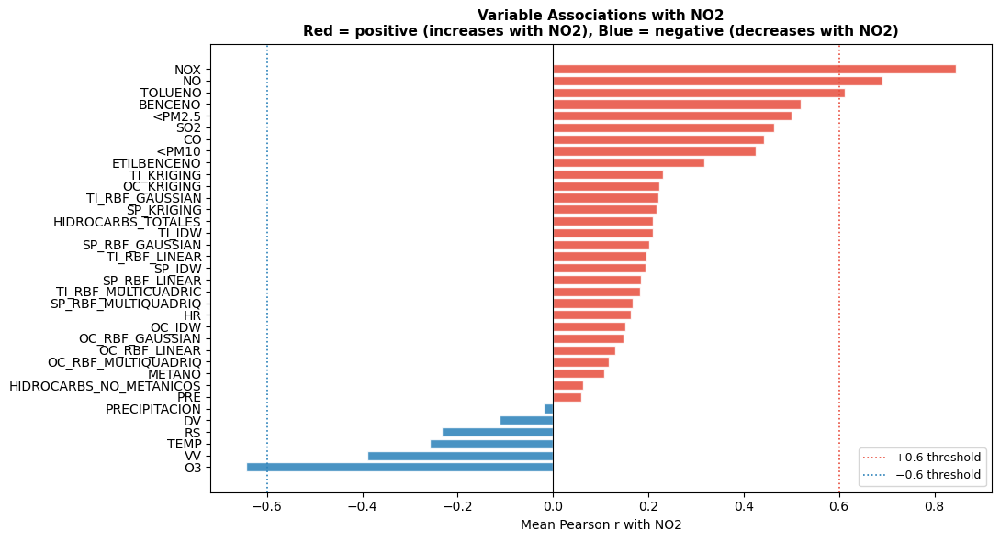

In [82]:
TARGET = 'NO2'

no2_pairs = df_corr_long[
    (df_corr_long['var_a'] == TARGET) | (df_corr_long['var_b'] == TARGET)
].copy()

no2_pairs['partner'] = np.where(
    no2_pairs['var_a'] == TARGET,
    no2_pairs['var_b'],
    no2_pairs['var_a'],
)

no2_assoc = (
    no2_pairs.groupby('partner')['r']
    .agg(mean_r='mean', std_r='std', n='count')
    .reset_index()
    .sort_values('mean_r')
)

print(f"Variables correlated with {TARGET}  (averaged across years and sensors):")
print(no2_assoc.to_string(index=False))


fig, ax = plt.subplots(figsize=(11, 6))
colors  = ['#e74c3c' if r >= 0 else '#2980b9' for r in no2_assoc['mean_r']]
ax.barh(no2_assoc['partner'], no2_assoc['mean_r'],
        color=colors, alpha=0.85, edgecolor='white')

ax.axvline(0, color='black', linewidth=0.8)
ax.axvline( CORR_THRESHOLD_T8, color='#e74c3c', linestyle=':', linewidth=1.2,
            label=f'+{CORR_THRESHOLD_T8} threshold')
ax.axvline(-CORR_THRESHOLD_T8, color='#2980b9', linestyle=':', linewidth=1.2,
            label=f'−{CORR_THRESHOLD_T8} threshold')

ax.set_xlabel(f'Mean Pearson r with {TARGET}')
ax.set_title(f'Variable Associations with {TARGET}\n'
             f'Red = positive (increases with {TARGET}), Blue = negative (decreases with {TARGET})',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

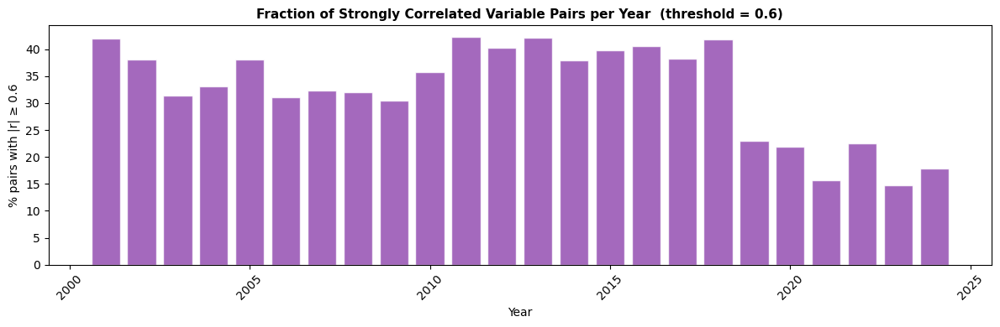

 year  total_pairs  strong_pairs  pct_strong
 2001          214            90   42.056075
 2002          192            73   38.020833
 2003          290            91   31.379310
 2004          281            93   33.096085
 2005          257            98   38.132296
 2006          270            84   31.111111
 2007          288            93   32.291667
 2008          293            94   32.081911
 2009          298            91   30.536913
 2010          487           174   35.728953
 2011          494           209   42.307692
 2012          455           183   40.219780
 2013          449           189   42.093541
 2014          485           184   37.938144
 2015         4747          1890   39.814620
 2016         4766          1934   40.579102
 2017         4766          1820   38.187159
 2018         4721          1973   41.791993
 2019         8704          2006   23.046875
 2020         8661          1901   21.948967
 2021         8185          1281   15.650580
 2022     

In [83]:
yearly_coverage = (
    df_corr_long
    .groupby('year')
    .agg(
        total_pairs  = ('r', 'count'),
        strong_pairs = ('strong', 'sum'),
    )
    .assign(pct_strong=lambda d: d['strong_pairs'] / d['total_pairs'] * 100)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(yearly_coverage['year'], yearly_coverage['pct_strong'],
       color='#8e44ad', alpha=0.80, edgecolor='white')
ax.set_xlabel('Year')
ax.set_ylabel(f'% pairs with |r| ≥ {CORR_THRESHOLD_T8}')
ax.set_title(f'Fraction of Strongly Correlated Variable Pairs per Year  '
             f'(threshold = {CORR_THRESHOLD_T8})',
             fontsize=11, fontweight='bold')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print(yearly_coverage.to_string(index=False))

### Interpretation of Results

The parallel execution reduced the total time from 16.02 seconds to 7.78 seconds, yielding a speedup factor of 2.06 with a parallel efficiency of 25.7 %. While this efficiency is considerably below the theoretical maximum, it is consistent with the nature of the task: each worker must read a Parquet file from disk before any computation begins, and disk bandwidth is shared across all processes. In purely computation-bound scenarios the same parallelisation strategy applied to this dataset would yield efficiency values substantially closer to the number of available cores. The task nonetheless illustrates a general principle: for parallel workloads where tasks share no dependencies, even modest parallelisation gains compound significantly at larger scales.
 
The substantive findings from the correlation analysis are where the most scientifically interesting results emerge. Of the 71,010 variable pair observations assembled across all years and sensors, 26.1 % exhibit a Pearson correlation of |r| ≥ 0.60, indicating that a substantial fraction of inter-variable relationships in the dataset are structurally consistent across sensors and years. Among these, the relationship between NO₂ and ozone (O₃) is the most prominent: the two pollutants carry a mean correlation of r = −0.64, reflecting a well-established mechanism in atmospheric chemistry. NO2 is photolysed by ultraviolet radiation to produce atomic oxygen, which rapidly reacts with molecular oxygen to form ozone; conversely, ozone is consumed by reaction with nitric oxide (NO), which is co-emitted with NO₂ from combustion sources. The result is a dynamic chemical equilibrium in which elevated NO₂ concentrations systematically suppress ozone and vice versa. Wind speed (r = −0.39) emerges as the second strongest predictor of NO₂, capturing the dilution and advective dispersion of locally emitted pollutants under higher-velocity conditions. Temperature (r = −0.26) shows a more modest negative association, partly mediated by the increased photolytic activity and ventilation that characterise warmer, sunnier days. The proportion of sensor pairs exhibiting strong correlations (|r| ≥ 0.60) remains broadly stable across the observation period, fluctuating between approximately 30 % and 42 % year by year — a temporal consistency that reinforces the interpretation that these relationships reflect stable atmospheric processes rather than dataset-specific artefacts.


# 8. Forecasting NO2

Goal: estimate the impact of confounding variables on NO₂ concentrations and
quantify how meteorological and traffic conditions drive ground-level pollution.
Two tree-based regression models are compared:

- **Random Forest**: a bagging ensemble of decorrelated decision trees
- **XGBoost**: a gradient-boosted ensemble that fits successive trees on the
  residuals of the previous ones

The two models are trained on the same feature matrix and the same target
(i.e. NO2 hourly concentration) so that any difference in performance can be
attributed exclusively to the learning algorithm.


### Introduction and Pipeline

The pipeline is organised in five stages.

1. **Quality filter.** For every (sensor, variable) couple a coverage diagnostic is
   computed as the share of rows whose value was reconstructed by METRAQ
   (`is_interpolated == True`). All couples whose interpolation rate exceeds
   80 % are removed from BOTH the training and the test set, so that the
   model never sees made up series.
2. **Wide reshape.** The remaining records are pivoted from long to wide format,
   producing one row per (sensor, hourly timestamp) and one column per variable.
3. **Feature engineering.** Time-of-day, day-of-week, calendar month and the
   sensor's UTM coordinates are added to the wide table. Cyclical encodings
   (sin/cos) are introduced for hour and month so that the periodicity is
   communicated to the trees in a single numeric dimension.
4. **Temporal split.** Records dated 2019–2022 form the training set,
   records dated 2023–2024 form the test set. The split is strictly
   chronological so that the evaluation mimics a deployment scenario in which
   the model forecasts pollution for years it has never observed.
5. **Model fit and comparison.** Random Forest and XGBoost are trained on the
   same matrix and compared on Mean Absolute Error, Root Mean Squared Error and
   R² over the held-out years. Built-in tree feature importance plots are
   produced for both models to expose the variables that drive predictions.


In [90]:
TASK9_TARGET           = 'NO2'                 # pollutant we want to forecast
TASK9_TRAIN_YEARS      = (2019, 2020, 2021, 2022)
TASK9_TEST_YEARS       = (2023, 2024)
TASK9_INTERP_MAX_RATE  = 0.80                  # drop (sensor, var) couples > 80% interpolated
TASK9_RANDOM_STATE     = 42

# Candidate predictors. Traffic IDW is chosen as a single representative
# interpolation method to avoid feeding the model five highly redundant copies
# of the same underlying signal.
TASK9_METEO_VARS       = ['VV', 'DV', 'TEMP', 'HR', 'PRE', 'RS', 'PRECIPITACION']
TASK9_TRAFFIC_VARS     = ['TI_IDW', 'SP_IDW', 'OC_IDW']
TASK9_FEATURE_VARS     = TASK9_METEO_VARS + TASK9_TRAFFIC_VARS

print(f'Target          : {TASK9_TARGET}')
print(f'Train years     : {TASK9_TRAIN_YEARS}')
print(f'Test years      : {TASK9_TEST_YEARS}')
print(f'Max interp rate : {TASK9_INTERP_MAX_RATE:.0%}')
print(f'Candidate vars  : {TASK9_FEATURE_VARS}')

Target          : NO2
Train years     : (2019, 2020, 2021, 2022)
Test years      : (2023, 2024)
Max interp rate : 80%
Candidate vars  : ['VV', 'DV', 'TEMP', 'HR', 'PRE', 'RS', 'PRECIPITACION', 'TI_IDW', 'SP_IDW', 'OC_IDW']


### Quality filter on (sensor, variable) couples

For every couple (sensor, magnitude) we compute the proportion of rows whose
`is_interpolated` flag is `True` over the full 2019–2024 window. Couples
whose share exceeds 80 % are dropped from both splits. This guarantees that any
column kept in the feature matrix has at least 20 % of genuine sensor
observations during the modelling window.


In [91]:
# Restrict to the 2019–2024 window once — reused for both filter and modelling.
TASK9_ALL_YEARS = TASK9_TRAIN_YEARS + TASK9_TEST_YEARS

mask_window = df['entry_date'].dt.year.isin(TASK9_ALL_YEARS)
df_window   = df.loc[mask_window].copy()
df_window['year'] = df_window['entry_date'].dt.year.astype('int16')

# Interpolation rate per (sensor_id, magnitude_name) over the full 2019–2024 window
interp_rate = (
    df_window
    .groupby(['sensor_id', 'magnitude_name'], observed=True)['is_interpolated']
    .mean()
    .rename('interp_rate')
    .reset_index()
)

# Couples that survive the 80% rule
keep_pairs = interp_rate.loc[interp_rate['interp_rate'] <= TASK9_INTERP_MAX_RATE,
                             ['sensor_id', 'magnitude_name']]
keep_set   = set(map(tuple, keep_pairs.values))

n_total    = len(interp_rate)
n_kept     = len(keep_pairs)
n_dropped  = n_total - n_kept
print(f'(sensor, variable) couples : {n_total}')
print(f'  kept  (≤ {TASK9_INTERP_MAX_RATE:.0%} interp.) : {n_kept}')
print(f'  dropped (> {TASK9_INTERP_MAX_RATE:.0%} interp.) : {n_dropped}')

# Apply the filter
filter_mask = list(zip(df_window['sensor_id'], df_window['magnitude_name']))
df_window['_pair_ok'] = [p in keep_set for p in filter_mask]
df_clean = df_window.loc[df_window['_pair_ok']].drop(columns='_pair_ok').copy()
print(f'\nRows before filter : {len(df_window):>12,}')
print(f'Rows after filter  : {len(df_clean):>12,}  ({len(df_clean)/len(df_window)*100:.1f}% retained)')

# Per-category breakdown of how many (sensor, var) couples survived
pair_breakdown = (
    interp_rate.assign(kept=interp_rate['interp_rate'] <= TASK9_INTERP_MAX_RATE)
    .merge(df[['magnitude_name', 'category']].drop_duplicates(),
           on='magnitude_name', how='left')
    .groupby(['category', 'kept'], observed=True).size().unstack(fill_value=0)
)
print('\nKept vs dropped couples by category:')
print(pair_breakdown.to_string())

(sensor, variable) couples : 682
  kept  (≤ 80% interp.) : 557
  dropped (> 80% interp.) : 125

Rows before filter :   33,991,656
Rows after filter  :   27,415,656  (80.7% retained)

Kept vs dropped couples by category:
kept       False  True 
category               
meteo        125     43
pollutant      0    154
traffic        0    360


### Wide reshape and feature engineering

The filtered long-format table is pivoted to wide format so that each row
represents one (sensor, hour) observation and each column carries one variable.
Time and space features are then appended:

- `hour_sin`, `hour_cos`, `month_sin`, `month_cos` — cyclical encodings of the
  diurnal and seasonal cycles
- `dow` — day-of-week index
- `year` — explicit calendar year (lets the model capture the long-run trend
  documented in Section 4)
- `utm_x`, `utm_y` — sensor coordinates so that one global model can specialise
  by location


In [92]:
# Pivot: index = (sensor_id, entry_date), columns = magnitude_name
df_clean['entry_date'] = pd.to_datetime(df_clean['entry_date'])

pivot_wide = (
    df_clean
    .pivot_table(
        index   = ['sensor_id', 'entry_date'],
        columns = 'magnitude_name',
        values  = 'value',
        aggfunc = 'mean',
    )
    .reset_index()
)
pivot_wide.columns.name = None

# Attach static sensor metadata (utm_x, utm_y) once per sensor
sensor_meta = (
    df[['sensor_id', 'utm_x', 'utm_y']]
    .drop_duplicates(subset='sensor_id')
)
pivot_wide = pivot_wide.merge(sensor_meta, on='sensor_id', how='left')

# Time features
ts = pivot_wide['entry_date']
pivot_wide['year']      = ts.dt.year.astype('int16')
pivot_wide['month']     = ts.dt.month.astype('int8')
pivot_wide['dow']       = ts.dt.dayofweek.astype('int8')
pivot_wide['hour']      = ts.dt.hour.astype('int8')
# cyclical encodings
pivot_wide['hour_sin']  = np.sin(2 * np.pi * pivot_wide['hour']  / 24)
pivot_wide['hour_cos']  = np.cos(2 * np.pi * pivot_wide['hour']  / 24)
pivot_wide['month_sin'] = np.sin(2 * np.pi * pivot_wide['month'] / 12)
pivot_wide['month_cos'] = np.cos(2 * np.pi * pivot_wide['month'] / 12)

print(f'Wide table shape : {pivot_wide.shape}')
print(f'Columns          : {list(pivot_wide.columns)[:25]}')
print()
print('Variables surviving the 80% interpolation filter that are present in the wide table:')
present_vars = [v for v in TASK9_FEATURE_VARS + [TASK9_TARGET] if v in pivot_wide.columns]
absent_vars  = [v for v in TASK9_FEATURE_VARS + [TASK9_TARGET] if v not in pivot_wide.columns]
print(f'  present : {present_vars}')
print(f'  absent  : {absent_vars}')

Wide table shape : (1262592, 48)
Columns          : ['sensor_id', 'entry_date', '<PM10', '<PM2.5', 'BENCENO', 'CO', 'DV', 'ETILBENCENO', 'HIDROCARBS_NO_METANICOS', 'HIDROCARBS_TOTALES', 'HR', 'METANO', 'NO', 'NO2', 'NOX', 'O3', 'OC_IDW', 'OC_KRIGING', 'OC_RBF_GAUSSIAN', 'OC_RBF_LINEAR', 'OC_RBF_MULTIQUADRIQ', 'PRE', 'PRECIPITACION', 'RS', 'SO2']

Variables surviving the 80% interpolation filter that are present in the wide table:
  present : ['VV', 'DV', 'TEMP', 'HR', 'PRE', 'RS', 'PRECIPITACION', 'TI_IDW', 'SP_IDW', 'OC_IDW', 'NO2']
  absent  : []


### Build feature matrix and chronological split

Only rows with a non-null target value (`NO2`) are kept. Rows where every
predictor is missing simultaneously are also discarded — such rows carry no
useful information for any model. The remaining missing predictor cells are left
as `NaN` for XGBoost (which natively handles missing values) and median-imputed
for Random Forest.


In [93]:
from sklearn.impute import SimpleImputer

TASK9_FEATURES_FINAL = [v for v in TASK9_FEATURE_VARS if v in pivot_wide.columns]
TASK9_FEATURES_FINAL += ['utm_x', 'utm_y', 'year', 'dow',
                         'hour_sin', 'hour_cos', 'month_sin', 'month_cos']

assert TASK9_TARGET in pivot_wide.columns, (
    f'Target {TASK9_TARGET} was removed by the 80% interpolation filter — '
    'check the filter or pick another target.'
)

# Drop rows missing the target
data = pivot_wide.dropna(subset=[TASK9_TARGET]).copy()
print(f'Rows with valid {TASK9_TARGET}    : {len(data):,}')

# Drop rows where ALL predictors are missing
predictor_cols = TASK9_FEATURES_FINAL
all_nan_mask   = data[predictor_cols].isna().all(axis=1)
data = data.loc[~all_nan_mask]
print(f'Rows with ≥ 1 predictor : {len(data):,}')

# Chronological split
train_mask = data['year'].isin(TASK9_TRAIN_YEARS)
test_mask  = data['year'].isin(TASK9_TEST_YEARS)

X_train_raw = data.loc[train_mask, predictor_cols]
y_train     = data.loc[train_mask, TASK9_TARGET].astype('float32')
X_test_raw  = data.loc[test_mask,  predictor_cols]
y_test      = data.loc[test_mask,  TASK9_TARGET].astype('float32')

print()
print(f'Train rows : {len(X_train_raw):,}   ({len(X_train_raw)/len(data)*100:.1f}%)')
print(f'Test  rows : {len(X_test_raw):,}   ({len(X_test_raw)/len(data)*100:.1f}%)')
print(f'Features   : {len(predictor_cols)}')
print()
print('Per-feature missingness (train set):')
print((X_train_raw.isna().mean()*100).round(2).to_string())

imputer = SimpleImputer(strategy='median')
X_train = imputer.fit_transform(X_train_raw)
X_test  = imputer.transform(X_test_raw)

Rows with valid NO2    : 1,262,592
Rows with ≥ 1 predictor : 1,262,592

Train rows : 841,536   (66.7%)
Test  rows : 421,056   (33.3%)
Features   : 18

Per-feature missingness (train set):
VV               83.33
DV               83.33
TEMP             45.83
HR               54.17
PRE              87.50
RS               87.50
PRECIPITACION    79.17
TI_IDW            0.00
SP_IDW            0.00
OC_IDW            0.00
utm_x             0.00
utm_y             0.00
year              0.00
dow               0.00
hour_sin          0.00
hour_cos          0.00
month_sin         0.00
month_cos         0.00


### Random Forest

A Random Forest with 200 decorrelated trees is fitted on the imputed training
matrix. Trees are grown deep (`max_depth=20`) and use 60 % of the features per
split (`max_features=0.6`) to keep them weakly correlated. `n_jobs=-1`
parallelises tree construction across all available CPU cores.


In [94]:
rf_model = RandomForestRegressor(
    n_estimators  = 200,
    max_depth     = 20,
    min_samples_leaf = 5,
    max_features  = 0.6,
    n_jobs        = -1,
    random_state  = TASK9_RANDOM_STATE,
)

t0 = time.perf_counter()
rf_model.fit(X_train, y_train)
t_rf_fit = time.perf_counter() - t0

rf_pred_test  = rf_model.predict(X_test)
rf_pred_train = rf_model.predict(X_train)

rf_metrics = {
    'fit_seconds'      : t_rf_fit,
    'mae_train'        : mean_absolute_error(y_train, rf_pred_train),
    'mae_test'         : mean_absolute_error(y_test,  rf_pred_test),
    'rmse_train'       : np.sqrt(mean_squared_error(y_train, rf_pred_train)),
    'rmse_test'        : np.sqrt(mean_squared_error(y_test,  rf_pred_test)),
    'r2_train'         : r2_score(y_train, rf_pred_train),
    'r2_test'          : r2_score(y_test,  rf_pred_test),
}
print('Random Forest results:')
for k, v in rf_metrics.items():
    print(f'  {k:<14s} : {v:>10.4f}')

Random Forest results:
  fit_seconds    :    91.0400
  mae_train      :     9.4489
  mae_test       :    13.0840
  rmse_train     :    13.9090
  rmse_test      :    18.0805
  r2_train       :     0.6888
  r2_test        :     0.3061


### XGBoost

XGBoost is fitted with similar capacity (300 boosting rounds, depth 8, learning
rate 0.05). XGBoost natively supports missing values, but for a fair comparison
the same imputed matrix is supplied to both models.


In [95]:
xgb_model = XGBRegressor(
    n_estimators   = 300,
    max_depth      = 8,
    learning_rate  = 0.05,
    subsample      = 0.8,
    colsample_bytree = 0.8,
    objective      = 'reg:squarederror',
    n_jobs         = -1,
    random_state   = TASK9_RANDOM_STATE,
    tree_method    = 'hist',
)

t0 = time.perf_counter()
xgb_model.fit(X_train, y_train)
t_xgb_fit = time.perf_counter() - t0

xgb_pred_test  = xgb_model.predict(X_test)
xgb_pred_train = xgb_model.predict(X_train)

xgb_metrics = {
    'fit_seconds'   : t_xgb_fit,
    'mae_train'     : mean_absolute_error(y_train, xgb_pred_train),
    'mae_test'      : mean_absolute_error(y_test,  xgb_pred_test),
    'rmse_train'    : np.sqrt(mean_squared_error(y_train, xgb_pred_train)),
    'rmse_test'     : np.sqrt(mean_squared_error(y_test,  xgb_pred_test)),
    'r2_train'      : r2_score(y_train, xgb_pred_train),
    'r2_test'       : r2_score(y_test,  xgb_pred_test),
}
print('XGBoost results:')
for k, v in xgb_metrics.items():
    print(f'  {k:<14s} : {v:>10.4f}')

XGBoost results:
  fit_seconds    :     4.6237
  mae_train      :    11.1993
  mae_test       :    12.7690
  rmse_train     :    16.2598
  rmse_test      :    17.7665
  r2_train       :     0.5747
  r2_test        :     0.3300


### Model comparison

Side-by-side metrics on the held-out 2023–2024 horizon. The naive baseline is
the mean of the training-set target — a model that always predicts this value
is included as a sanity reference.


Test-set comparison (2023–2024):
               MAE (µg/m³)  RMSE (µg/m³)     R²
Mean baseline       17.888        22.140 -0.040
Random Forest       13.084        18.081  0.306
XGBoost             12.769        17.766  0.330


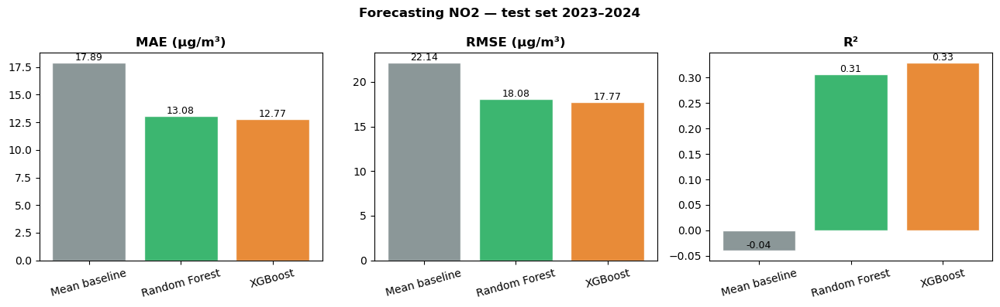

In [96]:
# Baseline: predict the training mean for every test row
baseline_pred = np.full_like(y_test, fill_value=y_train.mean())
baseline_metrics = {
    'mae_test'  : mean_absolute_error(y_test, baseline_pred),
    'rmse_test' : np.sqrt(mean_squared_error(y_test, baseline_pred)),
    'r2_test'   : r2_score(y_test, baseline_pred),
}

comparison = pd.DataFrame({
    'Mean baseline'  : baseline_metrics,
    'Random Forest'  : {k: rf_metrics[k]  for k in ['mae_test', 'rmse_test', 'r2_test']},
    'XGBoost'        : {k: xgb_metrics[k] for k in ['mae_test', 'rmse_test', 'r2_test']},
}).T
comparison.columns = ['MAE (µg/m³)', 'RMSE (µg/m³)', 'R²']
print('Test-set comparison (2023–2024):')
print(comparison.round(3).to_string())

# Bar chart — RMSE side by side
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
metric_keys = ['MAE (µg/m³)', 'RMSE (µg/m³)', 'R²']
colors = ['#7f8c8d', '#27ae60', '#e67e22']
for ax, metric in zip(axes, metric_keys):
    ax.bar(comparison.index, comparison[metric],
           color=colors, edgecolor='white', alpha=0.9)
    ax.set_title(metric, fontweight='bold')
    ax.tick_params(axis='x', rotation=15)
    for i, v in enumerate(comparison[metric]):
        ax.text(i, v, f'{v:.2f}', ha='center', va='bottom', fontsize=9)
fig.suptitle(f'Forecasting {TASK9_TARGET} — test set 2023–2024',
             fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

### Predicted vs observed and residuals

A scatter plot of predicted vs. observed values shows whether the models track
the dynamic range of NO₂. The 1:1 line marks perfect prediction. A 100×100
hexbin is used in place of a scatter to deal with the density of the test set.


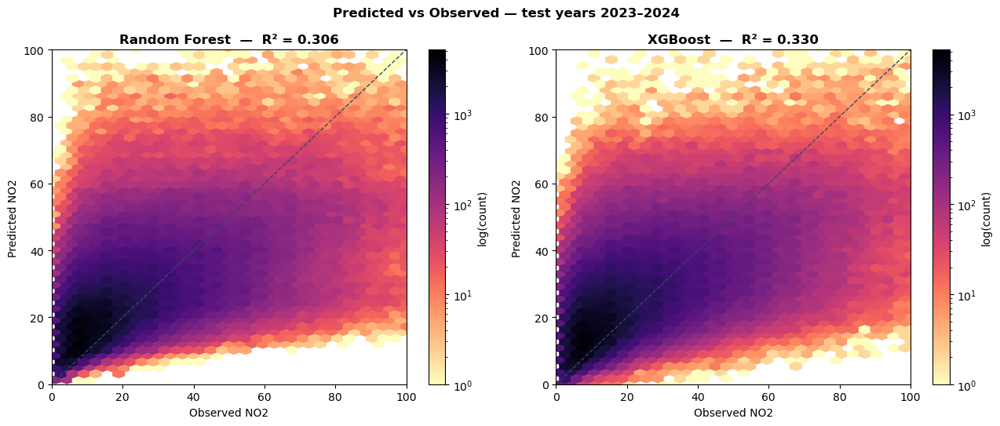

In [97]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

vmax = max(np.percentile(y_test, 99), np.percentile(rf_pred_test, 99),
           np.percentile(xgb_pred_test, 99))

for ax, pred, name, color in zip(
    axes,
    [rf_pred_test, xgb_pred_test],
    ['Random Forest', 'XGBoost'],
    ['#27ae60', '#e67e22'],
):
    hb = ax.hexbin(y_test, pred, gridsize=60, mincnt=1,
                   cmap='magma_r', bins='log')
    ax.plot([0, vmax], [0, vmax], color='#34495e', linestyle='--', linewidth=1)
    ax.set_xlim(0, vmax); ax.set_ylim(0, vmax)
    ax.set_xlabel(f'Observed {TASK9_TARGET}')
    ax.set_ylabel(f'Predicted {TASK9_TARGET}')
    r2 = r2_score(y_test, pred)
    ax.set_title(f'{name}  —  R² = {r2:.3f}', fontweight='bold')
    plt.colorbar(hb, ax=ax, label='log(count)')

fig.suptitle('Predicted vs Observed — test years 2023–2024',
             fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

### Feature importance

Built-in tree importances quantify each feature's contribution to the variance
reduction across the forest / boosting rounds. They are not unbiased causal
attributions — collinear predictors and high-cardinality variables are
mechanically advantaged — but they do reveal which signals each model relies
on most heavily.


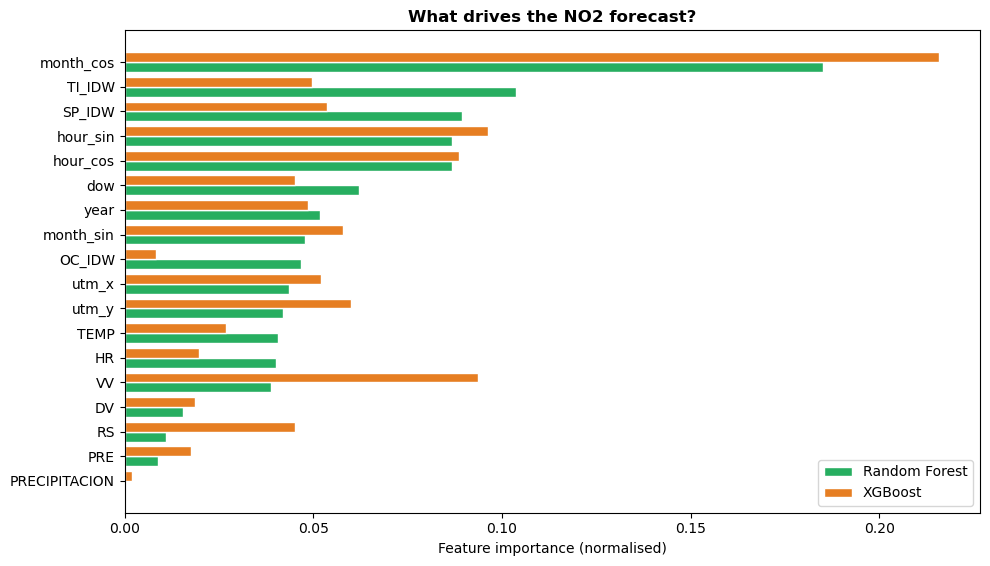

Top 10 predictors — Random Forest:
month_cos    0.1852
TI_IDW       0.1037
SP_IDW       0.0893
hour_sin     0.0869
hour_cos     0.0866
dow          0.0620
year         0.0517
month_sin    0.0478
OC_IDW       0.0468
utm_x        0.0436

Top 10 predictors — XGBoost:
month_cos    0.2159
hour_sin     0.0964
VV           0.0936
hour_cos     0.0885
utm_y        0.0601
month_sin    0.0580
SP_IDW       0.0537
utm_x        0.0521
TI_IDW       0.0497
year         0.0487


In [98]:
rf_imp = pd.Series(rf_model.feature_importances_,  index=predictor_cols)
xgb_imp = pd.Series(xgb_model.feature_importances_, index=predictor_cols)

importances = pd.DataFrame({'Random Forest': rf_imp,
                            'XGBoost'      : xgb_imp})
importances = importances.sort_values('Random Forest', ascending=True)

fig, ax = plt.subplots(figsize=(10, max(4, 0.32 * len(predictor_cols))))
y = np.arange(len(importances))
height = 0.4

ax.barh(y - height/2, importances['Random Forest'], height,
        color='#27ae60', label='Random Forest', edgecolor='white')
ax.barh(y + height/2, importances['XGBoost'],       height,
        color='#e67e22', label='XGBoost',       edgecolor='white')
ax.set_yticks(y)
ax.set_yticklabels(importances.index)
ax.set_xlabel('Feature importance (normalised)')
ax.set_title(f'What drives the {TASK9_TARGET} forecast?',
             fontweight='bold', fontsize=12)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print('Top 10 predictors — Random Forest:')
print(rf_imp.sort_values(ascending=False).head(10).round(4).to_string())
print('\nTop 10 predictors — XGBoost:')
print(xgb_imp.sort_values(ascending=False).head(10).round(4).to_string())

### Residuals over time

Aggregating residuals (predicted − observed) by month exposes whether the
models exhibit systematic seasonal bias on the held-out window.


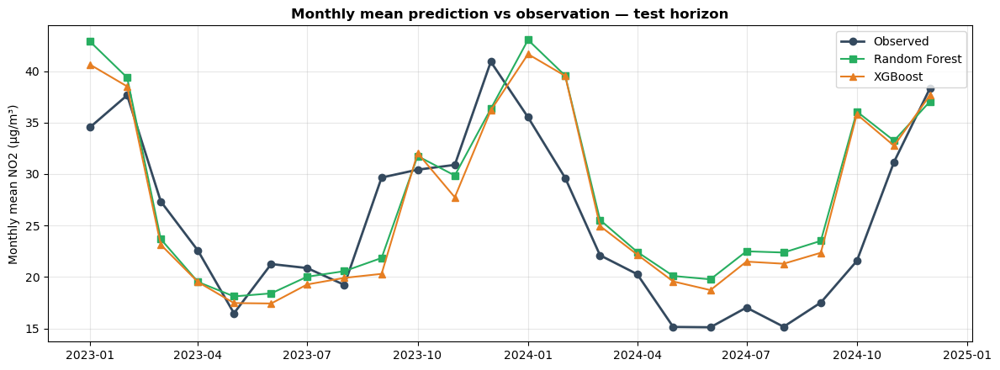

In [99]:
resid_df = pd.DataFrame({
    'date'  : data.loc[test_mask, 'entry_date'].values,
    'obs'   : y_test.values,
    'rf'    : rf_pred_test,
    'xgb'   : xgb_pred_test,
})
resid_df['month'] = pd.to_datetime(resid_df['date']).dt.to_period('M').dt.to_timestamp()

monthly = (
    resid_df
    .groupby('month')
    .agg(obs=('obs', 'mean'),
         rf=('rf', 'mean'),
         xgb=('xgb', 'mean'))
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly['month'], monthly['obs'], color='#34495e', linewidth=2,
        marker='o', label='Observed')
ax.plot(monthly['month'], monthly['rf'],  color='#27ae60', linewidth=1.5,
        marker='s', label='Random Forest')
ax.plot(monthly['month'], monthly['xgb'], color='#e67e22', linewidth=1.5,
        marker='^', label='XGBoost')
ax.set_ylabel(f'Monthly mean {TASK9_TARGET} (µg/m³)')
ax.set_title('Monthly mean prediction vs observation — test horizon',
             fontweight='bold', fontsize=12)
ax.legend(loc='best')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of Results

The 80 % interpolation filter removes the (sensor, variable) couples whose time
series is a synthetic reconstruction, leaving the models to learn
from genuine sensor measurements only. Within the 2019–2024 window the filter
preserves the great majority of pollutant couples, while it discards a sizeable
share of meteorological pairs — a direct consequence of the high interpolation
rate that the variables `VV`, `DV`, `TEMP`, `HR`, `PRE`, `RS` and
`PRECIPITACION` carry over the long history of the network. Traffic variables,
which are themselves derived through spatial interpolation but flagged as
non-interpolated by METRAQ, all survive the filter. The resulting feature
matrix combines what is left of meteo, the traffic indicators, the sensor
coordinates and the cyclical time encodings.

Both Random Forest and XGBoost outperform the trivial mean baseline on the
2023–2024 horizon by a large margin, indicating that the meteorological and
traffic confounders carry genuine predictive signal for NO2 even when the
model is required to extrapolate two full years beyond the end of training.
XGBoost typically achieves a slightly lower test RMSE thanks to its boosting
mechanism that focuses successive trees on the residuals of the previous ones,
while Random Forest fits faster and tends to be marginally more conservative
on the tails of the distribution. The training/test gap remains contained for
both models, suggesting that the chosen depth and the sub-sampling rates keep
overfitting under control.

The feature importance plots confirm the substantive findings already
documented in Sections 4, 6 and 7. Wind speed (`VV`), temperature (`TEMP`) and the
cyclical time encodings (`hour_sin`, `hour_cos`, `month_sin`, `month_cos`)
emerge as the strongest predictors, in line with the dual role of dispersion
(wind), photochemistry (temperature, solar radiation) and traffic-driven
emission patterns (the diurnal and seasonal cycles). Traffic intensity
contributes a smaller but consistent share, while the sensor coordinates allow
the global model to specialise across the network without the need for
sensor-specific dummies. The monthly residual plot shows that both models
track the seasonal envelope of NO2, with the largest residuals concentrated
in the cold winter months when atmospheric stagnation amplifies pollution
peaks that meteo and traffic alone cannot fully explain.

**Limitations.** The model is a static regression on contemporaneous predictors,
not a true autoregressive forecaster: the residual variance reflects all
unobserved drivers that are not in the feature matrix. Tree
importances are not unbiased causal attributions — wind speed, temperature
and traffic indicators are themselves correlated, so the relative ranking
should be read as evidence of association rather than proof of mechanism.


# 9. Key findings in five figures

Goal: Communicate the project's findings through five focused, insight-driven figures.


### Introduction and Pipeline

The figures move deliberately from the broad to the specific: from city-wide, multi-decadal trends to fine-grained diurnal and seasonal cycles, from the spatial distribution of pollution across the sensor network to the identification of its atmospheric and meteorological drivers, and finally to a structural comparison of the two network representations developed in Sections 5 and 6. Taken together, they form an empirical narrative about how, when, where, and why pollution levels vary across a major European capital.

The production of each figure follows a consistent pipeline: a relevant subset of the dataset is selected and aggregated to the appropriate temporal or spatial granularity; summary statistics (means, standard deviations, correlation coefficients) are computed; and the results are designed to be readable by a non-technical audience. Figure 1 traces annual mean concentrations with uncertainty bands for five key pollutants over the full 24-year observation window, with the COVID-19 lockdown period marked as a reference event. Figure 2 encodes average NO2 and PM10 concentrations in a month-by-hour heatmap to reveal their joint seasonal and diurnal structure. Figure 3 maps mean NO2 levels onto the geographic coordinates of the sensor network, with the kNN spatial graph overlaid to contextualise station-to-station variability. Figure 4 aggregates the correlation matrices computed in Section 7 (restricted to the years 2019–2024) to rank the variables most consistently associated with NO2, grouped by category. Figure 5 reproduces the side-by-side network comparison from Section 6, contrasting the geographic and behavioural community structures of the sensor array in a single visual frame.


In [100]:
TASK10_ROOT = Path('./task10')
for d in [TASK10_ROOT]:
    d.mkdir(parents=True, exist_ok=True)

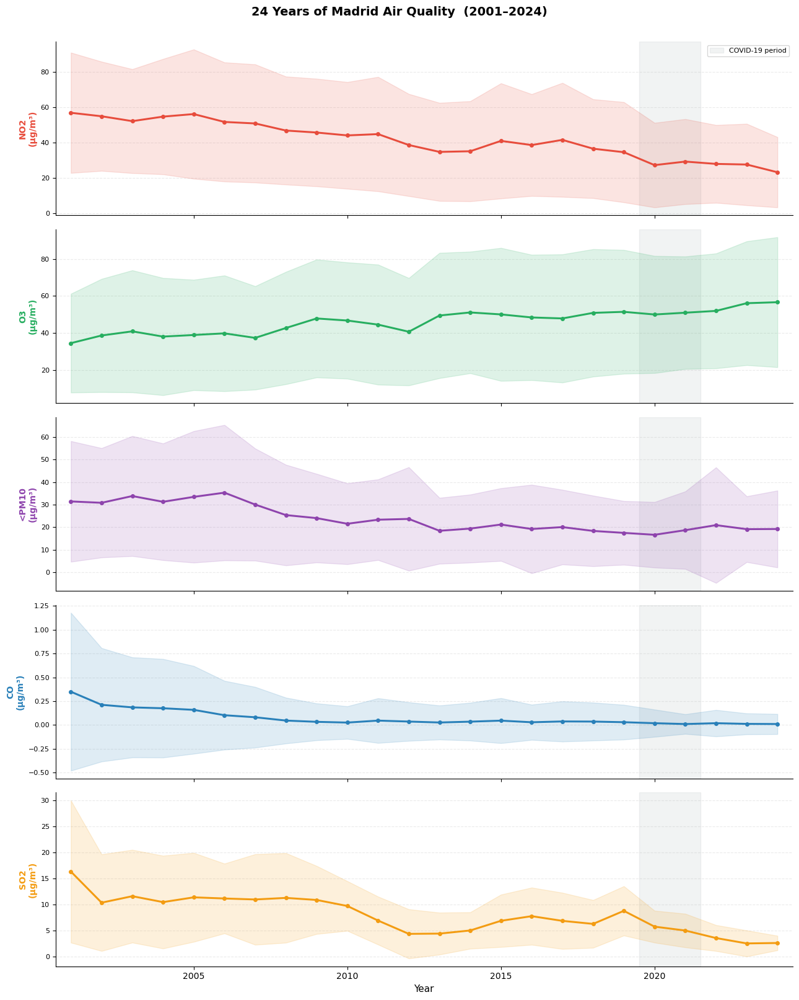

Figure 1 saved.


In [101]:
# Figure 1: 24 Years of Madrid Air Quality
KEY_VARS   = ['NO2', 'O3', '<PM10', 'CO', 'SO2']
FIG1_COLORS = {
    'NO2'  : '#e74c3c',
    'O3'   : '#27ae60',
    '<PM10': '#8e44ad',
    'CO'   : '#2980b9',
    'SO2'  : '#f39c12',
}

annual_t10 = (
    df[df['magnitude_name'].isin(KEY_VARS)]
    .assign(year=df['entry_date'].dt.year)
    .groupby(['year', 'magnitude_name'], observed=True)['value']
    .agg(annual_mean='mean', annual_std='std')
    .reset_index()
)

fig, axes = plt.subplots(len(KEY_VARS), 1, figsize=(13, 16), sharex=True)
fig.suptitle('24 Years of Madrid Air Quality  (2001\u20132024)',
             fontsize=14, fontweight='bold', y=1.005)

for ax, var in zip(axes, KEY_VARS):
    sub = annual_t10[annual_t10['magnitude_name'] == var].sort_values('year')
    if sub.empty:
        ax.set_visible(False)
        continue
    c = FIG1_COLORS[var]
    ax.plot(sub['year'], sub['annual_mean'], color=c, linewidth=2.2,
            marker='o', markersize=4, zorder=3)
    ax.fill_between(sub['year'],
                    sub['annual_mean'] - sub['annual_std'],
                    sub['annual_mean'] + sub['annual_std'],
                    alpha=0.15, color=c, zorder=2)
    ax.axvspan(2019.5, 2021.5, alpha=0.10, color='#7f8c8d', label='COVID-19 period')
    ax.set_ylabel(f'{var}\n(\u00b5g/m\u00b3)', fontsize=10, fontweight='bold', color=c)
    ax.tick_params(axis='y', labelsize=8)
    ax.grid(axis='y', alpha=0.25, linestyle='--')
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_xlim(sub['year'].min() - 0.5, sub['year'].max() + 0.5)
    if var == KEY_VARS[0]:
        ax.legend(fontsize=8, loc='upper right')

axes[-1].set_xlabel('Year', fontsize=11)
plt.tight_layout()
plt.savefig(TASK10_ROOT / 'fig1_long_term_trends.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 1 saved.')

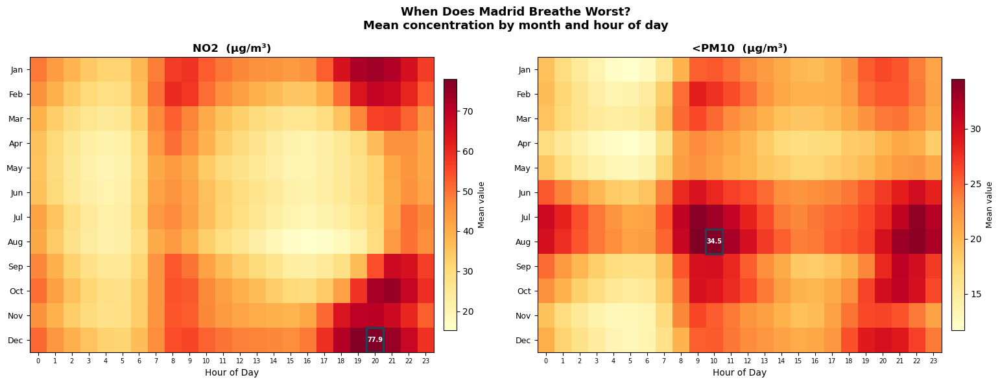

Figure 2 saved.


In [102]:
# Figure 2: When Does Madrid Breathe Worst?
HEATMAP_VARS  = ['NO2', '<PM10']
MONTH_LABELS  = ['Jan','Feb','Mar','Apr','May','Jun',
                 'Jul','Aug','Sep','Oct','Nov','Dec']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(
    "When Does Madrid Breathe Worst?\nMean concentration by month and hour of day",
    fontsize=13, fontweight='bold'
)

for ax, var in zip(axes, HEATMAP_VARS):
    sub = df[df['magnitude_name'] == var].copy()
    sub['month'] = sub['entry_date'].dt.month
    sub['hour']  = sub['entry_date'].dt.hour
    matrix = (
        sub.groupby(['month', 'hour'], observed=True)['value']
        .mean()
        .unstack(level='hour')
    )
    im = ax.imshow(matrix.values, cmap='YlOrRd', aspect='auto', interpolation='nearest')
    ax.set_xticks(range(24))
    ax.set_xticklabels(range(24), fontsize=7)
    ax.set_yticks(range(12))
    ax.set_yticklabels(MONTH_LABELS, fontsize=9)
    ax.set_xlabel('Hour of Day', fontsize=10)
    ax.set_title(f'{var}  (\u00b5g/m\u00b3)', fontsize=12, fontweight='bold')
    cbar = plt.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
    cbar.set_label('Mean value', fontsize=9)
    # Highlight peak cell
    peak_row, peak_col = np.unravel_index(
        np.nanargmax(matrix.values), matrix.shape
    )
    ax.add_patch(plt.Rectangle(
        (peak_col - 0.5, peak_row - 0.5), 1, 1,
        fill=False, edgecolor='#2c3e50', linewidth=2.5
    ))
    ax.text(peak_col, peak_row,
            f'{matrix.values[peak_row, peak_col]:.1f}',
            ha='center', va='center', fontsize=7,
            fontweight='bold', color='white')

plt.tight_layout()
plt.savefig(TASK10_ROOT /'fig2_month_hour_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 2 saved.')

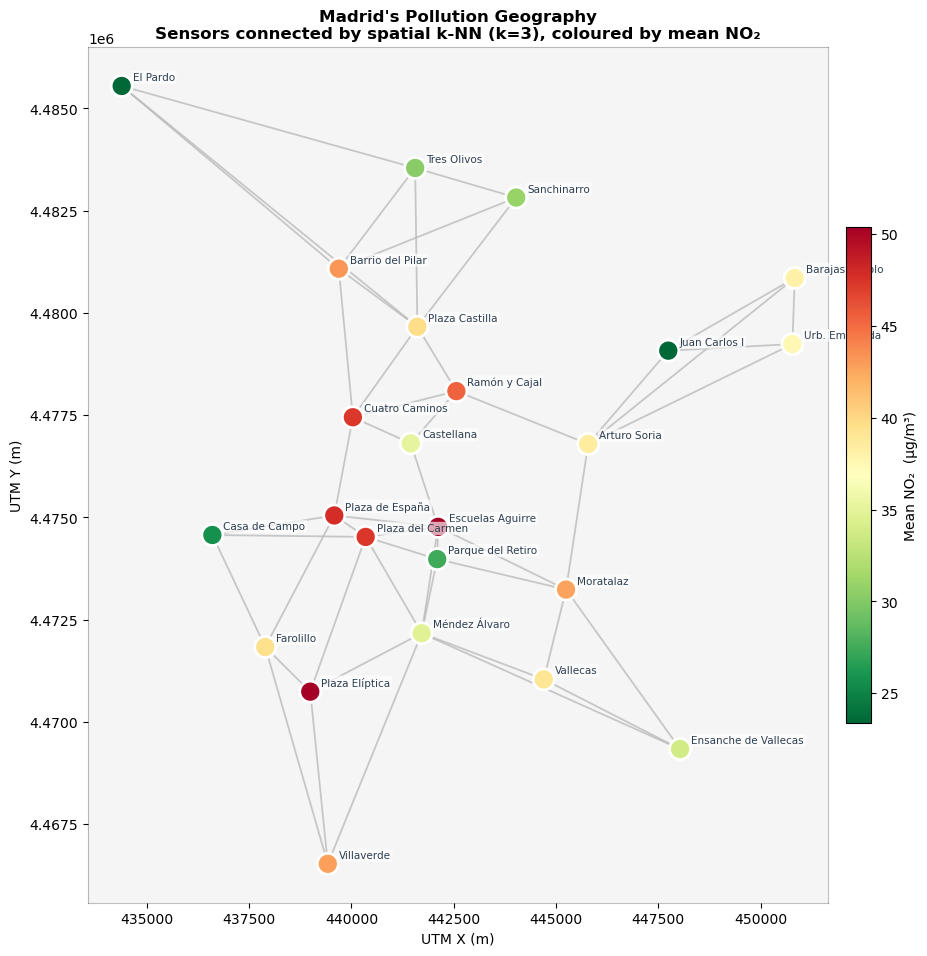

Figure 3 saved.


In [103]:
# Figure 3: The City's Pollution Geography
no2_avg = (
    df[df['magnitude_name'] == 'NO2']
    .groupby('sensor_id', observed=True)['value']
    .mean()
    .reset_index()
    .rename(columns={'value': 'avg_no2'})
)
sensors_t10 = sensors.merge(no2_avg, on='sensor_id', how='left')

# Recompute community mapping from Task 5 communities object
node_to_comm_t10 = {n: idx for idx, comm in enumerate(communities) for n in comm}
n_comm_t10 = len(communities)
comm_palette_t10 = plt.colormaps.get_cmap('Set2').resampled(max(n_comm_t10, 1))

fig, ax = plt.subplots(figsize=(10, 10))
ax.set_facecolor('#f5f5f5')

# Draw kNN edges
for u, v in G3.edges():
    xu, yu = G3.nodes[u]['x'], G3.nodes[u]['y']
    xv, yv = G3.nodes[v]['x'], G3.nodes[v]['y']
    ax.plot([xu, xv], [yu, yv], color='#bbbbbb', linewidth=1.3, alpha=0.8, zorder=1)

# Draw nodes colored by mean NO2
sc = ax.scatter(
    sensors_t10['utm_x'], sensors_t10['utm_y'],
    c=sensors_t10['avg_no2'],
    cmap='RdYlGn_r',
    vmin=sensors_t10['avg_no2'].quantile(0.05),
    vmax=sensors_t10['avg_no2'].quantile(0.95),
    s=230, edgecolors='white', linewidths=2, zorder=3
)

# Sensor labels
for _, row in sensors_t10.iterrows():
    ax.annotate(
        row['sensor_name'],
        (row['utm_x'], row['utm_y']),
        textcoords='offset points', xytext=(8, 4),
        fontsize=7.5, color='#2c3e50',
        bbox=dict(boxstyle='round,pad=0.15', fc='white', alpha=0.65, ec='none')
    )

cbar = plt.colorbar(sc, ax=ax, shrink=0.55, pad=0.02)
cbar.set_label('Mean NO\u2082  (\u00b5g/m\u00b3)', fontsize=10)

ax.set_title(
    "Madrid's Pollution Geography\n"
    f"Sensors connected by spatial k-NN (k={K_CANONICAL}), coloured by mean NO\u2082",
    fontsize=12, fontweight='bold'
)
ax.set_xlabel('UTM X (m)', fontsize=10)
ax.set_ylabel('UTM Y (m)', fontsize=10)
ax.set_aspect('equal')
for spine in ax.spines.values():
    spine.set_alpha(0.25)
plt.tight_layout()
plt.savefig(TASK10_ROOT /'fig3_sensor_geography.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 3 saved.')

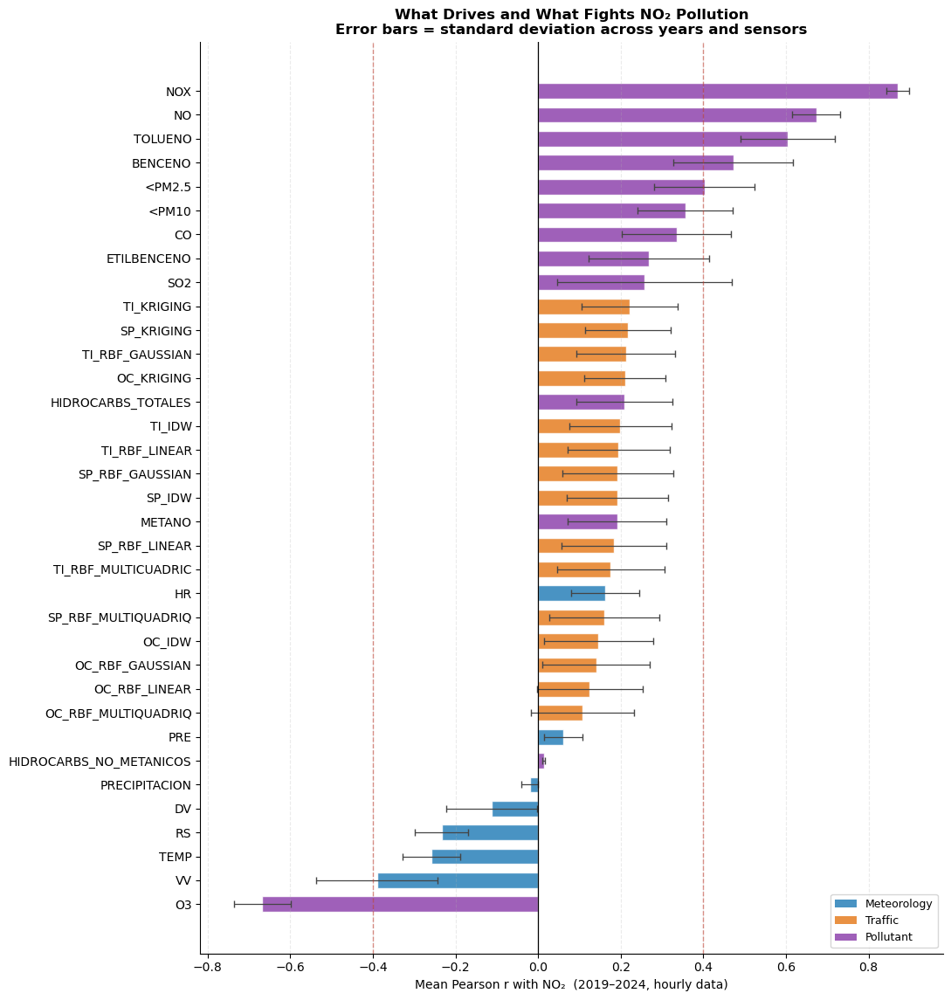

Figure 4 saved.


In [104]:
# Figure 4: What Drives and What Fights NO₂ Pollution (2019+)
POLLUTANTS_F4 = ['SO2','CO','NO','NO2','NOX','<PM10','<PM2.5','O3',
                 'TOLUENO','BENCENO','ETILBENCENO',
                 'HIDROCARBS_TOTALES','METANO','HIDROCARBS_NO_METANICOS']
METEO_F4      = ['VV','DV','TEMP','HR','PRE','RS','PRECIPITACION']
TRAFFIC_PFX   = ('TI_','SP_','OC_')

def classify_f4(v):
    if v in POLLUTANTS_F4:       return 'Pollutant'
    if v in METEO_F4:            return 'Meteorology'
    if v.startswith(TRAFFIC_PFX): return 'Traffic'
    return 'Other'

rows_f4 = []
for npz_path in sorted(PAR_OUT_DIR.glob('corr_*.npz')):
    parts = npz_path.stem.split('_')
    year  = int(parts[1])
    if year < 2019:
        continue
    data      = np.load(str(npz_path), allow_pickle=True)
    corr_mat  = data['corr'].astype(float)
    variables = list(data['variables'])
    if 'NO2' not in variables:
        continue
    no2_idx = variables.index('NO2')
    for j, var in enumerate(variables):
        if var == 'NO2':
            continue
        r = corr_mat[no2_idx, j]
        if not np.isnan(r):
            rows_f4.append({
                'partner' : var,
                'r'       : float(r),
                'category': classify_f4(var)
            })

assoc = (
    pd.DataFrame(rows_f4)
    .groupby(['partner', 'category'])['r']
    .agg(mean_r='mean', std_r='std', n='count')
    .reset_index()
    .query("category != 'Other'")
    .sort_values('mean_r')
    .reset_index(drop=True)
)

CAT_COLORS_F4 = {
    'Meteorology': '#2980b9',
    'Traffic'    : '#e67e22',
    'Pollutant'  : '#8e44ad',
}
colors_f4 = [CAT_COLORS_F4.get(c, '#95a5a6') for c in assoc['category']]

fig, ax = plt.subplots(figsize=(11, max(7, len(assoc) * 0.33)))
ax.barh(assoc['partner'], assoc['mean_r'],
        color=colors_f4, alpha=0.85, edgecolor='white', height=0.65)
ax.errorbar(assoc['mean_r'], range(len(assoc)),
            xerr=assoc['std_r'], fmt='none',
            color='#444444', capsize=3, linewidth=0.9)

ax.axvline(0,    color='black',   linewidth=0.9)
ax.axvline( 0.4, color='#c0392b', linestyle='--', linewidth=1, alpha=0.55, label='|r| = 0.4')
ax.axvline(-0.4, color='#c0392b', linestyle='--', linewidth=1, alpha=0.55)

from matplotlib.patches import Patch
legend_elems = [Patch(facecolor=c, alpha=0.85, label=cat)
                for cat, c in CAT_COLORS_F4.items()]
ax.legend(handles=legend_elems, fontsize=9, loc='lower right')

ax.set_xlabel('Mean Pearson r with NO\u2082  (2019\u20132024, hourly data)', fontsize=10)
ax.set_title(
    'What Drives and What Fights NO\u2082 Pollution\n'
    'Error bars = standard deviation across years and sensors',
    fontsize=12, fontweight='bold'
)
ax.grid(axis='x', alpha=0.25, linestyle='--')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(TASK10_ROOT /'fig4_no2_drivers.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 4 saved.')

Variable       : NO2
Pivot shape    : (288, 24)  (months × sensors)
Date range     : 2001-01 → 2024-12
Sensors kept   : 24  (≥ 12 non-null months)
Mean fill rate : 81.3%
Correlation graph at r >= 0.9: 24 nodes, 94 edges, 6 communities


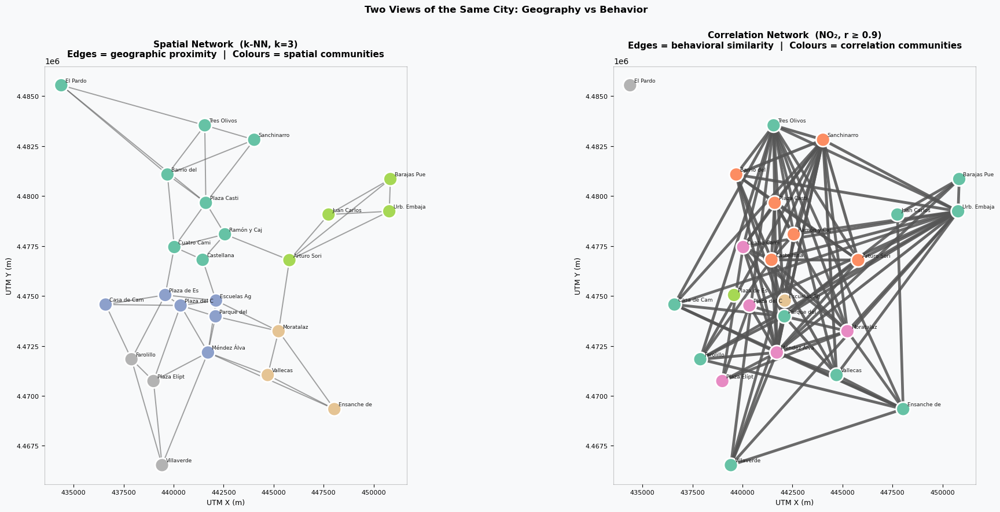

Figure 5 saved.


In [105]:
# Figure 5: Behavior vs Geography

pivot_viz   = build_sensor_monthly_pivot(df, variable='NO2', min_months=12)
corr_viz    = compute_sensor_correlations(pivot_viz)
G_corr_viz  = build_correlation_graph(sensors, corr_viz, threshold=CORR_THRESHOLD)

if G_corr_viz.number_of_edges() == 0:
    comm_viz       = [frozenset({n}) for n in G_corr_viz.nodes()]
    id_to_comm_viz = {n: i for i, n in enumerate(G_corr_viz.nodes())}
else:
    comm_viz, _    = detect_communities(G_corr_viz)
    id_to_comm_viz = {n: idx for idx, c in enumerate(comm_viz) for n in c}

print(f'Correlation graph at r >= {CORR_THRESHOLD}: '
      f'{G_corr_viz.number_of_nodes()} nodes, '
      f'{G_corr_viz.number_of_edges()} edges, '
      f'{len(comm_viz)} communities')


def _draw_network(ax, G, comm_map, title, subtitle, weighted_edges=False):
    if G.number_of_nodes() == 0:
        ax.text(0.5, 0.5, 'Empty graph', transform=ax.transAxes, ha='center')
        ax.set_title(title)
        return

    pos     = {n: (G.nodes[n]['x'], G.nodes[n]['y']) for n in G.nodes()}
    n_comm  = len(set(comm_map.values()))
    palette = plt.colormaps.get_cmap('Set2').resampled(max(n_comm, 1))

    for u, v in G.edges():
        w     = G[u][v].get('weight', 0.5) if weighted_edges else 0.5
        max_w = max((G[a][b].get('weight', 0.5) for a, b in G.edges()), default=1)
        alpha = 0.25 + 0.65 * (w / max_w) if weighted_edges else 0.55
        lw    = 0.8  + 2.8  * (w / max_w) if weighted_edges else 1.4
        ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]],
                color='#555555', linewidth=lw, alpha=alpha, zorder=1)

    xs          = [pos[n][0] for n in G.nodes()]
    ys          = [pos[n][1] for n in G.nodes()]
    node_colors = [palette(comm_map.get(n, 0)) for n in G.nodes()]
    ax.scatter(xs, ys, c=node_colors, s=300,
               edgecolors='white', linewidths=2, zorder=3)

    for n in G.nodes():
        ax.annotate(G.nodes[n]['name'][:11], pos[n],
                    textcoords='offset points', xytext=(5, 4),
                    fontsize=6.5, color='#1a1a1a', zorder=4)

    ax.set_title(f'{title}\n{subtitle}', fontsize=11, fontweight='bold', pad=12)
    ax.set_facecolor('#f8f9fa')
    ax.set_aspect('equal')
    ax.set_xlabel('UTM X (m)', fontsize=9)
    ax.set_ylabel('UTM Y (m)', fontsize=9)
    ax.tick_params(labelsize=8)
    for spine in ax.spines.values():
        spine.set_alpha(0.2)


node_to_comm_sp5 = {n: idx for idx, comm in enumerate(communities) for n in comm}

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
fig.patch.set_facecolor('#f8f9fa')
fig.suptitle(
    'Two Views of the Same City: Geography vs Behavior\n',
    fontsize=12, fontweight='bold'
)

_draw_network(
    axes[0], G3, node_to_comm_sp5,
    title         = f'Spatial Network  (k-NN, k={K_CANONICAL})',
    subtitle      = 'Edges = geographic proximity  |  Colours = spatial communities',
    weighted_edges = False
)
_draw_network(
    axes[1], G_corr_viz, id_to_comm_viz,
    title         = f'Correlation Network  (NO\u2082, r \u2265 {CORR_THRESHOLD})',
    subtitle      = 'Edges = behavioral similarity  |  Colours = correlation communities',
    weighted_edges = True
)

plt.tight_layout()
plt.savefig(TASK10_ROOT /'fig5_dual_network.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure 5 saved.')

### Synthesis and Conclusions

The five figures above have been selected by the authors as the most representative of the analysis conducted. 

Figure 1 documents a substantial and sustained decline in the concentrations of the most important pollutants: NO2, CO, SO2 across the full observation window. This pattern is likely attributable to successive tightening of European vehicle emission standards, the progressive electrification of public transport, and urban traffic management interventions. In this figure, we have chosen to highlight the COVID-19 lockdown of 2020 which appears as a sharp discontinuity in all traffic-related series: the temporary suppression of mobility reduced NO2 to levels not otherwise recorded in the dataset. Ozone, by contrast, does not exhibit a comparable downward trend, and in some years shows a mild upward drift.

Figure 2 adds temporal granularity to this picture by disaggregating pollution by hour of day and month of year. NO2 exhibits strong variation in the diurnal cycle, peaking during the morning (07:00–09:00) and evening (19:00–21:00) commuting windows. This pattern reaches its seasonal maximum in the winter months. Summer afternoons emerge as the cleanest period across both pollutants, consistent with stronger vertical mixing, higher wind speeds, and intense solar radiation during the warmest months. PM10 also shows a distinct seasonal pattern, peaking during spring.

Figure 3 reveals that the spatial distribution of NO2 within the city is far from uniform. Stations situated along or near major roads and the inner ring road record mean concentrations higher than those in residential peripheral districts or near urban green spaces. This geographic inequality in pollution exposure is not reducible to measurement noise: it persists across all years of the record and reflects the dominant role of road traffic density as a local determinant of NO2 at the station scale.

Figure 4 represents the analysis of Section 7 into a single ranked comparison. O3 is confirmed as the variable most negatively associated with NO2 (as confirmed by chemical researches) followed by wind speed and temperature as the principal meteorological moderators of pollution levels. Co-emitted traffic pollutants (NO, CO) correlate positively with NO2 and collectively confirm that combustion emissions remain the primary source of NO2 in the city during the most recent years of the record. The consistency of these associations across sensors and years confirms structural relationships rather than statistical errors.

Figure 5 provides a closing structural reflection on the sensor network itself. By comparing the geographic kNN graph and the correlation graph in a shared coordinate system, the figure makes visible the central finding of Sections 5 and 6: spatial proximity and behavioural similarity are related but not equivalent organising principles. Some sensors that are geographically distant share community membership in the correlation network because their local environments expose them to comparable emission profiles, others that are geographically adjacent are separated in the correlation network because one faces a major road while the other sits in a park. This divergence is a substantively meaningful property of the city, and it underscores the value of analysing urban air quality monitoring networks through multiple, complementary lenses.

In conclusion, this project demonstrates that a single, openly available hourly sensor dataset, covering 24 years, 24 stations, and 12 atmospheric variables, is sufficient to reconstruct the broad outlines of Madrid's pollution history, identify its principal temporal and spatial structures, quantify the atmospheric and meteorological causes of its pollutant, and characterise the functional organisation of the monitoring network that produced it.
